In [ ]:
from google.colab import files

uploaded = files.upload()

Saving hakhathon_data.csv to hakhathon_data.csv


In [ ]:
import pandas as pd

filename = "hakhathon_data.csv"

df = pd.read_csv(filename, sep=",")

print("Размер таблицы:", df.shape)
print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nПервые 5 строк:")
display(df.head())

print("\nТипы данных:")
print(df.dtypes)


Размер таблицы: (180901, 12)

Названия столбцов:
['ID', 'Time', 'Depth', 'HL', 'TravelingBlockPosition', 'ManifoldPressure', 'ROP', 'InletFlow', 'Load', 'BitPosition', 'WedgePosition', 'Turn_rotor']

Первые 5 строк:


,ID,Time,Depth,HL,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,BitPosition,WedgePosition,Turn_rotor
0,1,06.05.2026 11:00:00,3226.47998,17.859133,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025953,0.201727
1,2,06.05.2026 11:00:05,3226.47998,17.856710,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025965,0.195013
2,3,06.05.2026 11:00:10,3226.47998,17.886156,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025909,0.200235
3,4,06.05.2026 11:00:15,3226.47998,17.860680,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025883,0.203219
4,5,06.05.2026 11:00:20,3226.47998,17.843225,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025903,0.210678



Типы данных:
ID                          int64
Time                       object
Depth                     float64
HL                        float64
TravelingBlockPosition    float64
ManifoldPressure          float64
ROP                       float64
InletFlow                 float64
Load                      float64
BitPosition               float64
WedgePosition             float64
Turn_rotor                float64
dtype: object


In [ ]:

print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns))

print("\nПропуски по столбцам:")
print(df.isna().sum())

print("\nКоличество дубликатов строк:", df.duplicated().sum())

print("\nПервые и последние ID:")
print(df["ID"].head().tolist())
print(df["ID"].tail().tolist())

print("\nТип значения времени:")
print(df["Time"].dtype)

Количество строк: 180901
Количество столбцов: 12

Пропуски по столбцам:
ID                        0
Time                      0
Depth                     0
HL                        0
TravelingBlockPosition    0
ManifoldPressure          0
ROP                       0
InletFlow                 0
Load                      0
BitPosition               0
WedgePosition             0
Turn_rotor                0
dtype: int64

Количество дубликатов строк: 0

Первые и последние ID:
[1, 2, 3, 4, 5]
[180897, 180898, 180899, 180900, 180901]

Тип значения времени:
object


In [ ]:
import pandas as pd
import numpy as np

df["Time"] = pd.to_datetime(
    df["Time"],
    format="%d.%m.%Y %H:%M:%S",
    errors="raise"
)

print("Тип Time:", df["Time"].dtype)
print("Начало:", df["Time"].min())
print("Конец:", df["Time"].max())
print("Количество строк:", len(df))


Тип Time: datetime64[ns]
Начало: 2026-05-06 11:00:00
Конец: 2026-05-16 22:15:00
Количество строк: 180901


In [ ]:
df.to_parquet("clean_data.parquet", index=False)

print("Файл сохранён:", "clean_data.parquet")

Файл сохранён: clean_data.parquet


In [ ]:
df = df.sort_values("ID").reset_index(drop=True)

df["dt_sec"] = df["Time"].diff().dt.total_seconds()

print("Распределение временных шагов:")
print(df["dt_sec"].value_counts().sort_index().head(20))

print("\nОсновные статистики временного шага:")
print(df["dt_sec"].describe(percentiles=[0.5, 0.9, 0.99]))

print("\nСамые большие интервалы:")
display(
    df.loc[df["dt_sec"].nlargest(10).index, ["ID", "Time", "dt_sec"]]
)


Распределение временных шагов:
dt_sec
0.0             2
1.0         13501
2.0            34
3.0            30
4.0           172
5.0        166904
6.0           152
7.0            19
8.0            25
9.0            20
10.0           24
11.0            9
12.0            2
16.0            1
18.0            1
21.0            1
477.0           1
1479.0          1
51834.0         1
Name: count, dtype: int64

Основные статистики временного шага:
count    180900.000000
mean          5.000000
std         121.917483
min           0.000000
50%           5.000000
90%           5.000000
99%           5.000000
max       51834.000000
Name: dt_sec, dtype: float64

Самые большие интервалы:


,ID,Time,dt_sec
74011,74012,2026-05-11 08:11:24,51834.0
162486,162487,2026-05-15 21:05:04,1479.0
167365,167366,2026-05-16 03:34:57,477.0
809,810,2026-05-06 12:07:41,21.0
125842,125843,2026-05-13 17:47:03,18.0
107204,107205,2026-05-12 15:53:51,16.0
40595,40596,2026-05-08 19:23:02,12.0
50352,50353,2026-05-09 08:56:07,12.0
31613,31614,2026-05-08 06:54:31,11.0
34929,34930,2026-05-08 11:30:51,11.0


In [ ]:
# Оставляем производные только для обычных интервалов.
normal_step = df["dt_sec"].between(1, 10)

features = df[
    [
        "Depth",
        "HL",
        "TravelingBlockPosition",
        "ManifoldPressure",
        "ROP",
        "InletFlow",
        "Load",
        "BitPosition",
        "WedgePosition",
        "Turn_rotor",
    ]
].copy()

features["d_depth"] = (
    df["Depth"].diff() / df["dt_sec"]
).where(normal_step)

features["d_block"] = (
    df["TravelingBlockPosition"].diff() / df["dt_sec"]
).where(normal_step)

features["d_bit"] = (
    df["BitPosition"].diff() / df["dt_sec"]
).where(normal_step)

features["d_hl"] = (
    df["HL"].diff() / df["dt_sec"]
).where(normal_step)

print("Количество признаков:", len(features.columns))
display(features.head(10))


Количество признаков: 14


,Depth,HL,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,BitPosition,WedgePosition,Turn_rotor,d_depth,d_block,d_bit,d_hl
0,3226.47998,17.859133,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025953,0.201727,NaN,NaN,NaN,NaN
1,3226.47998,17.856710,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025965,0.195013,0.0,0.0,0.0,-0.000484
2,3226.47998,17.886156,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025909,0.200235,0.0,0.0,0.0,0.005889
3,3226.47998,17.860680,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025883,0.203219,0.0,0.0,0.0,-0.005095
4,3226.47998,17.843225,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025903,0.210678,0.0,0.0,0.0,-0.003491
5,3226.47998,17.854677,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025893,0.202473,0.0,0.0,0.0,0.002290
6,3226.47998,17.869967,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025790,0.208440,0.0,0.0,0.0,0.003058
7,3226.47998,17.868353,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025881,0.200981,0.0,0.0,0.0,-0.000323
8,3226.47998,17.872437,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025846,0.207694,0.0,0.0,0.0,0.000817
9,3226.47998,17.864159,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025883,0.199489,0.0,0.0,0.0,-0.001656


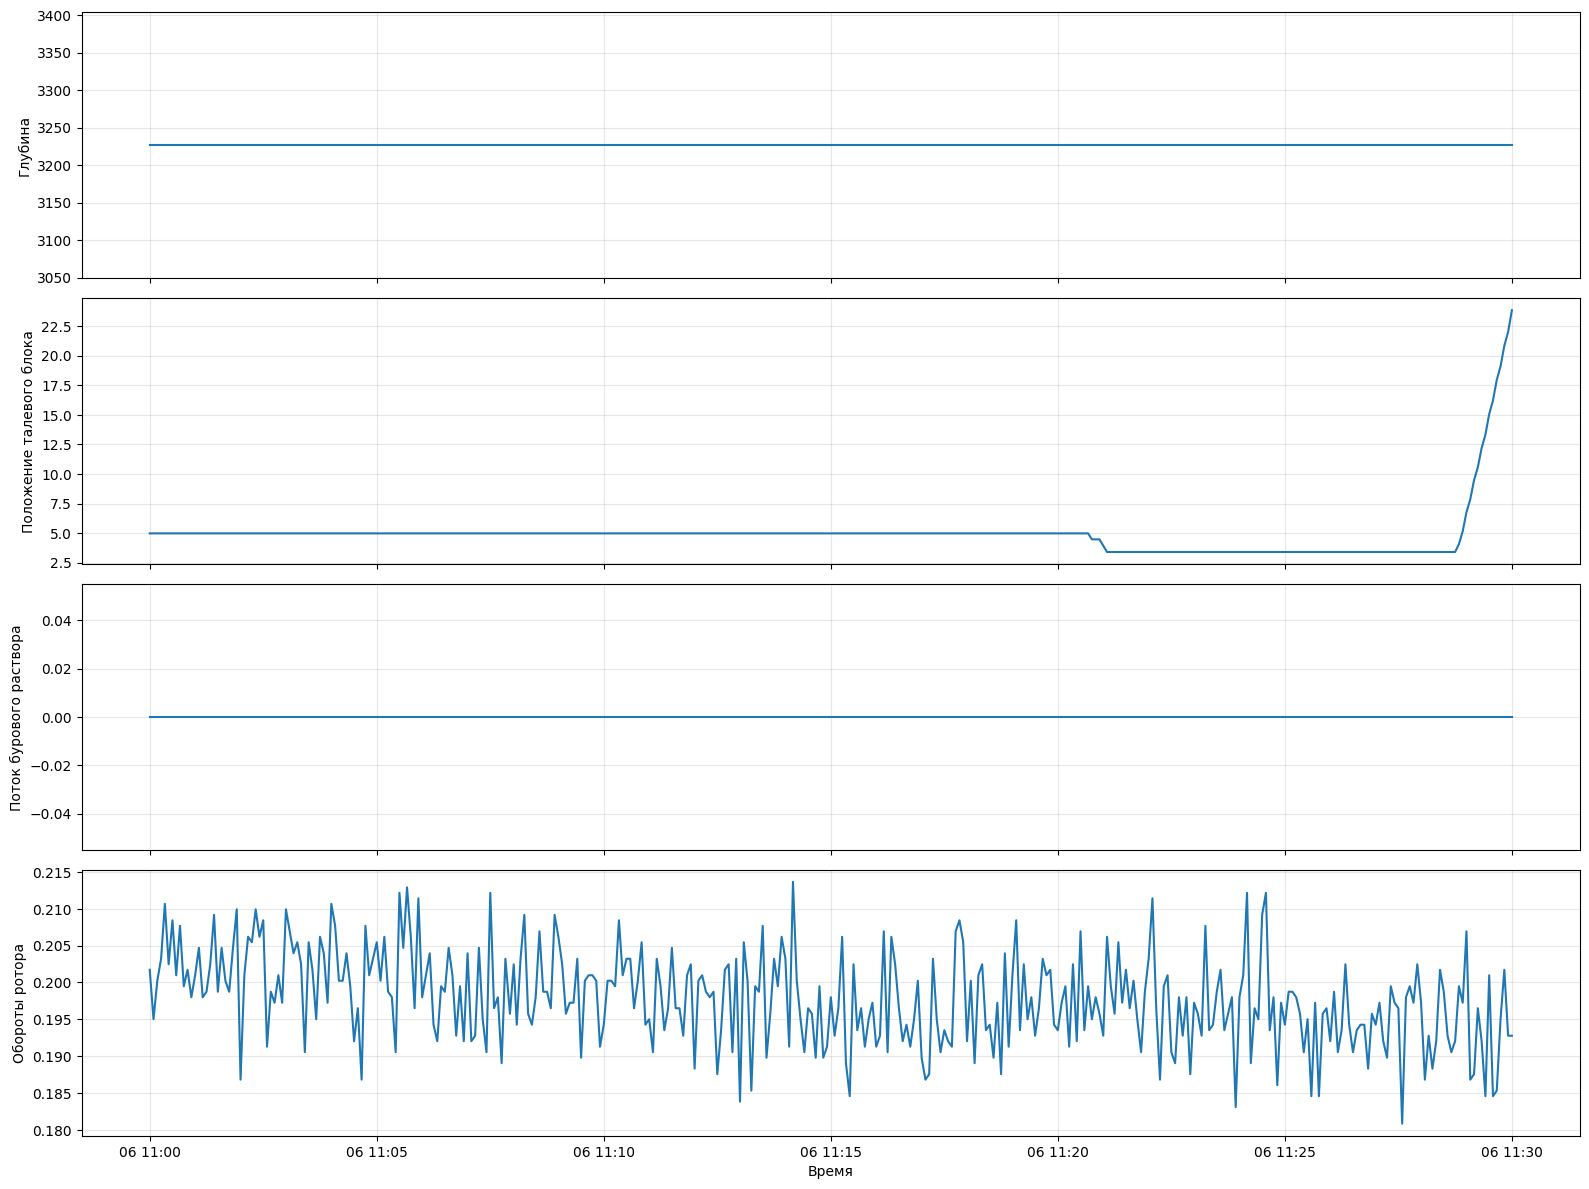

In [ ]:
import matplotlib.pyplot as plt

start_time = df["Time"].iloc[0]
end_time = start_time + pd.Timedelta(minutes=30)

part = df[
    (df["Time"] >= start_time) &
    (df["Time"] <= end_time)
]

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)

signals = [
    ("Depth", "Глубина"),
    ("TravelingBlockPosition", "Положение талевого блока"),
    ("InletFlow", "Поток бурового раствора"),
    ("Turn_rotor", "Обороты ротора"),
]

for ax, (column, title) in zip(axes, signals):
    ax.plot(part["Time"], part[column])
    ax.set_ylabel(title)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Время")
plt.tight_layout()
plt.show()


In [ ]:
# Сначала упорядочиваем данные по ID.
df = df.sort_values("ID").reset_index(drop=True)

# Временной интервал между соседними строками.
df["dt_sec"] = df["Time"].diff().dt.total_seconds()

# Используем только интервалы от 1 до 10 секунд.
normal_step = df["dt_sec"].between(1, 10)

# Исходные числовые признаки.
base_columns = [
    "Depth",
    "HL",
    "TravelingBlockPosition",
    "ManifoldPressure",
    "ROP",
    "InletFlow",
    "Load",
    "BitPosition",
    "WedgePosition",
    "Turn_rotor",
]

features = df[base_columns].copy()

# Производные: изменение параметра за секунду.
safe_dt = df["dt_sec"].where(normal_step)

features["d_depth"] = df["Depth"].diff() / safe_dt
features["d_block"] = df["TravelingBlockPosition"].diff() / safe_dt
features["d_bit"] = df["BitPosition"].diff() / safe_dt
features["d_hl"] = df["HL"].diff() / safe_dt

print("Размер матрицы признаков:", features.shape)
print("Количество NaN по столбцам:")
print(features.isna().sum())

print("\nКоличество бесконечных значений:")
print(features.isin([float("inf"), float("-inf")]).sum())

Размер матрицы признаков: (180901, 14)
Количество NaN по столбцам:
Depth                      0
HL                         0
TravelingBlockPosition     0
ManifoldPressure           0
ROP                        0
InletFlow                  0
Load                       0
BitPosition                0
WedgePosition              0
Turn_rotor                 0
d_depth                   20
d_block                   20
d_bit                     20
d_hl                      20
dtype: int64

Количество бесконечных значений:
Depth                     0
HL                        0
TravelingBlockPosition    0
ManifoldPressure          0
ROP                       0
InletFlow                 0
Load                      0
BitPosition               0
WedgePosition             0
Turn_rotor                0
d_depth                   0
d_block                   0
d_bit                     0
d_hl                      0
dtype: int64


In [ ]:
gap_rows = df.index[df["dt_sec"] > 10].tolist()

for i in gap_rows:
    print("\n" + "=" * 70)
    print("Интервал:", df.loc[i, "dt_sec"], "секунд")
    print("Строки вокруг разрыва:")

    left = max(0, i - 3)
    right = min(len(df), i + 4)

    display(
        df.loc[
            left:right - 1,
            [
                "ID",
                "Time",
                "Depth",
                "TravelingBlockPosition",
                "InletFlow",
                "Load",
                "Turn_rotor",
                "dt_sec",
            ],
        ]
    )


Интервал: 21.0 секунд
Строки вокруг разрыва:


,ID,Time,Depth,TravelingBlockPosition,InletFlow,Load,Turn_rotor,dt_sec
806,807,2026-05-06 12:07:10,3226.47998,25.530312,0.0,0.0,0.168906,5.0
807,808,2026-05-06 12:07:15,3226.47998,25.530312,0.0,0.0,0.162192,5.0
808,809,2026-05-06 12:07:20,3226.47998,25.530312,0.0,0.0,0.174873,5.0
809,810,2026-05-06 12:07:41,3226.47998,25.530312,0.0,0.0,0.170025,21.0
810,811,2026-05-06 12:07:42,3226.47998,25.530312,0.0,0.0,0.156971,1.0
811,812,2026-05-06 12:07:43,3226.47998,25.530312,0.0,0.0,0.160701,1.0
812,813,2026-05-06 12:07:44,3226.47998,25.530312,0.0,0.0,0.168160,1.0



Интервал: 11.0 секунд
Строки вокруг разрыва:


,ID,Time,Depth,TravelingBlockPosition,InletFlow,Load,Turn_rotor,dt_sec
31610,31611,2026-05-08 06:54:10,3244.400635,22.821953,12.158113,3.030375,0.138323,5.0
31611,31612,2026-05-08 06:54:15,3244.400635,22.821953,12.158113,3.030375,0.138323,5.0
31612,31613,2026-05-08 06:54:20,3244.400635,22.821953,12.158113,3.030375,0.130863,5.0
31613,31614,2026-05-08 06:54:31,3244.461182,22.821953,12.158113,3.030375,0.136458,11.0
31614,31615,2026-05-08 06:54:32,3244.461182,22.821953,12.158113,3.030375,0.130863,1.0
31615,31616,2026-05-08 06:54:35,3244.461182,22.821953,12.158113,3.030375,0.132728,3.0
31616,31617,2026-05-08 06:54:40,3244.476074,22.821953,12.158113,3.030375,0.136458,5.0



Интервал: 11.0 секунд
Строки вокруг разрыва:


,ID,Time,Depth,TravelingBlockPosition,InletFlow,Load,Turn_rotor,dt_sec
34926,34927,2026-05-08 11:30:30,3277.941162,15.996601,11.239665,10.026069,0.188673,5.0
34927,34928,2026-05-08 11:30:35,3277.941162,15.996601,11.239665,10.026069,0.188673,5.0
34928,34929,2026-05-08 11:30:40,3277.941162,15.996601,11.239665,8.984913,0.199862,5.0
34929,34930,2026-05-08 11:30:51,3277.941162,15.996601,11.239665,8.984913,0.203591,11.0
34930,34931,2026-05-08 11:30:52,3277.941162,15.996601,11.239665,8.984913,0.186808,1.0
34931,34932,2026-05-08 11:30:55,3277.941162,15.996601,11.239665,8.984913,0.184943,3.0
34932,34933,2026-05-08 11:31:00,3277.941162,15.996601,11.239665,8.984913,0.214780,5.0


... (24 outputs left out)


Интервал: 1479.0 секунд
Строки вокруг разрыва:


,ID,Time,Depth,TravelingBlockPosition,InletFlow,Load,Turn_rotor,dt_sec
162483,162484,2026-05-15 20:40:15,3610.932129,8.525820,0.0,51.702366,0.088845,5.0
162484,162485,2026-05-15 20:40:20,3610.932129,8.525820,0.0,51.702236,0.086922,5.0
162485,162486,2026-05-15 20:40:25,3610.932129,8.525820,0.0,51.702236,0.090768,5.0
162486,162487,2026-05-15 21:05:04,3610.932129,6.886992,0.0,0.000000,0.090768,1479.0
162487,162488,2026-05-15 21:05:05,3610.932129,6.886992,0.0,0.000000,0.077307,1.0
162488,162489,2026-05-15 21:05:06,3610.932129,6.886992,0.0,0.000000,0.109998,1.0
162489,162490,2026-05-15 21:05:07,3610.932129,6.886992,0.0,0.000000,0.098460,1.0



Интервал: 477.0 секунд
Строки вокруг разрыва:


,ID,Time,Depth,TravelingBlockPosition,InletFlow,Load,Turn_rotor,dt_sec
167362,167363,2026-05-16 03:26:50,3610.932129,27.450077,0.0,0.65943,0.200380,5.0
167363,167364,2026-05-16 03:26:55,3610.932129,27.450077,0.0,0.65943,0.188842,5.0
167364,167365,2026-05-16 03:27:00,3610.932129,27.450077,0.0,0.65943,0.194611,5.0
167365,167366,2026-05-16 03:34:57,3610.929932,22.566328,0.0,0.00000,0.106152,477.0
167366,167367,2026-05-16 03:34:58,3610.929932,21.950859,0.0,0.00000,0.106152,1.0
167367,167368,2026-05-16 03:34:59,3610.929932,21.280975,0.0,0.00000,0.106152,1.0
167368,167369,2026-05-16 03:35:00,3610.929932,20.540077,0.0,0.00000,0.108075,1.0


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

# Берём только исходные числовые параметры.
# ID и Time не используем как признаки.
base_columns = [
    "Depth",
    "HL",
    "TravelingBlockPosition",
    "ManifoldPressure",
    "ROP",
    "InletFlow",
    "Load",
    "BitPosition",
    "WedgePosition",
    "Turn_rotor",
]

X = df[base_columns].copy()

# Проверяем, что в исходных признаках нет пропусков.
print("Пропуски в исходных признаках:", X.isna().sum().sum())

# Приводим признаки к сопоставимому масштабу.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Строим модель ровно на 9 кластеров.
kmeans = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X_scaled)

# Сохраняем предсказанные кластеры.
df["cluster_baseline"] = labels

print("Количество строк:", len(labels))
print("Количество кластеров:", len(np.unique(labels)))
print("\nРазмеры кластеров:")

cluster_sizes = (
    pd.Series(labels)
    .value_counts()
    .sort_index()
    .rename("Количество строк")
)

cluster_sizes.index.name = "Кластер"
display(cluster_sizes.to_frame())

print(
    "Доля самого большого кластера:",
    round(cluster_sizes.max() / len(labels) * 100, 2),
    "%"
)

Пропуски в исходных признаках: 0
Количество строк: 180901
Количество кластеров: 9

Размеры кластеров:


,Количество строк
Кластер,
0,17758
1,26145
2,16768
3,52507
4,14458
5,19194
6,14950
7,9349
8,9772


Доля самого большого кластера: 29.03 %


In [ ]:
labels = df["cluster_baseline"].to_numpy()

# Сколько раз подряд идущие строки получили разные метки.
switches = np.sum(labels[1:] != labels[:-1])

print("Всего переключений между кластерами:", switches)
print(
    "Переключений на 1000 строк:",
    round(switches / (len(labels) - 1) * 1000, 2)
)

# Показываем распределение длин непрерывных участков одного кластера.
change_points = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1, len(labels)]
segment_lengths = np.diff(change_points)

print("\nДлина непрерывных участков, в строках:")
print(pd.Series(segment_lengths).describe(
    percentiles=[0.5, 0.9, 0.99]
))

Всего переключений между кластерами: 2708
Переключений на 1000 строк: 14.97

Длина непрерывных участков, в строках:
count     2709.000000
mean        66.777778
std        603.579872
min          1.000000
50%         14.000000
90%         86.200000
99%        628.520000
max      25952.000000
dtype: float64


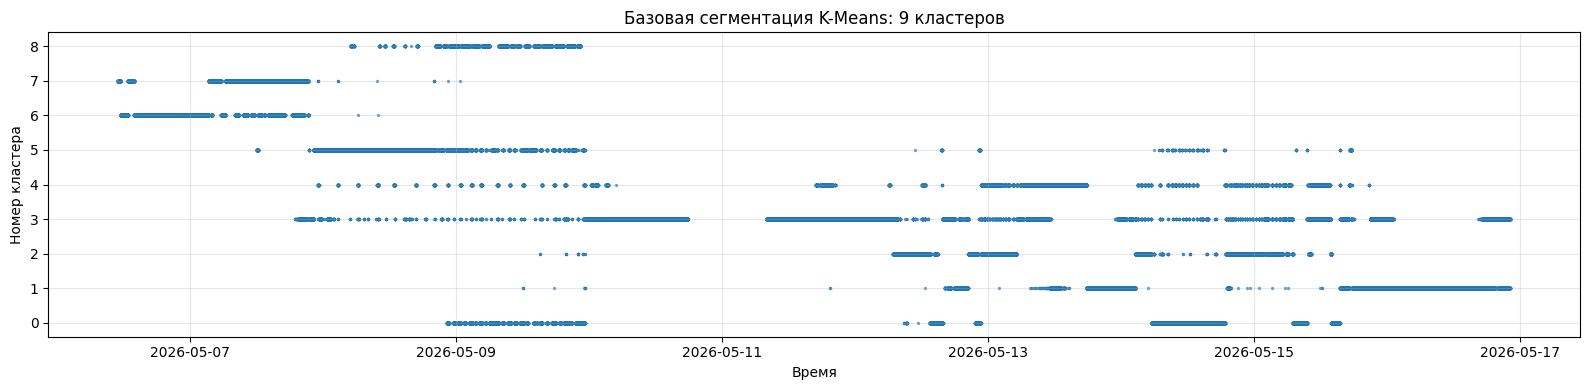

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 4))

plt.scatter(
    df["Time"],
    df["cluster_baseline"],
    s=2,
    alpha=0.6
)

plt.xlabel("Время")
plt.ylabel("Номер кластера")
plt.title("Базовая сегментация K-Means: 9 кластеров")
plt.yticks(range(9))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Размеры кластеров с производными:


,Количество строк
0,24436
1,30060
2,52075
3,21512
4,13513
5,21696
6,2643
7,10438
8,4528


Всего переключений: 7883
Переключений на 1000 строк: 43.58
Медианная длина сегмента: 4
Средняя длина сегмента: 22.95


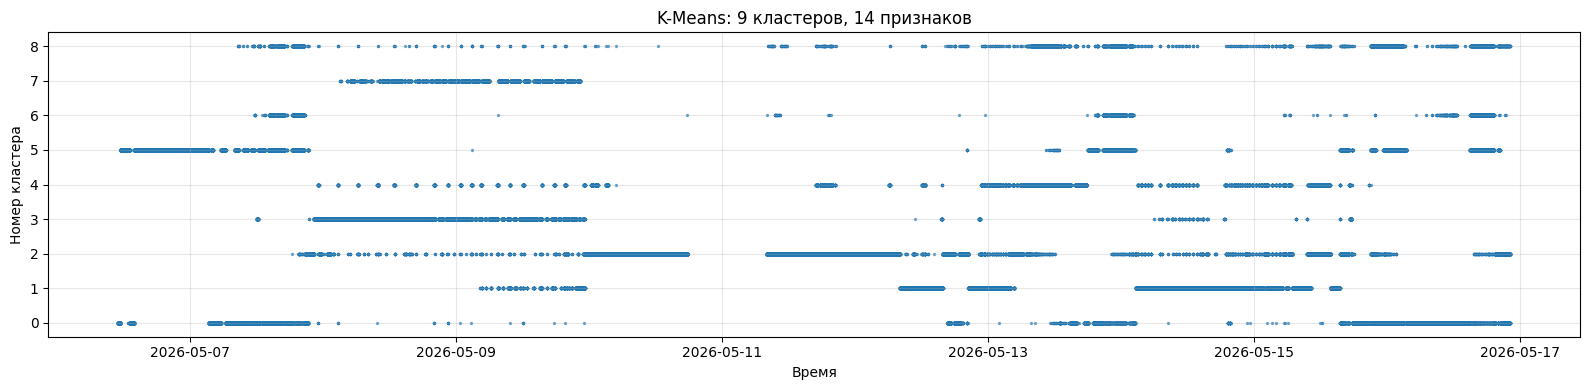

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Используем 10 исходных и 4 производных признака.
X_all = features.copy()

# Заполняем пропуски медианой каждого столбца.
# Исходные строки не удаляем.
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_all)

# Масштабируем признаки.
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_imputed)

# Та же модель, что и в первом эксперименте.
kmeans_all = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

labels_all = kmeans_all.fit_predict(X_all_scaled)
df["cluster_with_derivatives"] = labels_all

# Размеры кластеров.
sizes_all = (
    pd.Series(labels_all)
    .value_counts()
    .sort_index()
    .rename("Количество строк")
)

print("Размеры кластеров с производными:")
display(sizes_all.to_frame())

# Число переключений между соседними строками.
switches_all = np.sum(labels_all[1:] != labels_all[:-1])

change_points_all = np.r_[
    0,
    np.where(labels_all[1:] != labels_all[:-1])[0] + 1,
    len(labels_all)
]

lengths_all = np.diff(change_points_all)

print("Всего переключений:", switches_all)
print(
    "Переключений на 1000 строк:",
    round(switches_all / (len(labels_all) - 1) * 1000, 2)
)
print("Медианная длина сегмента:", int(np.median(lengths_all)))
print("Средняя длина сегмента:", round(np.mean(lengths_all), 2))

# График новой сегментации.
plt.figure(figsize=(16, 4))
plt.scatter(df["Time"], labels_all, s=2, alpha=0.6)
plt.xlabel("Время")
plt.ylabel("Номер кластера")
plt.title("K-Means: 9 кластеров, 14 признаков")
plt.yticks(range(9))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Размеры кластеров:


,Количество строк
0,17614
1,26148
2,16753
3,52461
4,14459
5,10029
6,14905
7,9445
8,19087


Всего переключений: 3160
Переключений на 1000 строк: 17.47
Медианная длина сегмента: 11
Средняя длина сегмента: 57.23


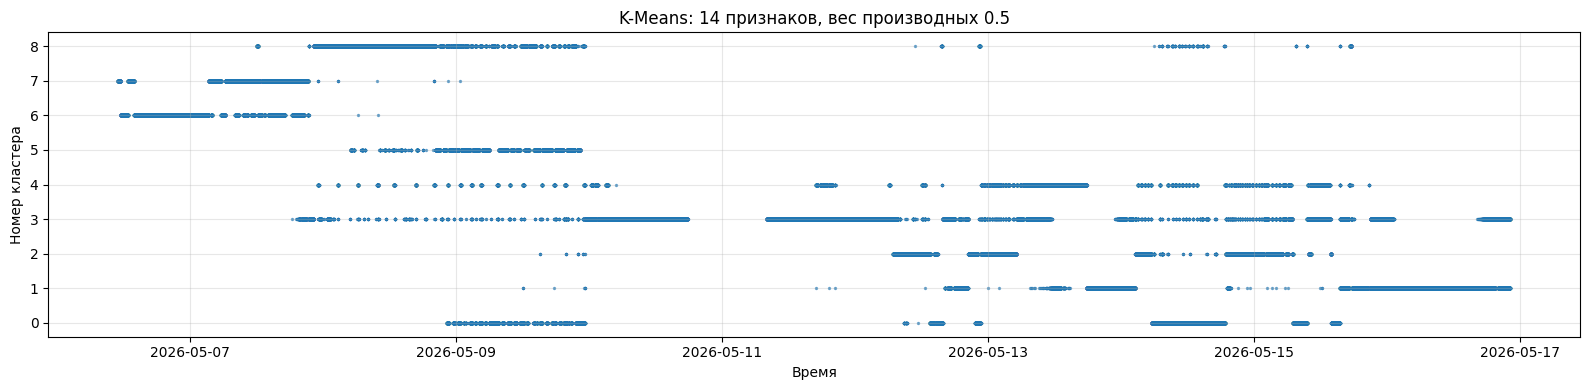

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Разделяем исходные признаки и производные.
derivative_columns = [
    "d_depth",
    "d_block",
    "d_bit",
    "d_hl",
]

# Заполняем пропуски медианами.
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(features)

# Масштабируем все 14 признаков.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Преобразуем в DataFrame, чтобы обращаться к столбцам по именам.
X_weighted = pd.DataFrame(
    X_scaled,
    columns=features.columns
)

# Уменьшаем вклад производных в расстояние.
derivative_weight = 0.5
X_weighted[derivative_columns] *= derivative_weight

# Обучаем K-Means.
kmeans_weighted = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

labels_weighted = kmeans_weighted.fit_predict(X_weighted)
df["cluster_weighted"] = labels_weighted

# Анализируем размеры кластеров.
sizes = pd.Series(labels_weighted).value_counts().sort_index()

print("Размеры кластеров:")
display(sizes.rename("Количество строк").to_frame())

# Анализируем переключения.
switches = np.sum(labels_weighted[1:] != labels_weighted[:-1])

change_points = np.r_[
    0,
    np.where(labels_weighted[1:] != labels_weighted[:-1])[0] + 1,
    len(labels_weighted)
]

segment_lengths = np.diff(change_points)

print("Всего переключений:", switches)
print(
    "Переключений на 1000 строк:",
    round(switches / (len(labels_weighted) - 1) * 1000, 2)
)
print("Медианная длина сегмента:", int(np.median(segment_lengths)))
print("Средняя длина сегмента:", round(np.mean(segment_lengths), 2))

# Строим график.
plt.figure(figsize=(16, 4))
plt.scatter(df["Time"], labels_weighted, s=2, alpha=0.6)
plt.xlabel("Время")
plt.ylabel("Номер кластера")
plt.title("K-Means: 14 признаков, вес производных 0.5")
plt.yticks(range(9))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Используем метки модели с весом производных 0.5.
analysis_df = df[base_columns + ["cluster_weighted"]].copy()

# Средние значения исходных признаков в каждом кластере.
cluster_means = (
    analysis_df
    .groupby("cluster_weighted")[base_columns]
    .mean()
    .round(3)
)

display(cluster_means)

# Медианы помогут увидеть типичные значения,
# которые меньше зависят от экстремальных наблюдений.
cluster_medians = (
    analysis_df
    .groupby("cluster_weighted")[base_columns]
    .median()
    .round(3)
)

display(cluster_medians)

,Depth,HL,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,BitPosition,WedgePosition,Turn_rotor
cluster_weighted,,,,,,,,,,
0,3583.675,61.510,14.855,12.702,1.181,13.722,1.789,56.694,1.031,56.320
1,3610.918,13.714,14.424,0.223,0.832,0.041,0.314,2197.980,0.142,-0.129
2,3610.911,66.385,14.983,3.829,0.838,4.872,0.539,181.906,0.999,43.916
3,3599.948,68.706,17.304,0.354,0.854,0.138,2.657,116.340,0.858,-2.259
4,3591.258,12.468,18.976,0.408,0.873,0.103,45.144,1268.928,0.024,1.185
5,3466.609,53.907,13.393,18.468,18.397,13.710,2.682,0.538,1.047,32.386
6,3226.484,10.752,27.607,0.207,0.372,0.001,0.002,2981.008,-0.101,0.174
7,3226.564,9.563,4.738,0.238,0.375,0.037,0.011,2737.478,-0.101,0.121
8,3323.595,55.332,14.390,13.290,4.469,12.515,3.102,34.053,1.065,7.483


,Depth,HL,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,BitPosition,WedgePosition,Turn_rotor
cluster_weighted,,,,,,,,,,
0,3610.932,62.629,14.394,12.364,0.832,13.838,1.022,16.554,1.000,63.002
1,3610.932,11.732,13.619,0.172,0.832,0.000,0.000,2753.705,-0.012,0.137
2,3610.932,66.667,14.782,3.418,0.832,4.101,0.385,160.725,1.000,42.620
3,3610.932,64.719,17.272,0.246,0.832,0.000,0.876,18.567,1.000,0.327
4,3610.932,11.931,25.875,0.246,0.832,0.000,48.854,378.546,-0.019,0.233
5,3474.709,54.861,14.127,19.049,18.202,13.849,2.764,0.234,1.000,40.530
6,3226.480,11.171,28.362,0.175,0.372,0.000,0.000,3226.000,0.015,0.151
7,3226.480,12.403,3.187,0.175,0.372,0.000,0.000,3226.000,-0.009,0.179
8,3290.528,55.518,14.162,14.364,2.365,12.141,1.947,0.872,1.088,0.273


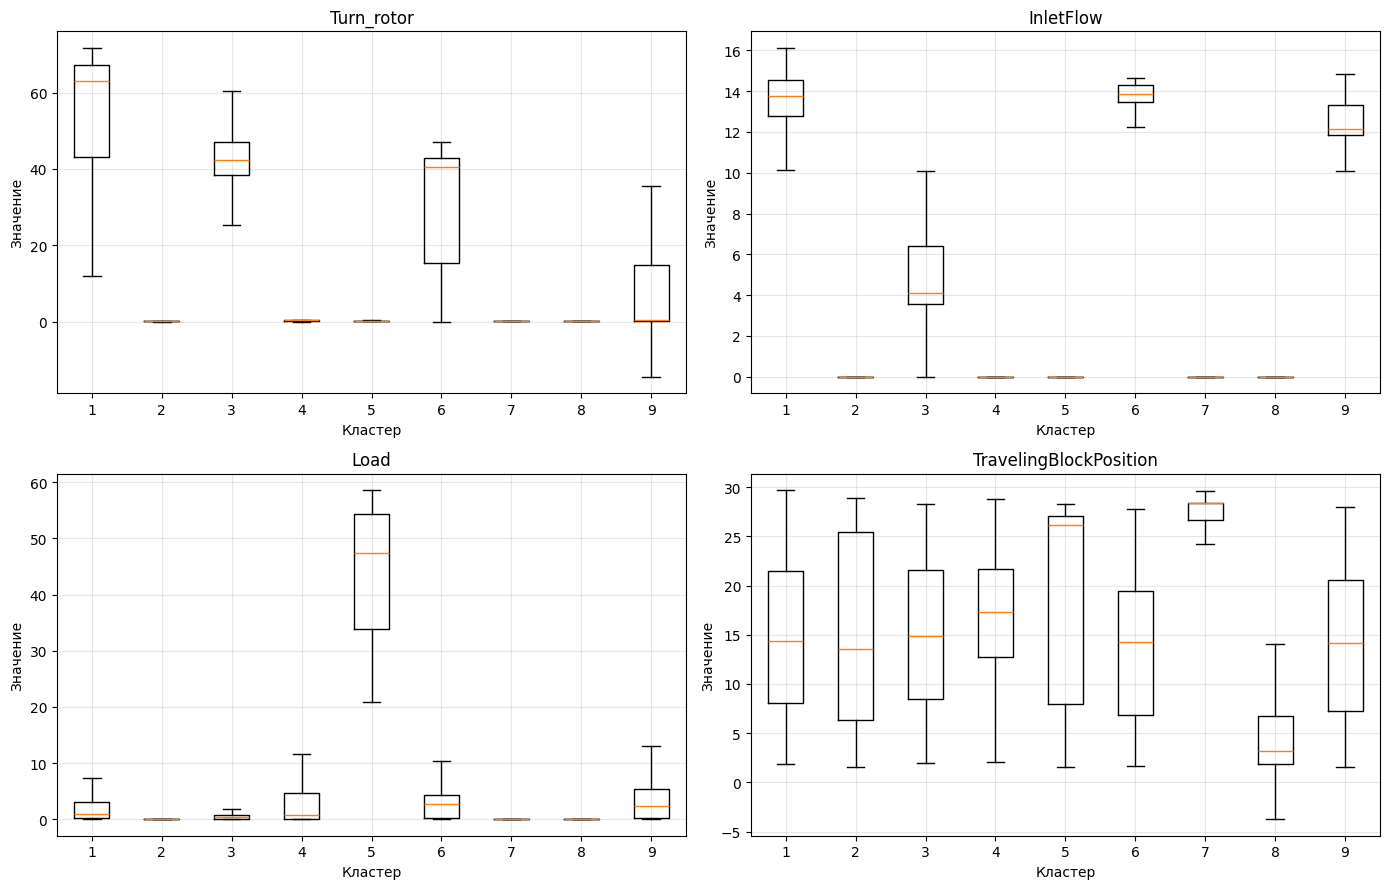

In [ ]:
import matplotlib.pyplot as plt

plot_columns = [
    "Turn_rotor",
    "InletFlow",
    "Load",
    "TravelingBlockPosition",
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, column in zip(axes.flat, plot_columns):
    data = [
        analysis_df.loc[
            analysis_df["cluster_weighted"] == cluster,
            column
        ].sample(
            n=min(
                3000,
                (analysis_df["cluster_weighted"] == cluster).sum()
            ),
            random_state=42
        ).values
        for cluster in range(9)
    ]

    ax.boxplot(data, showfliers=False)
    ax.set_title(column)
    ax.set_xlabel("Кластер")
    ax.set_ylabel("Значение")
    ax.set_xticks(range(1, 10))
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

labels = df["cluster_weighted"].to_numpy()

# Сравниваем два разбиения:
# базовое — 10 исходных признаков;
# weighted — 14 признаков с уменьшенным весом производных.
ari_between_models = adjusted_rand_score(
    df["cluster_baseline"],
    df["cluster_weighted"]
)

print(
    "Сходство двух разбиений (ARI):",
    round(ari_between_models, 4)
)

# Считаем переходы между соседними метками.
transitions = pd.DataFrame({
    "from": labels[:-1],
    "to": labels[1:],
})

transition_counts = (
    transitions[transitions["from"] != transitions["to"]]
    .value_counts()
    .rename("Количество переходов")
    .reset_index()
    .sort_values("Количество переходов", ascending=False)
)

print("\n20 самых частых переходов:")
display(transition_counts.head(20))

Сходство двух разбиений (ARI): 0.9891

20 самых частых переходов:


,from,to,Количество переходов
0,3,1,373
1,1,3,355
2,4,3,318
3,3,4,279
4,5,8,230
5,8,5,230
6,7,6,161
7,6,7,129
8,0,8,122
9,8,0,117


In [ ]:
# Ищем моменты, когда меняется метка кластера.
labels = df["cluster_weighted"].to_numpy()
boundary_indices = np.where(labels[1:] != labels[:-1])[0] + 1

# Берём несколько границ из разных частей датасета.
if len(boundary_indices) > 0:
    positions = np.linspace(
        0,
        len(boundary_indices) - 1,
        num=min(8, len(boundary_indices)),
        dtype=int
    )

    selected_boundaries = boundary_indices[positions]

    for i in selected_boundaries:
        left = max(0, i - 3)
        right = min(len(df), i + 4)

        print(
            f"\nID около границы: {df.loc[i, 'ID']}; "
            f"переход {labels[i - 1]} -> {labels[i]}"
        )

        display(
            df.loc[
                left:right - 1,
                [
                    "ID",
                    "Time",
                    "Depth",
                    "TravelingBlockPosition",
                    "ManifoldPressure",
                    "ROP",
                    "InletFlow",
                    "Load",
                    "Turn_rotor",
                    "cluster_weighted",
                ],
            ]
        )


ID около границы: 356; переход 7 -> 6


,ID,Time,Depth,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,Turn_rotor,cluster_weighted
352,353,2026-05-06 11:29:20,3226.47998,12.188867,0.174925,0.371958,0.0,0.0,0.192030,7
353,354,2026-05-06 11:29:25,3226.47998,13.321757,0.174925,0.371958,0.0,0.0,0.184570,7
354,355,2026-05-06 11:29:30,3226.47998,15.059218,0.174925,0.371958,0.0,0.0,0.200981,7
355,356,2026-05-06 11:29:35,3226.47998,16.216719,0.174925,0.371958,0.0,0.0,0.184570,6
356,357,2026-05-06 11:29:40,3226.47998,17.951796,0.174925,0.371958,0.0,0.0,0.185316,6
357,358,2026-05-06 11:29:45,3226.47998,19.109297,0.174925,0.371958,0.0,0.0,0.195013,6
358,359,2026-05-06 11:29:50,3226.47998,20.844414,0.174925,0.371958,0.0,0.0,0.201727,6



ID около границы: 30652; переход 8 -> 5


,ID,Time,Depth,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,Turn_rotor,cluster_weighted
30648,30649,2026-05-08 05:34:00,3237.615479,5.256992,13.474798,12.925591,12.110220,5.334900,0.252077,8
30649,30650,2026-05-08 05:34:05,3237.626465,5.256992,13.190173,12.925591,12.110220,5.334900,0.255807,8
30650,30651,2026-05-08 05:34:10,3237.635498,5.256992,12.745055,12.925591,12.110220,4.322258,0.244618,8
30651,30652,2026-05-08 05:34:15,3237.688721,5.256992,12.637796,12.925591,12.110220,4.322258,0.246482,5
30652,30653,2026-05-08 05:34:20,3237.766113,5.256992,12.530092,12.925591,12.110220,5.419264,0.252077,5
30653,30654,2026-05-08 05:34:25,3237.821533,4.756484,12.665180,12.925591,12.158931,5.419264,0.242753,5
30654,30655,2026-05-08 05:34:30,3237.874512,4.756484,12.915510,12.925591,12.158931,6.476059,0.244618,5



ID около границы: 44117; переход 5 -> 8


,ID,Time,Depth,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,Turn_rotor,cluster_weighted
44113,44114,2026-05-09 00:16:05,3385.234863,9.619883,15.064975,12.407880,13.555178,0.0,43.176609,5
44114,44115,2026-05-09 00:16:10,3385.234863,9.619883,15.173532,12.407880,13.555178,0.0,43.598057,5
44115,44116,2026-05-09 00:16:15,3385.234863,9.619883,15.173532,12.407880,13.555178,0.0,43.217632,5
44116,44117,2026-05-09 00:16:20,3385.234863,9.619883,15.173532,11.341311,13.555178,0.0,43.144905,8
44117,44118,2026-05-09 00:16:25,3385.234863,9.101641,15.070950,11.341311,13.555178,0.0,42.770077,8
44118,44119,2026-05-09 00:16:30,3385.234863,9.101641,15.201723,10.325027,13.555178,0.0,43.954239,8
44119,44120,2026-05-09 00:16:35,3385.234863,9.101641,15.201723,10.325027,13.555178,0.0,42.790588,8


... (6 outputs left out)


ID около границы: 158735; переход 8 -> 4


,ID,Time,Depth,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,Turn_rotor,cluster_weighted
158731,158732,2026-05-15 15:27:35,3610.932129,26.238241,13.190677,0.832193,15.815451,2.010203,0.104229,8
158732,158733,2026-05-15 15:27:40,3610.932129,26.238241,13.190677,0.832193,15.815451,2.010203,0.075384,8
158733,158734,2026-05-15 15:27:45,3610.932129,26.238241,13.190677,0.832193,15.815451,2.010203,0.098460,8
158734,158735,2026-05-15 15:27:50,3610.932129,26.238241,13.190677,0.832193,15.815451,32.744041,0.081153,4
158735,158736,2026-05-15 15:27:55,3610.932129,26.238241,13.190677,0.832193,15.815451,43.214787,0.098460,4
158736,158737,2026-05-15 15:28:00,3610.932129,26.238241,13.190677,0.832193,15.815451,49.063267,0.109998,4
158737,158738,2026-05-15 15:28:05,3610.932129,26.238241,12.092402,0.832193,10.628613,49.063267,0.098460,4



ID около границы: 180893; переход 1 -> 3


,ID,Time,Depth,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,Turn_rotor,cluster_weighted
180889,180890,2026-05-16 22:14:05,3610.929932,3.951680,0.280601,0.832193,0.0,0.0,0.042693,1
180890,180891,2026-05-16 22:14:10,3610.929932,3.951680,0.280601,0.832193,0.0,0.0,0.040770,1
180891,180892,2026-05-16 22:14:15,3610.929932,3.951680,0.280601,0.832193,0.0,0.0,0.048462,1
180892,180893,2026-05-16 22:14:20,3610.929932,3.951680,0.280601,0.832193,0.0,0.0,0.042693,3
180893,180894,2026-05-16 22:14:25,3610.929932,3.951680,0.280601,0.832193,0.0,0.0,0.044616,3
180894,180895,2026-05-16 22:14:30,3610.929932,3.289961,0.280601,0.832193,0.0,0.0,0.044616,3
180895,180896,2026-05-16 22:14:35,3610.929932,3.289961,0.280601,0.832193,0.0,0.0,0.044616,3


In [ ]:
import numpy as np
import pandas as pd

# Исходные измеряемые признаки — без ID, времени и производных.
sensor_cols = [
    "Depth",
    "HL",
    "TravelingBlockPosition",
    "ManifoldPressure",
    "ROP",
    "InletFlow",
    "Load",
    "BitPosition",
    "WedgePosition",
    "Turn_rotor",
]

# Сортируем данные в хронологическом порядке.
df = df.sort_values("ID").reset_index(drop=True)

X = df[sensor_cols].astype(float)
labels = df["cluster_weighted"].to_numpy()

# Масштабируем изменения на межквартильный размах каждого признака.
# Это позволяет сравнивать признаки с разными единицами измерения.
iqr = X.quantile(0.75) - X.quantile(0.25)
iqr = iqr.replace(0, np.nan)

normalized_change = X.diff().abs().div(iqr, axis=1)

# Индексы строк, на которых начинается новый кластер.
boundary_idx = np.flatnonzero(labels[1:] != labels[:-1]) + 1

boundaries = pd.DataFrame({
    "ID": df.loc[boundary_idx, "ID"].to_numpy(),
    "Time": df.loc[boundary_idx, "Time"].to_numpy(),
    "from": labels[boundary_idx - 1],
    "to": labels[boundary_idx],
    "change_score": (
        normalized_change.iloc[boundary_idx]
        .mean(axis=1)
        .to_numpy()
    ),
})

# Добавляем длительность интервала до границы.
boundaries["dt_sec"] = (
    df["Time"].diff().dt.total_seconds().iloc[boundary_idx].to_numpy()
)

# Смотрим на границы с наименьшим и наибольшим изменением сигналов.
print("10 переходов с наименьшим изменением признаков:")
display(
    boundaries.sort_values("change_score")
    .head(10)
    .round(4)
)

print("10 переходов с наибольшим изменением признаков:")
display(
    boundaries.sort_values("change_score", ascending=False)
    .head(10)
    .round(4)
)

10 переходов с наименьшим изменением признаков:


,ID,Time,from,to,change_score,dt_sec
178,21130,2026-05-07 16:20:45,7,6,0.0001,5.0
743,38088,2026-05-08 15:53:55,5,8,0.0001,5.0
1207,57381,2026-05-09 18:41:40,8,5,0.0001,5.0
1131,53023,2026-05-09 12:38:30,5,8,0.0001,5.0
1251,58670,2026-05-09 20:29:05,5,0,0.0002,5.0
645,36122,2026-05-08 13:10:05,5,8,0.0002,5.0
1221,57572,2026-05-09 18:57:35,0,5,0.0002,5.0
775,38970,2026-05-08 17:07:25,8,5,0.0002,5.0
1197,56944,2026-05-09 18:05:15,5,0,0.0002,5.0
1206,57380,2026-05-09 18:41:35,5,8,0.0002,5.0


10 переходов с наибольшим изменением признаков:


,ID,Time,from,to,change_score,dt_sec
1758,115814,2026-05-13 03:51:05,4,3,2.0737,5.0
1734,114737,2026-05-13 02:21:20,4,3,2.0675,5.0
2335,137037,2026-05-14 09:19:40,4,3,2.0639,5.0
1740,115046,2026-05-13 02:47:05,4,3,2.0486,5.0
1827,118955,2026-05-13 08:12:50,4,3,2.0112,5.0
1821,118850,2026-05-13 08:04:05,4,3,2.0062,5.0
1746,115361,2026-05-13 03:13:20,4,3,2.0057,5.0
1707,113638,2026-05-13 00:49:45,4,3,2.0029,5.0
1805,118496,2026-05-13 07:34:35,4,3,1.9970,5.0
1788,118098,2026-05-13 07:01:25,4,3,1.9930,5.0


In [ ]:
import numpy as np
import pandas as pd

sensor_cols = [
    "Depth", "HL", "TravelingBlockPosition",
    "ManifoldPressure", "ROP", "InletFlow",
    "Load", "BitPosition", "WedgePosition", "Turn_rotor"
]

df = df.sort_values("ID").reset_index(drop=True)

X = df[sensor_cols].astype(float)
labels = df["cluster_weighted"].to_numpy()

# Типичный разброс каждого признака.
iqr = X.quantile(0.75) - X.quantile(0.25)
iqr = iqr.replace(0, np.nan)

# Находим все переключения кластеров.
boundary_idx = np.flatnonzero(labels[1:] != labels[:-1]) + 1

# Считаем, насколько изменился каждый признак на границе.
changes = X.diff().abs().div(iqr, axis=1)

boundary_scores = changes.iloc[boundary_idx].mean(axis=1).to_numpy()

boundaries = pd.DataFrame({
    "idx": boundary_idx,
    "ID": df.loc[boundary_idx, "ID"].to_numpy(),
    "from": labels[boundary_idx - 1],
    "to": labels[boundary_idx],
    "score": boundary_scores
})

# Берём три перехода с наименьшим и три с наибольшим score.
selected = pd.concat([
    boundaries.nsmallest(3, "score"),
    boundaries.nlargest(3, "score")
])

for _, b in selected.iterrows():
    i = int(b["idx"])

    print(
        f"\nID={int(b['ID'])}: "
        f"{int(b['from'])} -> {int(b['to'])}; "
        f"score={b['score']:.4f}"
    )

    before = X.iloc[i - 1]
    after = X.iloc[i]

    result = pd.DataFrame({
        "до перехода": before,
        "после перехода": after,
        "абсолютное изменение": (after - before).abs(),
        "изменение относительно IQR": changes.iloc[i]
    })

    display(
        result.sort_values(
            "изменение относительно IQR",
            ascending=False
        ).round(4)
    )


ID=21130: 7 -> 6; score=0.0001


,до перехода,после перехода,абсолютное изменение,изменение относительно IQR
HL,11.4456,11.4051,0.0405,0.0008
WedgePosition,-0.0048,-0.0045,0.0003,0.0003
Depth,3226.4800,3226.4800,0.0000,0.0000
ManifoldPressure,0.3511,0.3511,0.0000,0.0000
TravelingBlockPosition,27.0545,27.0545,0.0000,0.0000
InletFlow,0.0000,0.0000,0.0000,0.0000
Load,0.0000,0.0000,0.0000,0.0000
BitPosition,2012.0610,2012.0610,0.0000,0.0000
Turn_rotor,0.2204,0.2204,0.0000,0.0000
ROP,0.3720,0.3720,0.0000,NaN



ID=38088: 5 -> 8; score=0.0001


,до перехода,после перехода,абсолютное изменение,изменение относительно IQR
WedgePosition,1.1448,1.1456,0.0007,0.0007
Turn_rotor,0.1924,0.1887,0.0037,0.0002
HL,36.5154,36.5217,0.0063,0.0001
Depth,3309.8384,3309.8384,0.0000,0.0000
TravelingBlockPosition,7.2014,7.2014,0.0000,0.0000
InletFlow,12.0369,12.0369,0.0000,0.0000
ManifoldPressure,14.8467,14.8467,0.0000,0.0000
BitPosition,0.3123,0.3123,0.0000,0.0000
Load,8.4102,8.4102,0.0000,0.0000
ROP,10.3975,10.3975,0.0000,NaN



ID=57381: 8 -> 5; score=0.0001


,до перехода,после перехода,абсолютное изменение,изменение относительно IQR
Depth,3574.4700,3574.6260,0.1560,0.0007
HL,42.7312,42.7098,0.0214,0.0004
Turn_rotor,0.1831,0.1812,0.0019,0.0001
ManifoldPressure,17.4204,17.4204,0.0000,0.0000
TravelingBlockPosition,13.5845,13.5845,0.0000,0.0000
InletFlow,13.8487,13.8487,0.0000,0.0000
Load,0.0000,0.0000,0.0000,0.0000
BitPosition,0.1373,0.1373,0.0000,0.0000
WedgePosition,1.0000,1.0000,0.0000,0.0000
ROP,1.0163,1.0163,0.0000,NaN


... (2 outputs left out)


ID=114737: 4 -> 3; score=2.0675


,до перехода,после перехода,абсолютное изменение,изменение относительно IQR
Load,56.5985,0.0000,56.5985,16.1139
HL,10.5531,95.0624,84.5093,1.6049
WedgePosition,-0.0178,0.8740,0.8918,0.8881
Turn_rotor,0.2763,0.2819,0.0056,0.0004
Depth,3610.9321,3610.9321,0.0000,0.0000
InletFlow,0.0000,0.0000,0.0000,0.0000
ManifoldPressure,0.2764,0.2764,0.0000,0.0000
TravelingBlockPosition,3.8728,3.8728,0.0000,0.0000
BitPosition,224.1228,224.1228,0.0000,0.0000
ROP,0.8322,0.8322,0.0000,NaN



ID=137037: 4 -> 3; score=2.0639


,до перехода,после перехода,абсолютное изменение,изменение относительно IQR
Load,56.9239,0.0000,56.9239,16.2065
HL,11.0754,81.1944,70.1190,1.3316
WedgePosition,-0.0266,1.0000,1.0266,1.0223
ManifoldPressure,0.7165,0.8259,0.1094,0.0139
Turn_rotor,0.2409,0.2502,0.0093,0.0006
BitPosition,197.5200,198.0717,0.5517,0.0004
Depth,3610.9321,3610.9321,0.0000,0.0000
InletFlow,0.0000,0.0000,0.0000,0.0000
TravelingBlockPosition,26.8278,26.8278,0.0000,0.0000
ROP,0.8322,0.8322,0.0000,NaN


In [ ]:
import numpy as np
import pandas as pd

sensor_cols = [
    "Depth", "HL", "TravelingBlockPosition",
    "ManifoldPressure", "ROP", "InletFlow",
    "Load", "BitPosition", "WedgePosition", "Turn_rotor"
]

X = df[sensor_cols].astype(float)
labels = df["cluster_weighted"]

# Межквартильный размах каждого датчика.
iqr = X.quantile(0.75) - X.quantile(0.25)
iqr = iqr.replace(0, np.nan)

for a, b in [(5, 8), (6, 7), (3, 4)]:
    print(f"\n{'=' * 60}")
    print(f"Сравнение кластеров {a} и {b}")

    mask_a = labels == a
    mask_b = labels == b

    print(f"Размер кластера {a}: {mask_a.sum()}")
    print(f"Размер кластера {b}: {mask_b.sum()}")

    med_a = X.loc[mask_a].median()
    med_b = X.loc[mask_b].median()

    comparison = pd.DataFrame({
        f"Медиана {a}": med_a,
        f"Медиана {b}": med_b,
        "Разница медиан": (med_a - med_b).abs(),
        "Разница / IQR": (med_a - med_b).abs() / iqr
    })

    display(
        comparison.sort_values(
            "Разница / IQR",
            ascending=False,
            na_position="last"
        ).round(4)
    )


Сравнение кластеров 5 и 8
Размер кластера 5: 10029
Размер кластера 8: 19087


,Медиана 5,Медиана 8,Разница медиан,Разница / IQR
Turn_rotor,40.5304,0.2726,40.2578,2.6076
Depth,3474.7092,3290.5283,184.1809,0.8791
ManifoldPressure,19.0487,14.3636,4.6851,0.5953
Load,2.7637,1.9465,0.8172,0.2327
InletFlow,13.8487,12.1413,1.7073,0.1565
WedgePosition,1.0000,1.0880,0.0880,0.0876
HL,54.8607,55.5175,0.6568,0.0125
TravelingBlockPosition,14.1266,14.1621,0.0355,0.0023
BitPosition,0.2343,0.8724,0.6380,0.0004
ROP,18.2016,2.3653,15.8363,NaN



Сравнение кластеров 6 и 7
Размер кластера 6: 14905
Размер кластера 7: 9445


,Медиана 6,Медиана 7,Разница медиан,Разница / IQR
TravelingBlockPosition,28.3621,3.1867,25.1754,1.6621
WedgePosition,0.0148,-0.0090,0.0238,0.0237
HL,11.1712,12.4030,1.2318,0.0234
Turn_rotor,0.1514,0.1793,0.0280,0.0018
Depth,3226.4800,3226.4800,0.0000,0.0000
InletFlow,0.0000,0.0000,0.0000,0.0000
ManifoldPressure,0.1749,0.1749,0.0000,0.0000
BitPosition,3226.0000,3226.0000,0.0000,0.0000
Load,0.0000,0.0000,0.0000,0.0000
ROP,0.3720,0.3720,0.0000,NaN



Сравнение кластеров 3 и 4
Размер кластера 3: 52461
Размер кластера 4: 14459


,Медиана 3,Медиана 4,Разница медиан,Разница / IQR
Load,0.8757,48.8536,47.9779,13.6595
WedgePosition,1.0000,-0.0187,1.0187,1.0145
HL,64.7187,11.9312,52.7875,1.0025
TravelingBlockPosition,17.2725,25.8755,8.6030,0.5680
BitPosition,18.5667,378.5456,359.9789,0.2499
Turn_rotor,0.3267,0.2334,0.0932,0.0060
Depth,3610.9321,3610.9321,0.0000,0.0000
InletFlow,0.0000,0.0000,0.0000,0.0000
ManifoldPressure,0.2464,0.2464,0.0000,0.0000
ROP,0.8322,0.8322,0.0000,NaN


In [ ]:
import numpy as np
import pandas as pd

sensor_cols = [
    "Depth", "HL", "TravelingBlockPosition",
    "ManifoldPressure", "ROP", "InletFlow",
    "Load", "BitPosition", "WedgePosition", "Turn_rotor"
]

# Упорядочиваем данные по времени и ID.
df = df.sort_values(["Time", "ID"]).reset_index(drop=True)

labels = df["cluster_weighted"].to_numpy()

# Индексы строк, где кластер изменился.
boundary_idx = np.flatnonzero(labels[1:] != labels[:-1]) + 1

boundaries = pd.DataFrame({
    "idx": boundary_idx,
    "ID": df.loc[boundary_idx, "ID"].to_numpy(),
    "Time": df.loc[boundary_idx, "Time"].to_numpy(),
    "from": labels[boundary_idx - 1],
    "to": labels[boundary_idx]
})

for a, b in [(5, 8), (6, 7), (3, 4)]:
    pair = boundaries[
        (
            (boundaries["from"] == a) &
            (boundaries["to"] == b)
        ) |
        (
            (boundaries["from"] == b) &
            (boundaries["to"] == a)
        )
    ]

    print(f"\n{'=' * 60}")
    print(f"Пара кластеров {a} и {b}")
    print(f"Всего переключений между ними: {len(pair)}")

    print("\nНаправления переходов:")
    print(
        pair.groupby(["from", "to"])
        .size()
        .rename("Количество")
    )

    # Покажем до 3 переходов для ручного анализа.
    for _, boundary in pair.head(3).iterrows():
        i = int(boundary["idx"])
        left = max(0, i - 3)
        right = min(len(df), i + 4)

        print(
            f"\nID={int(boundary['ID'])}, "
            f"время={boundary['Time']}, "
            f"{int(boundary['from'])} -> "
            f"{int(boundary['to'])}"
        )

        cols = [
            "ID", "Time", "cluster_weighted",
            "TravelingBlockPosition", "Turn_rotor",
            "ManifoldPressure", "ROP", "Load", "HL"
        ]

        display(df.loc[left:right - 1, cols])


Пара кластеров 5 и 8
Всего переключений между ними: 460

Направления переходов:
from  to
5     8     230
8     5     230
Name: Количество, dtype: int64

ID=30266, время=2026-05-08 05:02:05, 8 -> 5


,ID,Time,cluster_weighted,TravelingBlockPosition,Turn_rotor,ManifoldPressure,ROP,Load,HL
30262,30263,2026-05-08 05:01:50,8,10.696211,15.288157,16.219337,11.130479,3.559118,56.274719
30263,30264,2026-05-08 05:01:55,8,10.696211,14.475093,16.092394,11.130479,3.559118,56.283268
30264,30265,2026-05-08 05:02:00,8,10.696211,14.458310,15.959650,12.146227,3.559118,56.421432
30265,30266,2026-05-08 05:02:05,5,10.696211,15.023352,15.959650,12.146227,3.559118,56.490719
30266,30267,2026-05-08 05:02:10,5,10.696211,14.475093,16.062351,12.146227,3.559118,56.301331
30267,30268,2026-05-08 05:02:15,5,10.696211,14.516120,16.062351,12.146227,3.559118,56.400059
30268,30269,2026-05-08 05:02:20,5,10.193477,15.278832,16.163237,12.146227,3.559118,56.416203



ID=30270, время=2026-05-08 05:02:25, 5 -> 8


,ID,Time,cluster_weighted,TravelingBlockPosition,Turn_rotor,ManifoldPressure,ROP,Load,HL
30266,30267,2026-05-08 05:02:10,5,10.696211,14.475093,16.062351,12.146227,3.559118,56.301331
30267,30268,2026-05-08 05:02:15,5,10.696211,14.516120,16.062351,12.146227,3.559118,56.400059
30268,30269,2026-05-08 05:02:20,5,10.193477,15.278832,16.163237,12.146227,3.559118,56.416203
30269,30270,2026-05-08 05:02:25,8,10.193477,14.890949,16.163237,12.146227,3.559118,56.378967
30270,30271,2026-05-08 05:02:30,5,10.193477,15.275103,16.163237,13.164100,3.559118,56.325684
30271,30272,2026-05-08 05:02:35,5,10.193477,14.861112,16.163237,13.164100,3.559118,56.380184
30272,30273,2026-05-08 05:02:40,5,10.193477,14.525444,16.163237,13.164100,3.559118,56.520702



ID=30271, время=2026-05-08 05:02:30, 8 -> 5


,ID,Time,cluster_weighted,TravelingBlockPosition,Turn_rotor,ManifoldPressure,ROP,Load,HL
30267,30268,2026-05-08 05:02:15,5,10.696211,14.516120,16.062351,12.146227,3.559118,56.400059
30268,30269,2026-05-08 05:02:20,5,10.193477,15.278832,16.163237,12.146227,3.559118,56.416203
30269,30270,2026-05-08 05:02:25,8,10.193477,14.890949,16.163237,12.146227,3.559118,56.378967
30270,30271,2026-05-08 05:02:30,5,10.193477,15.275103,16.163237,13.164100,3.559118,56.325684
30271,30272,2026-05-08 05:02:35,5,10.193477,14.861112,16.163237,13.164100,3.559118,56.380184
30272,30273,2026-05-08 05:02:40,5,10.193477,14.525444,16.163237,13.164100,3.559118,56.520702
30273,30274,2026-05-08 05:02:45,5,10.193477,14.456445,16.048744,13.164100,3.559118,56.363522


... (8 outputs left out)


ID=28651, время=2026-05-08 02:47:30, 4 -> 3


,ID,Time,cluster_weighted,TravelingBlockPosition,Turn_rotor,ManifoldPressure,ROP,Load,HL
28647,28648,2026-05-08 02:47:15,4,26.530508,0.253942,0.355445,0.371958,46.591282,16.672150
28648,28649,2026-05-08 02:47:20,4,26.530508,0.259536,0.355445,0.371958,46.591282,16.582724
28649,28650,2026-05-08 02:47:25,4,26.530508,0.252077,0.355445,0.371958,46.591282,16.707674
28650,28651,2026-05-08 02:47:30,3,26.530508,0.255807,0.355445,0.371958,0.000000,74.591713
28651,28652,2026-05-08 02:47:35,3,26.530508,0.246482,0.355445,0.371958,0.000000,76.415947
28652,28653,2026-05-08 02:47:40,3,26.530508,0.246482,0.355445,0.371958,1.094963,62.215363
28653,28654,2026-05-08 02:47:45,3,26.530508,0.244618,0.595015,0.371958,1.094963,62.133167



ID=35959, время=2026-05-08 12:56:30, 4 -> 3


,ID,Time,cluster_weighted,TravelingBlockPosition,Turn_rotor,ManifoldPressure,ROP,Load,HL
35955,35956,2026-05-08 12:56:15,4,26.419647,0.175619,0.227687,1.224961,49.569180,11.649266
35956,35957,2026-05-08 12:56:20,4,26.419647,0.186808,0.338896,1.224961,49.569180,11.654056
35957,35958,2026-05-08 12:56:25,4,26.419647,0.177484,0.658411,1.224961,49.569180,11.345258
35958,35959,2026-05-08 12:56:30,3,26.419647,0.173754,0.761346,1.224961,1.426493,62.878735
35959,35960,2026-05-08 12:56:35,3,26.419647,0.173754,0.885508,1.224961,0.000000,77.189201
35960,35961,2026-05-08 12:56:40,3,26.994062,0.199862,0.885508,1.224961,0.000000,86.271309
35961,35962,2026-05-08 12:56:45,3,27.565937,0.173754,0.989763,0.223277,0.000000,92.432030


In [ ]:
import numpy as np
import pandas as pd

df = df.sort_values(["Time", "ID"]).reset_index(drop=True)
labels = df["cluster_weighted"].to_numpy()

# Находим начало каждого нового сегмента.
starts = np.r_[0, np.flatnonzero(labels[1:] != labels[:-1]) + 1]
ends = np.r_[starts[1:] - 1, len(labels) - 1]

segments = pd.DataFrame({
    "start_idx": starts,
    "end_idx": ends,
    "cluster": labels[starts],
    "length": ends - starts + 1
})

segments["start_ID"] = df.loc[starts, "ID"].to_numpy()
segments["end_ID"] = df.loc[ends, "ID"].to_numpy()
segments["start_time"] = df.loc[starts, "Time"].to_numpy()
segments["end_time"] = df.loc[ends, "Time"].to_numpy()

print("Всего сегментов:", len(segments))

# Распределение длительности сегментов каждого кластера.
print("\nДлительность сегментов по кластерам:")
display(
    segments.groupby("cluster")["length"]
    .agg(
        количество="count",
        медиана="median",
        средняя="mean",
        минимум="min",
        доля_до_2_точек=lambda s: (s <= 2).mean()
    )
    .round(3)
)

# Сегменты 5 и 8 длиной не более двух точек,
# зажатые между сегментами противоположного кластера.
short_flickers = []

for i in range(1, len(segments) - 1):
    prev_cluster = segments.iloc[i - 1]["cluster"]
    curr = segments.iloc[i]
    next_cluster = segments.iloc[i + 1]["cluster"]

    if (
        curr["cluster"] in [5, 8]
        and curr["length"] <= 2
        and prev_cluster in [5, 8]
        and next_cluster in [5, 8]
        and prev_cluster == next_cluster
        and curr["cluster"] != prev_cluster
    ):
        short_flickers.append({
            "cluster_before": int(prev_cluster),
            "short_cluster": int(curr["cluster"]),
            "cluster_after": int(next_cluster),
            "length": int(curr["length"]),
            "start_ID": int(curr["start_ID"]),
            "end_ID": int(curr["end_ID"]),
            "start_time": curr["start_time"]
        })

flickers = pd.DataFrame(short_flickers)

print("\nКороткие переключения 5/8 туда-обратно:")
print("Количество:", len(flickers))

if len(flickers) > 0:
    print("\nПо типу переключения:")
    display(
        flickers.groupby(
            ["cluster_before", "short_cluster", "cluster_after", "length"]
        ).size().rename("количество").reset_index()
    )

    print("\nПервые 20 примеров:")
    display(flickers.head(20))

Всего сегментов: 3161

Длительность сегментов по кластерам:


,количество,медиана,средняя,минимум,доля_до_2_точек
cluster,,,,,
0,193,22.0,91.264,1,0.161
1,454,19.0,57.595,1,0.154
2,145,32.0,115.538,1,0.186
3,897,8.0,58.485,1,0.130
4,405,24.0,35.701,1,0.049
5,257,1.0,39.023,1,0.650
6,170,17.0,87.676,1,0.053
7,179,9.0,52.765,1,0.067
8,461,6.0,41.403,1,0.284



Короткие переключения 5/8 туда-обратно:
Количество: 238

По типу переключения:


,cluster_before,short_cluster,cluster_after,length,количество
0,5,8,5,1,58
1,5,8,5,2,21
2,8,5,8,1,128
3,8,5,8,2,31



Первые 20 примеров:


,cluster_before,short_cluster,cluster_after,length,start_ID,end_ID,start_time
0,5,8,5,1,30270,30270,2026-05-08 05:02:25
1,8,5,8,1,30608,30608,2026-05-08 05:30:35
2,8,5,8,2,30619,30620,2026-05-08 05:31:30
3,8,5,8,1,30636,30636,2026-05-08 05:32:55
4,8,5,8,1,30647,30647,2026-05-08 05:33:50
5,5,8,5,1,30665,30665,2026-05-08 05:35:20
6,8,5,8,1,30666,30666,2026-05-08 05:35:25
7,5,8,5,1,30667,30667,2026-05-08 05:35:30
8,8,5,8,2,30668,30669,2026-05-08 05:35:35
9,5,8,5,1,30670,30670,2026-05-08 05:35:45


In [ ]:
import numpy as np
import pandas as pd

# Работаем с исходными метками, не перезаписывая их.
original_labels = df["cluster_weighted"].to_numpy()
smooth_labels = original_labels.copy()

# Границы сегментов исходной разметки.
starts = np.r_[
    0,
    np.flatnonzero(original_labels[1:] != original_labels[:-1]) + 1
]
ends = np.r_[starts[1:] - 1, len(original_labels) - 1]

changed_points = 0
changed_segments = 0

for i in range(1, len(starts) - 1):
    left_cluster = original_labels[starts[i - 1]]
    current_cluster = original_labels[starts[i]]
    right_cluster = original_labels[starts[i + 1]]

    length = ends[i] - starts[i] + 1

    # Меняем только короткие изолированные сегменты 5/8.
    if (
        current_cluster in [5, 8]
        and length <= 2
        and left_cluster == right_cluster
        and left_cluster in [5, 8]
        and left_cluster != current_cluster
    ):
        smooth_labels[starts[i]:ends[i] + 1] = left_cluster
        changed_points += length
        changed_segments += 1

# Сохраняем новый вариант отдельно.
df["cluster_weighted_smooth"] = smooth_labels

def count_segments(labels):
    return 1 + np.count_nonzero(labels[1:] != labels[:-1])

print("Изменено сегментов:", changed_segments)
print("Изменено точек:", changed_points)

print("\nКоличество переключений:")
print("До:", count_segments(original_labels) - 1)
print("После:", count_segments(smooth_labels) - 1)

print("\nКоличество сегментов:")
print("До:", count_segments(original_labels))
print("После:", count_segments(smooth_labels))

print("\nРазмеры кластеров после обработки:")
display(
    pd.Series(smooth_labels)
    .value_counts()
    .sort_index()
    .rename("Количество точек")
    .to_frame()
)

print("\nСколько меток изменилось в каждом исходном кластере:")
display(
    pd.crosstab(
        pd.Series(original_labels, name="До"),
        pd.Series(smooth_labels, name="После")
    )
)

Изменено сегментов: 238
Изменено точек: 290

Количество переключений:
До: 3160
После: 2890

Количество сегментов:
До: 3161
После: 2891

Размеры кластеров после обработки:


,Количество точек
0,17614
1,26148
2,16753
3,52461
4,14459
5,9939
6,14905
7,9445
8,19177



Сколько меток изменилось в каждом исходном кластере:


После,0,1,2,3,4,5,6,7,8
До,,,,,,,,,
0,17614,0,0,0,0,0,0,0,0
1,0,26148,0,0,0,0,0,0,0
2,0,0,16753,0,0,0,0,0,0
3,0,0,0,52461,0,0,0,0,0
4,0,0,0,0,14459,0,0,0,0
5,0,0,0,0,0,9839,0,0,190
6,0,0,0,0,0,0,14905,0,0
7,0,0,0,0,0,0,0,9445,0
8,0,0,0,0,0,100,0,0,18987


In [ ]:
# Проверяем длительность промежутков между соседними строками.
df_check = df.sort_values(["Time", "ID"]).copy()

df_check["dt_sec"] = (
    df_check["Time"].diff().dt.total_seconds()
)

print("Количество промежутков больше 10 секунд:")
print((df_check["dt_sec"] > 10).sum())

print("\nСамые большие временные разрывы:")
display(
    df_check.loc[
        df_check["dt_sec"] > 10,
        ["ID", "Time", "dt_sec"]
    ]
    .sort_values("dt_sec", ascending=False)
    .head(15)
)

Количество промежутков больше 10 секунд:
17

Самые большие временные разрывы:


,ID,Time,dt_sec
74011,74012,2026-05-11 08:11:24,51834.0
162486,162487,2026-05-15 21:05:04,1479.0
167365,167366,2026-05-16 03:34:57,477.0
809,810,2026-05-06 12:07:41,21.0
125842,125843,2026-05-13 17:47:03,18.0
107204,107205,2026-05-12 15:53:51,16.0
50352,50353,2026-05-09 08:56:07,12.0
40595,40596,2026-05-08 19:23:02,12.0
31613,31614,2026-05-08 06:54:31,11.0
52068,52069,2026-05-09 11:19:06,11.0


In [ ]:
import numpy as np
import pandas as pd

# Сортируем строки по времени.
df_check = df.sort_values(["Time", "ID"]).copy().reset_index(drop=True)

labels = df_check["cluster_weighted"].to_numpy()
times = df_check["Time"]

# Промежуток между соседними строками в секундах.
dt = times.diff().dt.total_seconds().to_numpy()

# Начало нового сегмента:
# 1. изменилась метка кластера;
# 2. между строками временной разрыв больше 10 секунд.
new_segment = np.zeros(len(df_check), dtype=bool)
new_segment[0] = True
new_segment[1:] = (
    (labels[1:] != labels[:-1]) |
    (dt[1:] > 10)
)

starts = np.flatnonzero(new_segment)
ends = np.r_[starts[1:] - 1, len(labels) - 1]

safe_labels = labels.copy()
changed_segments = 0
changed_points = 0

for i in range(1, len(starts) - 1):
    start = starts[i]
    end = ends[i]

    left_cluster = labels[starts[i - 1]]
    current_cluster = labels[start]
    right_cluster = labels[starts[i + 1]]

    length = end - start + 1

    # Проверяем, что с обеих сторон нет временного разрыва.
    no_gap_left = dt[start] <= 10
    no_gap_right = dt[ends[i] + 1] <= 10

    if (
        current_cluster in [5, 8]
        and length <= 2
        and left_cluster == right_cluster
        and left_cluster in [5, 8]
        and left_cluster != current_cluster
        and no_gap_left
        and no_gap_right
    ):
        safe_labels[start:end + 1] = left_cluster
        changed_segments += 1
        changed_points += length

def count_transitions(arr):
    return np.count_nonzero(arr[1:] != arr[:-1])

print("Коротких сегментов исправлено:", changed_segments)
print("Точек изменено:", changed_points)

print("\nПереключения меток:")
print("Исходная разметка:", count_transitions(labels))
print("Текущее сглаживание:",
      count_transitions(
          df_check["cluster_weighted_smooth"].to_numpy()
      ))
print("Сглаживание с учётом разрывов:", count_transitions(safe_labels))

print("\nСравнение размеров кластеров:")
display(
    pd.DataFrame({
        "Исходная разметка": pd.Series(labels).value_counts(),
        "Текущее сглаживание": (
            df_check["cluster_weighted_smooth"].value_counts()
        ),
        "С учётом временных разрывов": (
            pd.Series(safe_labels).value_counts()
        )
    }).sort_index().fillna(0).astype(int)
)

Коротких сегментов исправлено: 238
Точек изменено: 290

Переключения меток:
Исходная разметка: 3160
Текущее сглаживание: 2890
Сглаживание с учётом разрывов: 2890

Сравнение размеров кластеров:


,Исходная разметка,Текущее сглаживание,С учётом временных разрывов
0,17614,17614,17614
1,26148,26148,26148
2,16753,16753,16753
3,52461,52461,52461
4,14459,14459,14459
5,10029,9939,9939
6,14905,14905,14905
7,9445,9445,9445
8,19087,19177,19177


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

# Ищем подготовленный файл в стандартных папках Colab.
candidates = [
    Path("/content/clean_data.parquet"),
    Path("/content/drive/MyDrive/clean_data.parquet"),
]

parquet_path = next(
    (path for path in candidates if path.exists()),
    None
)

if parquet_path is None:
    print("Файл clean_data.parquet не найден в стандартных папках.")
    print("Содержимое /content:")
    print([p.name for p in Path("/content").iterdir()])
else:
    print("Найден файл:", parquet_path)
    print("Размер файла:", round(parquet_path.stat().st_size / 1024**2, 2), "МБ")

    # Читаем файл, не изменяя его.
    df_check = pd.read_parquet(parquet_path)

    print("\nРазмер таблицы:", df_check.shape)
    print("\nСтолбцы:")
    print(df_check.columns.tolist())

    print("\nТипы данных:")
    print(df_check.dtypes)

    print("\nПервые 5 строк:")
    display(df_check.head())

    print("\nКоличество пропусков:")
    display(df_check.isna().sum().to_frame("NaN"))

    print("\nПроверка ID:")
    if "ID" in df_check.columns:
        print("Количество ID:", df_check["ID"].count())
        print("Уникальных ID:", df_check["ID"].nunique())
        print("Дубликатов ID:", df_check["ID"].duplicated().sum())
        print("Минимальный ID:", df_check["ID"].min())
        print("Максимальный ID:", df_check["ID"].max())
    else:
        print("ОШИБКА: столбец ID отсутствует!")

    print("\nПроверка времени:")
    if "Time" in df_check.columns:
        print("Тип Time:", df_check["Time"].dtype)
        print("Пример значения:", df_check["Time"].iloc[0])
    else:
        print("ОШИБКА: столбец Time отсутствует!")


Найден файл: /content/clean_data.parquet
Размер файла: 5.47 МБ

Размер таблицы: (180901, 12)

Столбцы:
['ID', 'Time', 'Depth', 'HL', 'TravelingBlockPosition', 'ManifoldPressure', 'ROP', 'InletFlow', 'Load', 'BitPosition', 'WedgePosition', 'Turn_rotor']

Типы данных:
ID                                 int64
Time                      datetime64[ns]
Depth                            float64
HL                               float64
TravelingBlockPosition           float64
ManifoldPressure                 float64
ROP                              float64
InletFlow                        float64
Load                             float64
BitPosition                      float64
WedgePosition                    float64
Turn_rotor                       float64
dtype: object

Первые 5 строк:


,ID,Time,Depth,HL,TravelingBlockPosition,ManifoldPressure,ROP,InletFlow,Load,BitPosition,WedgePosition,Turn_rotor
0,1,2026-05-06 11:00:00,3226.47998,17.859133,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025953,0.201727
1,2,2026-05-06 11:00:05,3226.47998,17.856710,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025965,0.195013
2,3,2026-05-06 11:00:10,3226.47998,17.886156,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025909,0.200235
3,4,2026-05-06 11:00:15,3226.47998,17.860680,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025883,0.203219
4,5,2026-05-06 11:00:20,3226.47998,17.843225,4.97793,0.174925,0.371958,0.0,0.0,3226.0,0.025903,0.210678



Количество пропусков:


,NaN
ID,0
Time,0
Depth,0
HL,0
TravelingBlockPosition,0
ManifoldPressure,0
ROP,0
InletFlow,0
Load,0
BitPosition,0



Проверка ID:
Количество ID: 180901
Уникальных ID: 180901
Дубликатов ID: 0
Минимальный ID: 1
Максимальный ID: 180901

Проверка времени:
Тип Time: datetime64[ns]
Пример значения: 2026-05-06 11:00:00


In [ ]:
import pandas as pd

# Проверяем порядок строк по ID и времени.
print("1. Порядок данных")

print("ID строго возрастает:",
      df_check["ID"].is_monotonic_increasing)

print("Время не убывает в порядке ID:",
      df_check["Time"].is_monotonic_increasing)

print("Первая дата:", df_check["Time"].min())
print("Последняя дата:", df_check["Time"].max())

# Разница во времени между соседними строками.
# Сначала сортируем по ID, чтобы проверка была воспроизводимой.
df_time = df_check.sort_values("ID").copy()

df_time["delta_seconds"] = (
    df_time["Time"].diff().dt.total_seconds()
)

print("\n2. Распределение интервалов между строками (секунды)")
print(
    df_time["delta_seconds"]
    .value_counts()
    .sort_index()
    .head(20)
    .to_string()
)

# Сколько интервалов превышают 10 секунд.
gaps = df_time.loc[
    df_time["delta_seconds"] > 10,
    ["ID", "Time", "delta_seconds"]
].copy()

print("\n3. Интервалы больше 10 секунд")
print("Количество:", len(gaps))

if not gaps.empty:
    display(gaps.head(20))

# Проверяем повторяющиеся временные метки.
print("\n4. Повторяющиеся временные метки")
print(
    "Количество строк с повторяющимся Time:",
    df_time["Time"].duplicated().sum()
)

# Проверяем необычные интервалы: нулевые и отрицательные.
print("\n5. Дополнительные проверки")
print(
    "Нулевых интервалов:",
    (df_time["delta_seconds"] == 0).sum()
)
print(
    "Отрицательных интервалов:",
    (df_time["delta_seconds"] < 0).sum()
)
print(
    "Интервалов больше 60 секунд:",
    (df_time["delta_seconds"] > 60).sum()

)

1. Порядок данных
ID строго возрастает: True
Время не убывает в порядке ID: True
Первая дата: 2026-05-06 11:00:00
Последняя дата: 2026-05-16 22:15:00

2. Распределение интервалов между строками (секунды)
delta_seconds
0.0             2
1.0         13501
2.0            34
3.0            30
4.0           172
5.0        166904
6.0           152
7.0            19
8.0            25
9.0            20
10.0           24
11.0            9
12.0            2
16.0            1
18.0            1
21.0            1
477.0           1
1479.0          1
51834.0         1

3. Интервалы больше 10 секунд
Количество: 17


,ID,Time,delta_seconds
809,810,2026-05-06 12:07:41,21.0
31613,31614,2026-05-08 06:54:31,11.0
34929,34930,2026-05-08 11:30:51,11.0
37001,37002,2026-05-08 14:23:31,11.0
40083,40084,2026-05-08 18:40:21,11.0
40595,40596,2026-05-08 19:23:02,12.0
41100,41101,2026-05-08 20:05:06,11.0
50352,50353,2026-05-09 08:56:07,12.0
52068,52069,2026-05-09 11:19:06,11.0
74011,74012,2026-05-11 08:11:24,51834.0



4. Повторяющиеся временные метки
Количество строк с повторяющимся Time: 2

5. Дополнительные проверки
Нулевых интервалов: 2
Отрицательных интервалов: 0
Интервалов больше 60 секунд: 3


In [ ]:
%%writefile /content/validate.py
import sys
import pandas as pd

file_path = sys.argv[1] if len(sys.argv) > 1 else "/content/submission.csv"

df = pd.read_csv(file_path)

print("Размер таблицы:", df.shape)

# Проверяем столбцы.
if list(df.columns) != ["ID", "class"]:
    print("Ошибка: должны быть столбцы ID и class")
    sys.exit(1)

# Проверяем количество строк.
if len(df) != 180901:
    print("Ошибка: неправильное количество строк")
    sys.exit(1)

# Проверяем пропуски.
if df[["ID", "class"]].isna().any().any():
    print("Ошибка: есть пропуски")
    sys.exit(1)

# Проверяем ID.
if not df["ID"].is_unique:
    print("Ошибка: есть повторяющиеся ID")
    sys.exit(1)

if set(df["ID"]) != set(range(1, 180902)):
    print("Ошибка: ID не совпадают с диапазоном 1–180901")
    sys.exit(1)

# Проверяем классы.
if not set(df["class"]).issubset(set(range(9))):
    print("Ошибка: есть классы вне диапазона 0–8")
    sys.exit(1)

if set(df["class"]) != set(range(9)):
    print("Ошибка: представлены не все 9 классов")
    sys.exit(1)

print("Количество объектов по классам:")
print(df["class"].value_counts().sort_index())

print("Проверка пройдена!")

In [14]:
!ls -l /content/validate.py

-rw-r--r-- 1 root root 1449 Nov 25 14:44 /content/validate.py


In [15]:
import pandas as pd

test = pd.DataFrame({
    "ID": range(1, 180902),
    "class": [i % 9 for i in range(180901)]
})

test.to_csv("/content/test_submission.csv", index=False)

!python /content/validate.py /content/test_submission.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    20101
1    20100
2    20100
3    20100
4    20100
5    20100
6    20100
7    20100
8    20100
Name: count, dtype: int64
Проверка пройдена!


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

# Сортируем строки по ID.
df_model = df_check.sort_values("ID").copy()

# Берём только числовые признаки датчиков.
features = [
    "Depth",
    "HL",
    "TravelingBlockPosition",
    "ManifoldPressure",
    "ROP",
    "InletFlow",
    "Load",
    "BitPosition",
    "WedgePosition",
    "Turn_rotor"
]

X = df_model[features]

# Приводим признаки к сопоставимому масштабу.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Уменьшаем число измерений с помощью PCA.
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

print("Признаков до PCA:", X_scaled.shape[1])
print("Признаков после PCA:", X_pca.shape[1])
print("Сохранённая доля дисперсии:", round(pca.explained_variance_ratio_.sum(), 4))

# Разбиваем данные на 9 кластеров.
model = KMeans(n_clusters=9, random_state=42, n_init=10)
pred = model.fit_predict(X_pca)

# Сохраняем предсказания отдельно.
np.save("/content/pred_cap_baseline.npy", pred)

# Создаём предварительный CSV.
submission = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": pred
})

submission.to_csv("/content/submission_baseline.csv", index=False)

print("\nКоличество объектов по классам:")
print(submission["class"].value_counts().sort_index())

print("\nРазмер файла предсказаний:", pred.shape)
print("Предсказания сохранены.")

Признаков до PCA: 10
Признаков после PCA: 7
Сохранённая доля дисперсии: 0.9547

Количество объектов по классам:
class
0     9367
1    31813
2    20074
3    12439
4    48162
5    16081
6    14948
7    18131
8     9886
Name: count, dtype: int64

Размер файла предсказаний: (180901,)
Предсказания сохранены.


In [17]:
!python /content/validate.py /content/submission_baseline.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0     9367
1    31813
2    20074
3    12439
4    48162
5    16081
6    14948
7    18131
8     9886
Name: count, dtype: int64
Проверка пройдена!


In [18]:
import numpy as np
import pandas as pd

# Берём предсказания базовой модели в порядке ID.
pred = pd.read_csv("/content/submission_baseline.csv")
pred = pred.sort_values("ID")

labels = pred["class"].to_numpy()

# Считаем переходы между соседними наблюдениями.
transitions = np.sum(labels[1:] != labels[:-1])

# Находим длину каждого непрерывного сегмента одного класса.
segment_starts = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1]
segment_lengths = np.diff(np.r_[segment_starts, len(labels)])

print("Всего наблюдений:", len(labels))
print("Количество переходов:", transitions)
print("Переходов на 1000 наблюдений:", round(transitions / len(labels) * 1000, 2))
print("Количество сегментов:", len(segment_lengths))
print("Средняя длина сегмента:", round(segment_lengths.mean(), 2))
print("Медианная длина сегмента:", int(np.median(segment_lengths)))
print("Сегментов длиной 1–2 наблюдения:", np.sum(segment_lengths <= 2))

print("\nСамые частые переходы между классами:")
pairs = pd.Series(
    list(zip(labels[:-1], labels[1:]))
)
print(pairs[pairs.map(lambda x: x[0] != x[1])].value_counts().head(15))

Всего наблюдений: 180901
Количество переходов: 3568
Переходов на 1000 наблюдений: 19.72
Количество сегментов: 3569
Средняя длина сегмента: 50.69
Медианная длина сегмента: 10
Сегментов длиной 1–2 наблюдения: 603

Самые частые переходы между классами:
(4, 5)    356
(7, 5)    349
(5, 4)    307
(5, 7)    265
(5, 3)    242
(3, 4)    202
(4, 7)    192
(7, 4)    160
(0, 6)    159
(4, 1)    158
(1, 4)    144
(6, 0)    113
(3, 5)    101
(3, 7)    101
(4, 3)     90
Name: count, dtype: int64


In [19]:
print("Есть ли df:", "df" in globals())
print("Есть ли df_check:", "df_check" in globals())

if "df" in globals():
    print("Столбцы df:")
    print(df.columns.tolist())

if "df_check" in globals():
    print("Столбцы df_check:")
    print(df_check.columns.tolist())

Есть ли df: True
Есть ли df_check: True
Столбцы df:
['ID', 'Time', 'Depth', 'HL', 'TravelingBlockPosition', 'ManifoldPressure', 'ROP', 'InletFlow', 'Load', 'BitPosition', 'WedgePosition', 'Turn_rotor']
Столбцы df_check:
['ID', 'Time', 'Depth', 'HL', 'TravelingBlockPosition', 'ManifoldPressure', 'ROP', 'InletFlow', 'Load', 'BitPosition', 'WedgePosition', 'Turn_rotor']


In [20]:
from pathlib import Path

print("Файлы предсказаний:")

for path in Path("/content").glob("*.npy"):
    print(path.name, round(path.stat().st_size / 1024**2, 2), "МБ")

print("\nCSV-файлы:")

for path in Path("/content").glob("*.csv"):
    print(path.name, round(path.stat().st_size / 1024**2, 2), "МБ")

Файлы предсказаний:
pred_cap_baseline.npy 0.69 МБ

CSV-файлы:
submission_baseline.csv 1.45 МБ
hakhathon_data.csv 33.05 МБ
test_submission.csv 1.45 МБ


In [49]:
import json

config = {
    "model": "PCA + KMeans",
    "features": features,
    "scaler": "StandardScaler",
    "pca_variance": 0.95,
    "pca_components": int(X_pca.shape[1]),
    "random_state": 42,
    "n_clusters": 9,
    "n_init": 10,
    "rows": len(df_model)
}

with open("/content/pred_cap_baseline_config.json", "w") as file:
    json.dump(config, file, indent=4)

print("Конфигурация сохранена:")
print(json.dumps(config, indent=4))

Конфигурация сохранена:
{
    "model": "PCA + KMeans",
    "features": [
        "Depth",
        "HL",
        "TravelingBlockPosition",
        "ManifoldPressure",
        "ROP",
        "InletFlow",
        "Load",
        "BitPosition",
        "WedgePosition",
        "Turn_rotor"
    ],
    "scaler": "StandardScaler",
    "pca_variance": 0.95,
    "pca_components": 7,
    "random_state": 42,
    "n_clusters": 9,
    "n_init": 10,
    "rows": 180901
}


In [48]:
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
import numpy as np
import pandas as pd
import json

# Используем те же данные и признаки, что в базовой модели.
X = df_model[features]

scaler_gmm = StandardScaler()
X_scaled_gmm = scaler_gmm.fit_transform(X)

# Обучаем GMM на 9 классов.
gmm = GaussianMixture(
    n_components=9,
    covariance_type="diag",
    random_state=42,
    n_init=1
)

pred_gmm = gmm.fit_predict(X_scaled_gmm)

# Сохраняем предсказания отдельно.
np.save("/content/pred_cap_gmm.npy", pred_gmm)

submission_gmm = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": pred_gmm
})

submission_gmm.to_csv("/content/submission_gmm.csv", index=False)

# Сохраняем параметры модели.
config_gmm = {
    "model": "GaussianMixture",
    "features": features,
    "scaler": "StandardScaler",
    "n_components": 9,
    "covariance_type": "diag",
    "random_state": 42,
    "n_init": 1,
    "rows": len(df_model)
}

with open("/content/pred_cap_gmm_config.json", "w") as file:
    json.dump(config_gmm, file, indent=4)

print("Размер предсказаний:", pred_gmm.shape)
print("\nКоличество объектов по классам:")
print(submission_gmm["class"].value_counts().sort_index())
print("\nФайлы GMM сохранены.")

Размер предсказаний: (180901,)

Количество объектов по классам:
class
0    32262
1    21985
2     9834
3    24685
4     6564
5     2560
6    20011
7    31031
8    31969
Name: count, dtype: int64

Файлы GMM сохранены.


In [23]:
!python /content/validate.py /content/submission_gmm.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    32262
1    21985
2     9834
3    24685
4     6564
5     2560
6    20011
7    31031
8    31969
Name: count, dtype: int64
Проверка пройдена!


In [47]:
import pandas as pd
import numpy as np

files = {
    "PCA + KMeans": "/content/submission_baseline.csv",
    "GMM": "/content/submission_gmm.csv"
}

results = []

for name, file in files.items():
    df_pred = pd.read_csv(file).sort_values("ID")
    labels = df_pred["class"].to_numpy()

    # Переходы между соседними наблюдениями.
    transitions = np.sum(labels[1:] != labels[:-1])

    # Длины непрерывных сегментов.
    starts = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1]
    lengths = np.diff(np.r_[starts, len(labels)])

    results.append({
        "Модель": name,
        "Переходы": transitions,
        "Переходов на 1000 строк": round(transitions / len(labels) * 1000, 2),
        "Сегментов": len(lengths),
        "Средняя длина сегмента": round(lengths.mean(), 2),
        "Медианная длина сегмента": int(np.median(lengths)),
        "Коротких сегментов (1–2)": int(np.sum(lengths <= 2))
    })

print(pd.DataFrame(results).to_string(index=False))

      Модель  Переходы  Переходов на 1000 строк  Сегментов  Средняя длина сегмента  Медианная длина сегмента  Коротких сегментов (1–2)
PCA + KMeans      3568                    19.72       3569                   50.69                        10                       603
         GMM      2218                    12.26       2219                   81.52                         5                       758


In [46]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

X = df_model[features]

scaler_full = StandardScaler()
X_scaled_full = scaler_full.fit_transform(X)

gmm_full = GaussianMixture(
    n_components=9,
    covariance_type="full",
    random_state=42,
    n_init=1
)

pred_gmm_full = gmm_full.fit_predict(X_scaled_full)

np.save("/content/pred_cap_gmm_full.npy", pred_gmm_full)

submission_full = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": pred_gmm_full
})

submission_full.to_csv("/content/submission_gmm_full.csv", index=False)

print("Размер предсказаний:", pred_gmm_full.shape)
print("\nКоличество объектов по классам:")
print(submission_full["class"].value_counts().sort_index())
print("\nФайлы GMM full сохранены.")

Размер предсказаний: (180901,)

Количество объектов по классам:
class
0    28907
1    35206
2     3735
3    24683
4     9392
5     8110
6    24715
7    14820
8    31333
Name: count, dtype: int64

Файлы GMM full сохранены.


In [27]:
!python /content/validate.py /content/submission_gmm_full.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    28907
1    35206
2     3735
3    24683
4     9392
5     8110
6    24715
7    14820
8    31333
Name: count, dtype: int64
Проверка пройдена!


In [45]:
import pandas as pd
import numpy as np

files = {
    "PCA + KMeans": "/content/submission_baseline.csv",
    "GMM diag": "/content/submission_gmm.csv",
    "GMM full": "/content/submission_gmm_full.csv"
}

results = []

for name, file in files.items():
    data = pd.read_csv(file).sort_values("ID")
    labels = data["class"].to_numpy()

    transitions = np.sum(labels[1:] != labels[:-1])

    starts = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1]
    lengths = np.diff(np.r_[starts, len(labels)])

    results.append({
        "Модель": name,
        "Переходы": transitions,
        "Переходов на 1000 строк": round(transitions / len(labels) * 1000, 2),
        "Медианная длина сегмента": int(np.median(lengths)),
        "Коротких сегментов (1–2)": int(np.sum(lengths <= 2))
    })

print(pd.DataFrame(results).to_string(index=False))

      Модель  Переходы  Переходов на 1000 строк  Медианная длина сегмента  Коротких сегментов (1–2)
PCA + KMeans      3568                    19.72                        10                       603
    GMM diag      2218                    12.26                         5                       758
    GMM full      2514                    13.90                         8                       723


In [44]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

X = df_model[features]

scaler_tied = StandardScaler()
X_scaled_tied = scaler_tied.fit_transform(X)

gmm_tied = GaussianMixture(
    n_components=9,
    covariance_type="tied",
    random_state=42,
    n_init=1
)

pred_gmm_tied = gmm_tied.fit_predict(X_scaled_tied)

np.save("/content/pred_cap_gmm_tied.npy", pred_gmm_tied)

submission_tied = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": pred_gmm_tied
})

submission_tied.to_csv("/content/submission_gmm_tied.csv", index=False)

print("Размер предсказаний:", pred_gmm_tied.shape)
print("\nКоличество объектов по классам:")
print(submission_tied["class"].value_counts().sort_index())

Размер предсказаний: (180901,)

Количество объектов по классам:
class
0    49102
1    15912
2    17887
3    22457
4    19064
5    14556
6     9656
7    15753
8    16514
Name: count, dtype: int64


In [43]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

X = df_model[features]

scaler_tied = StandardScaler()
X_scaled_tied = scaler_tied.fit_transform(X)

gmm_tied = GaussianMixture(
    n_components=9,
    covariance_type="tied",
    random_state=42,
    n_init=1
)

pred_gmm_tied = gmm_tied.fit_predict(X_scaled_tied)

np.save("/content/pred_cap_gmm_tied.npy", pred_gmm_tied)

submission_tied = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": pred_gmm_tied
})

submission_tied.to_csv("/content/submission_gmm_tied.csv", index=False)

print("Размер предсказаний:", pred_gmm_tied.shape)
print("\nКоличество объектов по классам:")
print(submission_tied["class"].value_counts().sort_index())

Размер предсказаний: (180901,)

Количество объектов по классам:
class
0    49102
1    15912
2    17887
3    22457
4    19064
5    14556
6     9656
7    15753
8    16514
Name: count, dtype: int64


In [31]:
!python /content/validate.py /content/submission_gmm_tied.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    49102
1    15912
2    17887
3    22457
4    19064
5    14556
6     9656
7    15753
8    16514
Name: count, dtype: int64
Проверка пройдена!


In [42]:
import pandas as pd
import numpy as np

files = {
    "PCA + KMeans": "/content/submission_baseline.csv",
    "GMM diag": "/content/submission_gmm.csv",
    "GMM full": "/content/submission_gmm_full.csv",
    "GMM tied": "/content/submission_gmm_tied.csv"
}

results = []

for name, file in files.items():
    data = pd.read_csv(file).sort_values("ID")
    labels = data["class"].to_numpy()

    transitions = np.sum(labels[1:] != labels[:-1])

    starts = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1]
    lengths = np.diff(np.r_[starts, len(labels)])

    results.append({
        "Модель": name,
        "Переходы": transitions,
        "Переходов на 1000 строк": round(transitions / len(labels) * 1000, 2),
        "Медианная длина сегмента": int(np.median(lengths)),
        "Коротких сегментов (1–2)": int(np.sum(lengths <= 2))
    })

print(pd.DataFrame(results).to_string(index=False))

      Модель  Переходы  Переходов на 1000 строк  Медианная длина сегмента  Коротких сегментов (1–2)
PCA + KMeans      3568                    19.72                        10                       603
    GMM diag      2218                    12.26                         5                       758
    GMM full      2514                    13.90                         8                       723
    GMM tied      2628                    14.53                        12                       433


In [39]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

features = [
    "Depth", "HL", "TravelingBlockPosition",
    "ManifoldPressure", "ROP", "InletFlow",
    "Load", "BitPosition", "WedgePosition", "Turn_rotor"
]

X = df_model[features].copy()
X = StandardScaler().fit_transform(X)

model = GaussianMixture(
    n_components=9,
    covariance_type="spherical",
    random_state=42,
    n_init=1
)

labels = model.fit_predict(X)

np.save("/content/pred_cap_gmm_spherical.npy", labels)

submission = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": labels
})

submission.to_csv("/content/submission_gmm_spherical.csv", index=False)

print("Размер предсказаний:", labels.shape)
print("Количество объектов по классам:")
print(submission["class"].value_counts().sort_index())

Размер предсказаний: (180901,)
Количество объектов по классам:
class
0    43089
1    41423
2    14927
3     7570
4    25062
5    12235
6     8236
7    11813
8    16546
Name: count, dtype: int64


In [34]:
!python /content/validate.py /content/submission_gmm_spherical.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    43089
1    41423
2    14927
3     7570
4    25062
5    12235
6     8236
7    11813
8    16546
Name: count, dtype: int64
Проверка пройдена!


In [37]:
import pandas as pd
import numpy as np

files = {
    "PCA + KMeans": "/content/submission_baseline.csv",
    "GMM diag": "/content/submission_gmm.csv",
    "GMM full": "/content/submission_gmm_full.csv",
    "GMM tied": "/content/submission_gmm_tied.csv",
    "GMM spherical": "/content/submission_gmm_spherical.csv"
}

results = []

for name, file in files.items():
    data = pd.read_csv(file).sort_values("ID")
    labels = data["class"].to_numpy()

    transitions = np.sum(labels[1:] != labels[:-1])
    starts = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1]
    lengths = np.diff(np.r_[starts, len(labels)])

    results.append({
        "Модель": name,
        "Переходы": transitions,
        "Переходов на 1000 строк": round(transitions / len(labels) * 1000, 2),
        "Медианная длина сегмента": int(np.median(lengths)),
        "Коротких сегментов (1–2)": int(np.sum(lengths <= 2))
    })

print(pd.DataFrame(results).to_string(index=False))

       Модель  Переходы  Переходов на 1000 строк  Медианная длина сегмента  Коротких сегментов (1–2)
 PCA + KMeans      3568                    19.72                        10                       603
     GMM diag      2218                    12.26                         5                       758
     GMM full      2514                    13.90                         8                       723
     GMM tied      2628                    14.53                        12                       433
GMM spherical      2967                    16.40                         8                       737


In [52]:
print("labels_sample существует:", "labels_sample" in globals())

if "labels_sample" in globals():
    print("Размер выборки:", len(labels_sample))
    print("Количество классов:", len(np.unique(labels_sample)))

labels_sample существует: True
Размер выборки: 5026
Количество классов: 9


In [51]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

features = [
    "Depth", "HL", "TravelingBlockPosition",
    "ManifoldPressure", "ROP", "InletFlow",
    "Load", "BitPosition", "WedgePosition", "Turn_rotor"
]

sample = df_model[features].iloc[::36].copy()
X_sample = StandardScaler().fit_transform(sample)

model = AgglomerativeClustering(
    n_clusters=9,
    linkage="ward"
)

labels_sample = model.fit_predict(X_sample)

print("Размер выборки:", len(labels_sample))
print("Количество классов:", len(np.unique(labels_sample)))
print("Количество объектов по классам:")
print(np.bincount(labels_sample))

Размер выборки: 5026
Количество классов: 9
Количество объектов по классам:
[ 629  406 1341  615  458  465  229  469  414]


In [53]:
unique, counts = np.unique(labels_sample, return_counts=True)

for label, count in zip(unique, counts):
    print(label, count)

0 629
1 406
2 1341
3 615
4 458
5 465
6 229
7 469
8 414


In [54]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans

features = [
    "Depth", "HL", "TravelingBlockPosition",
    "ManifoldPressure", "ROP", "InletFlow",
    "Load", "BitPosition", "WedgePosition", "Turn_rotor"
]

X = RobustScaler().fit_transform(df_model[features])

model = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

labels = model.fit_predict(X)

np.save("/content/pred_cap_kmeans_robust.npy", labels)

submission = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": labels
})

submission.to_csv("/content/submission_kmeans_robust.csv", index=False)

print("Размер предсказаний:", labels.shape)
print("Количество объектов по классам:")
print(submission["class"].value_counts().sort_index())

Размер предсказаний: (180901,)
Количество объектов по классам:
class
0    58012
1     5996
2     5349
3    33661
4    40332
5     8445
6     4444
7     9372
8    15290
Name: count, dtype: int64


In [55]:
!python /content/validate.py /content/submission_kmeans_robust.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    58012
1     5996
2     5349
3    33661
4    40332
5     8445
6     4444
7     9372
8    15290
Name: count, dtype: int64
Проверка пройдена!


In [56]:
import pandas as pd
import numpy as np

files = {
    "PCA + KMeans": "/content/submission_baseline.csv",
    "GMM diag": "/content/submission_gmm.csv",
    "GMM full": "/content/submission_gmm_full.csv",
    "GMM tied": "/content/submission_gmm_tied.csv",
    "GMM spherical": "/content/submission_gmm_spherical.csv",
    "KMeans Robust": "/content/submission_kmeans_robust.csv"
}

results = []

for name, file in files.items():
    data = pd.read_csv(file).sort_values("ID")
    labels = data["class"].to_numpy()

    transitions = np.sum(labels[1:] != labels[:-1])
    starts = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1]
    lengths = np.diff(np.r_[starts, len(labels)])

    results.append({
        "Модель": name,
        "Переходы": transitions,
        "Переходов на 1000 строк": round(transitions / len(labels) * 1000, 2),
        "Медианная длина сегмента": int(np.median(lengths)),
        "Коротких сегментов (1–2)": int(np.sum(lengths <= 2))
    })

print(pd.DataFrame(results).to_string(index=False))

       Модель  Переходы  Переходов на 1000 строк  Медианная длина сегмента  Коротких сегментов (1–2)
 PCA + KMeans      3568                    19.72                        10                       603
     GMM diag      2218                    12.26                         5                       758
     GMM full      2514                    13.90                         8                       723
     GMM tied      2628                    14.53                        12                       433
GMM spherical      2967                    16.40                         8                       737
KMeans Robust      3059                    16.91                         9                       779


In [57]:
import pandas as pd
import numpy as np

a = pd.read_csv("/content/submission_baseline.csv").sort_values("ID")
b = pd.read_csv("/content/submission_gmm_tied.csv").sort_values("ID")

labels_a = a["class"].to_numpy()
labels_b = b["class"].to_numpy()

print("Совпадение номеров классов:",
      round(np.mean(labels_a == labels_b) * 100, 2), "%")

from sklearn.metrics import adjusted_rand_score

print("ARI между моделями:",
      round(adjusted_rand_score(labels_a, labels_b), 4))

Совпадение номеров классов: 3.48 %
ARI между моделями: 0.764


In [58]:
import pandas as pd
from sklearn.metrics import adjusted_rand_score

tied = pd.read_csv("/content/submission_gmm_tied.csv").sort_values("ID")
full = pd.read_csv("/content/submission_gmm_full.csv").sort_values("ID")

labels_tied = tied["class"].to_numpy()
labels_full = full["class"].to_numpy()

print("ARI GMM tied vs GMM full:",
      round(adjusted_rand_score(labels_tied, labels_full), 4))

ARI GMM tied vs GMM full: 0.5004


In [59]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

features = [
    "Depth", "HL", "TravelingBlockPosition",
    "ManifoldPressure", "ROP", "InletFlow",
    "Load", "BitPosition", "WedgePosition", "Turn_rotor"
]

data = df_model.sort_values("ID").copy()

X = data[features].copy()

# Изменение каждого показателя между соседними строками
changes = X.diff().fillna(0)
changes.columns = [col + "_diff" for col in features]

X = pd.concat([X, changes], axis=1)

X_scaled = StandardScaler().fit_transform(X)

model = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

labels = model.fit_predict(X_scaled)

np.save("/content/pred_cap_kmeans_diff.npy", labels)

submission = pd.DataFrame({
    "ID": data["ID"].to_numpy(),
    "class": labels
})

submission.to_csv("/content/submission_kmeans_diff.csv", index=False)

print("Размер предсказаний:", labels.shape)
print("Количество объектов по классам:")
print(submission["class"].value_counts().sort_index())

Размер предсказаний: (180901,)
Количество объектов по классам:
class
0    15114
1    55440
2      277
3    42287
4    47104
5     3818
6     1146
7    14281
8     1434
Name: count, dtype: int64


In [60]:
!python /content/validate.py /content/submission_kmeans_diff.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    15114
1    55440
2      277
3    42287
4    47104
5     3818
6     1146
7    14281
8     1434
Name: count, dtype: int64
Проверка пройдена!


In [61]:
import pandas as pd
import numpy as np

files = {
    "PCA + KMeans": "/content/submission_baseline.csv",
    "GMM tied": "/content/submission_gmm_tied.csv",
    "KMeans Robust": "/content/submission_kmeans_robust.csv",
    "KMeans diff": "/content/submission_kmeans_diff.csv"
}

for name, file in files.items():
    data = pd.read_csv(file).sort_values("ID")
    labels = data["class"].to_numpy()

    transitions = np.sum(labels[1:] != labels[:-1])
    starts = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1]
    lengths = np.diff(np.r_[starts, len(labels)])

    print(
        name,
        "| переходы:", transitions,
        "| медианная длина:", int(np.median(lengths)),
        "| короткие сегменты:", int(np.sum(lengths <= 2))
    )

PCA + KMeans | переходы: 3568 | медианная длина: 10 | короткие сегменты: 603
GMM tied | переходы: 2628 | медианная длина: 12 | короткие сегменты: 433
KMeans Robust | переходы: 3059 | медианная длина: 9 | короткие сегменты: 779
KMeans diff | переходы: 10059 | медианная длина: 2 | короткие сегменты: 5527


In [62]:
import numpy as np
import pandas as pd
from scipy.ndimage import generic_filter

data = pd.read_csv("/content/submission_gmm_tied.csv").sort_values("ID")
labels = data["class"].to_numpy()

def majority(values):
    values = values.astype(int)
    counts = np.bincount(values, minlength=9)
    return np.argmax(counts)

smoothed = generic_filter(
    labels,
    majority,
    size=5,
    mode="nearest"
).astype(int)

submission = pd.DataFrame({
    "ID": data["ID"].to_numpy(),
    "class": smoothed
})

submission.to_csv("/content/submission_gmm_tied_smooth5.csv", index=False)

print("Размер предсказаний:", len(smoothed))
print("Количество объектов по классам:")
print(submission["class"].value_counts().sort_index())
print("Количество переходов:", np.sum(smoothed[1:] != smoothed[:-1]))

Размер предсказаний: 180901
Количество объектов по классам:
class
0    49279
1    15859
2    17929
3    22442
4    19024
5    14589
6     9656
7    15633
8    16490
Name: count, dtype: int64
Количество переходов: 2119


In [63]:
import pandas as pd
import numpy as np

files = {
    "GMM tied": "/content/submission_gmm_tied.csv",
    "GMM tied smooth 5": "/content/submission_gmm_tied_smooth5.csv"
}

for name, file in files.items():
    data = pd.read_csv(file).sort_values("ID")
    labels = data["class"].to_numpy()

    transitions = np.sum(labels[1:] != labels[:-1])
    starts = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1]
    lengths = np.diff(np.r_[starts, len(labels)])

    print(
        name,
        "| переходы:", transitions,
        "| медианная длина:", int(np.median(lengths)),
        "| короткие сегменты:", int(np.sum(lengths <= 2))
    )

GMM tied | переходы: 2628 | медианная длина: 12 | короткие сегменты: 433
GMM tied smooth 5 | переходы: 2119 | медианная длина: 18 | короткие сегменты: 15


In [64]:
import pandas as pd
import numpy as np

original = pd.read_csv("/content/submission_gmm_tied.csv").sort_values("ID")
smooth = pd.read_csv("/content/submission_gmm_tied_smooth5.csv").sort_values("ID")

before = original["class"].to_numpy()
after = smooth["class"].to_numpy()

changed = np.sum(before != after)

print("Изменено меток:", changed)
print("Доля изменённых меток:", round(changed / len(before) * 100, 2), "%")

Изменено меток: 484
Доля изменённых меток: 0.27 %


In [65]:
import numpy as np
import pandas as pd
from scipy.ndimage import generic_filter

data = pd.read_csv("/content/submission_gmm_tied.csv").sort_values("ID")
labels = data["class"].to_numpy()

def majority(values):
    values = values.astype(int)
    counts = np.bincount(values, minlength=9)
    return np.argmax(counts)

smoothed3 = generic_filter(
    labels,
    majority,
    size=3,
    mode="nearest"
).astype(int)

submission = pd.DataFrame({
    "ID": data["ID"].to_numpy(),
    "class": smoothed3
})

submission.to_csv("/content/submission_gmm_tied_smooth3.csv", index=False)

transitions = np.sum(smoothed3[1:] != smoothed3[:-1])
starts = np.r_[0, np.where(smoothed3[1:] != smoothed3[:-1])[0] + 1]
lengths = np.diff(np.r_[starts, len(smoothed3)])

print("Изменено меток:", np.sum(labels != smoothed3))
print("Переходы:", transitions)
print("Медианная длина сегмента:", int(np.median(lengths)))
print("Коротких сегментов (1–2):", int(np.sum(lengths <= 2)))

Изменено меток: 301
Переходы: 2276
Медианная длина сегмента: 17
Коротких сегментов (1–2): 115


In [66]:
import pandas as pd
import numpy as np

original = pd.read_csv("/content/submission_gmm_tied.csv").sort_values("ID")
smooth = pd.read_csv("/content/submission_gmm_tied_smooth3.csv").sort_values("ID")

before = original["class"].to_numpy()
after = smooth["class"].to_numpy()

changed = before != after

print("Изменения по исходным классам:")
print(pd.Series(before[changed]).value_counts().sort_index())

print("\nИзменения по новым классам:")
print(pd.Series(after[changed]).value_counts().sort_index())

print("\nКоличество объектов каждого класса после сглаживания:")
print(pd.Series(after).value_counts().sort_index())

Изменения по исходным классам:
0    37
1    65
2     9
3    21
4    19
5     7
6     2
7    98
8    43
Name: count, dtype: int64

Изменения по новым классам:
0    221
1     16
2     15
3      1
4     12
5     14
7      4
8     18
Name: count, dtype: int64

Количество объектов каждого класса после сглаживания:
0    49286
1    15863
2    17893
3    22437
4    19057
5    14563
6     9654
7    15659
8    16489
Name: count, dtype: int64


In [67]:
import pandas as pd
import numpy as np

original = pd.read_csv("/content/submission_gmm_tied.csv").sort_values("ID")
smooth = pd.read_csv("/content/submission_gmm_tied_smooth3.csv").sort_values("ID")

before = original["class"].to_numpy()
after = smooth["class"].to_numpy()

changed = before != after

print(pd.crosstab(
    pd.Series(before[changed], name="Исходный класс"),
    pd.Series(after[changed], name="Новый класс")
))

Новый класс      0   1   2  3  4  5  7   8
Исходный класс                            
0                0  13   0  1  0  7  2  14
1               61   0   0  0  0  3  1   0
2                0   0   0  0  6  0  0   3
3               16   0   0  0  4  0  1   0
4                5   0  13  0  0  0  0   1
5                6   1   0  0  0  0  0   0
6                0   0   0  0  2  0  0   0
7               92   2   0  0  0  4  0   0
8               41   0   2  0  0  0  0   0


In [68]:
import numpy as np
import pandas as pd

data = pd.read_csv("/content/submission_gmm_tied.csv").sort_values("ID")
labels = data["class"].to_numpy()

smoothed = labels.copy()

for i in range(1, len(labels) - 1):
    window = labels[i - 1:i + 2]
    counts = np.bincount(window, minlength=9)
    best = np.flatnonzero(counts == counts.max())

    if labels[i] not in best:
        smoothed[i] = best[0]

submission = pd.DataFrame({
    "ID": data["ID"].to_numpy(),
    "class": smoothed
})

submission.to_csv(
    "/content/submission_gmm_tied_smooth3_center.csv",
    index=False
)

print("Изменено меток:", np.sum(labels != smoothed))
print("Переходы:", np.sum(smoothed[1:] != smoothed[:-1]))

starts = np.r_[0, np.where(smoothed[1:] != smoothed[:-1])[0] + 1]
lengths = np.diff(np.r_[starts, len(smoothed)])

print("Медианная длина сегмента:", int(np.median(lengths)))
print("Коротких сегментов (1–2):", int(np.sum(lengths <= 2)))
print("Количество объектов по классам:")
print(pd.Series(smoothed).value_counts().sort_index())

Изменено меток: 99
Переходы: 2472
Медианная длина сегмента: 13
Коротких сегментов (1–2): 320
Количество объектов по классам:
0    49087
1    15919
2    17890
3    22449
4    19065
5    14564
6     9654
7    15749
8    16524
Name: count, dtype: int64


In [69]:
import pandas as pd
import numpy as np

original = pd.read_csv("/content/submission_gmm_tied.csv").sort_values("ID")
center = pd.read_csv(
    "/content/submission_gmm_tied_smooth3_center.csv"
).sort_values("ID")

before = original["class"].to_numpy()
after = center["class"].to_numpy()

changed = before != after

print("Изменения по исходным классам:")
print(pd.Series(before[changed]).value_counts().sort_index())

print("\nИзменения по новым классам:")
print(pd.Series(after[changed]).value_counts().sort_index())

Изменения по исходным классам:
0    37
1     9
2     9
3     9
4    11
5     6
6     2
7     8
8     8
Name: count, dtype: int64

Изменения по новым классам:
0    22
1    16
2    12
3     1
4    12
5    14
7     4
8    18
Name: count, dtype: int64


In [70]:
import pandas as pd
import numpy as np

data = df_model.sort_values("ID").reset_index(drop=True)

original = pd.read_csv(
    "/content/submission_gmm_tied.csv"
).sort_values("ID")["class"].to_numpy()

center = pd.read_csv(
    "/content/submission_gmm_tied_smooth3_center.csv"
).sort_values("ID")["class"].to_numpy()

times = pd.to_datetime(data["Time"])
dt = times.diff().dt.total_seconds().to_numpy()

changed = np.where(original != center)[0]

near_gap = 0

for i in changed:
    if (i > 0 and dt[i] > 10) or (i + 1 < len(dt) and dt[i + 1] > 10):
        near_gap += 1

print("Всего изменённых меток:", len(changed))
print("Изменений рядом с разрывами больше 10 секунд:", near_gap)
print("Количество временных разрывов больше 10 секунд:", np.sum(dt > 10))

Всего изменённых меток: 99
Изменений рядом с разрывами больше 10 секунд: 0
Количество временных разрывов больше 10 секунд: 17


In [71]:
import pandas as pd
import numpy as np

data = df_model.sort_values("ID").reset_index(drop=True)

original = pd.read_csv(
    "/content/submission_gmm_tied.csv"
).sort_values("ID")["class"].to_numpy()

times = pd.to_datetime(data["Time"])
dt = times.diff().dt.total_seconds().to_numpy()

smoothed = original.copy()

for i in range(1, len(original) - 1):
    # Не сглаживаем окно, если оно пересекает временной разрыв
    if dt[i] > 10 or dt[i + 1] > 10:
        continue

    window = original[i - 1:i + 2]
    classes, counts = np.unique(window, return_counts=True)
    max_count = counts.max()
    best = classes[counts == max_count]

    # При равенстве голосов сохраняем центральную метку,
    # если она входит в число лидирующих
    if original[i] not in best:
        smoothed[i] = best[0]

result = pd.DataFrame({
    "ID": data["ID"],
    "class": smoothed
})

output_path = "/content/submission_gmm_tied_smooth3_gapaware.csv"
result.to_csv(output_path, index=False)

print("Изменено меток:", int(np.sum(original != smoothed)))
print("Файл сохранён:", output_path)
print("Количество классов:", result["class"].nunique())
print("Количество строк:", len(result))

Изменено меток: 99
Файл сохранён: /content/submission_gmm_tied_smooth3_gapaware.csv
Количество классов: 9
Количество строк: 180901


In [72]:
import pandas as pd
import numpy as np

a = pd.read_csv(
    "/content/submission_gmm_tied_smooth3_center.csv"
).sort_values("ID")["class"].to_numpy()

b = pd.read_csv(
    "/content/submission_gmm_tied_smooth3_gapaware.csv"
).sort_values("ID")["class"].to_numpy()

print("Файлы полностью совпадают:", np.array_equal(a, b))
print("Количество различающихся меток между файлами:", np.sum(a != b))

Файлы полностью совпадают: True
Количество различающихся меток между файлами: 0


In [73]:
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
import pandas as pd
import numpy as np

features_test = [f for f in features if f != "Turn_rotor"]

X = df_model[features_test].copy()
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

X_scaled = StandardScaler().fit_transform(X)

model = GaussianMixture(
    n_components=9,
    covariance_type="tied",
    random_state=42,
    n_init=1
)

pred_no_turn = model.fit_predict(X_scaled)

output_path = "/content/submission_gmm_tied_no_turn.csv"

result = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": pred_no_turn
})

result.to_csv(output_path, index=False)

print("Размер предсказаний:", pred_no_turn.shape)
print("Количество классов:", len(np.unique(pred_no_turn)))
print("Сохранён файл:", output_path)
print("\nРазмеры кластеров:")
print(result["class"].value_counts().sort_index())

Размер предсказаний: (180901,)
Количество классов: 9
Сохранён файл: /content/submission_gmm_tied_no_turn.csv

Размеры кластеров:
class
0    66342
1     8623
2    21181
3    14572
4    17435
5    21788
6     9847
7    16271
8     4842
Name: count, dtype: int64


In [74]:
import pandas as pd
from sklearn.metrics import adjusted_rand_score

original = pd.read_csv("/content/submission_gmm_tied.csv")
no_turn = pd.read_csv("/content/submission_gmm_tied_no_turn.csv")

original = original.sort_values("ID")["class"].to_numpy()
no_turn = no_turn.sort_values("ID")["class"].to_numpy()

print("ARI:", round(adjusted_rand_score(original, no_turn), 4))

ARI: 0.6854


In [75]:
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import numpy as np

features_test = [f for f in features if f != "Depth"]

X = df_model[features_test].copy()
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

X_scaled = StandardScaler().fit_transform(X)

model = GaussianMixture(
    n_components=9,
    covariance_type="tied",
    random_state=42,
    n_init=1
)

pred_no_depth = model.fit_predict(X_scaled)

result = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": pred_no_depth
})

result.to_csv("/content/submission_gmm_tied_no_depth.csv", index=False)

original = pd.read_csv("/content/submission_gmm_tied.csv")
original = original.sort_values("ID")["class"].to_numpy()

print("Размер предсказаний:", pred_no_depth.shape)
print("Количество классов:", len(np.unique(pred_no_depth)))
print("ARI с исходным GMM tied:", round(
    adjusted_rand_score(original, pred_no_depth), 4
))
print("Файл сохранён: /content/submission_gmm_tied_no_depth.csv")

Размер предсказаний: (180901,)
Количество классов: 9
ARI с исходным GMM tied: 0.5476
Файл сохранён: /content/submission_gmm_tied_no_depth.csv


In [77]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

X = df_model[features].copy()
X = X.replace([float("inf"), -float("inf")], float("nan"))
X = X.fillna(X.median())

X_scaled = StandardScaler().fit_transform(X)

original = pd.read_csv(
    "/content/submission_gmm_tied.csv"
).sort_values("ID")["class"].to_numpy()

for seed in [0, 21, 123]:
    model = GaussianMixture(
        n_components=9,
        covariance_type="tied",
        random_state=seed,
        n_init=1
    )

    pred = model.fit_predict(X_scaled)
    ari = adjusted_rand_score(original, pred)

    print(f"Seed {seed}: ARI = {ari:.4f}")

Seed 0: ARI = 0.8350
Seed 21: ARI = 0.8131
Seed 123: ARI = 0.8078


In [78]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

X = df_model[features].copy()
X = X.replace([float("inf"), -float("inf")], float("nan"))
X = X.fillna(X.median())

X_scaled = StandardScaler().fit_transform(X)

predictions = {}

for seed in [0, 21, 123]:
    model = GaussianMixture(
        n_components=9,
        covariance_type="tied",
        random_state=seed,
        n_init=1
    )
    predictions[seed] = model.fit_predict(X_scaled)

for a, b in [(0, 21), (0, 123), (21, 123)]:
    ari = adjusted_rand_score(predictions[a], predictions[b])
    print(f"Seed {a} vs {b}: ARI = {ari:.4f}")

Seed 0 vs 21: ARI = 0.9466
Seed 0 vs 123: ARI = 0.9151
Seed 21 vs 123: ARI = 0.9199


In [79]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

X = df_model[features].copy()
X = X.replace([float("inf"), -float("inf")], float("nan"))
X = X.fillna(X.median())

X_scaled = StandardScaler().fit_transform(X)

predictions = {}

for seed in [0, 21, 123]:
    model = GaussianMixture(
        n_components=9,
        covariance_type="tied",
        random_state=seed,
        n_init=1
    )
    predictions[seed] = model.fit_predict(X_scaled)

for a, b in [(0, 21), (0, 123), (21, 123)]:
    ari = adjusted_rand_score(predictions[a], predictions[b])
    print(f"Seed {a} vs {b}: ARI = {ari:.4f}")

Seed 0 vs 21: ARI = 0.9466
Seed 0 vs 123: ARI = 0.9151
Seed 21 vs 123: ARI = 0.9199


In [80]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

X = df_model[features].copy()
X = X.replace([float("inf"), -float("inf")], np.nan)
X = X.fillna(X.median())

X_scaled = StandardScaler().fit_transform(X)

for seed in [0, 21, 123]:
    model = GaussianMixture(
        n_components=9,
        covariance_type="tied",
        random_state=seed,
        n_init=1
    )

    pred = model.fit_predict(X_scaled)

    np.save(f"/content/pred_cap_gmm_tied_seed{seed}.npy", pred)

    result = pd.DataFrame({
        "ID": df_model["ID"].to_numpy(),
        "class": pred
    })

    result.to_csv(
        f"/content/submission_gmm_tied_seed{seed}.csv",
        index=False
    )

    print(f"Seed {seed}: сохранены предсказания и CSV")

Seed 0: сохранены предсказания и CSV
Seed 21: сохранены предсказания и CSV
Seed 123: сохранены предсказания и CSV


In [81]:
import numpy as np
import pandas as pd

for seed in [0, 21, 123]:
    pred = np.load(f"/content/pred_cap_gmm_tied_seed{seed}.npy")

    transitions = np.sum(pred[1:] != pred[:-1])

    segment_starts = np.r_[0, np.where(pred[1:] != pred[:-1])[0] + 1]
    segment_ends = np.r_[segment_starts[1:], len(pred)]
    lengths = segment_ends - segment_starts

    print(f"\nSeed {seed}")
    print("Переходов:", transitions)
    print("Переходов на 1000 строк:", round(transitions / len(pred) * 1000, 2))
    print("Медианная длина сегмента:", int(np.median(lengths)))
    print("Сегментов длиной 1–2 строки:", int(np.sum(lengths <= 2)))
    print("Размеры классов:")
    print(pd.Series(pred).value_counts().sort_index().to_dict())


Seed 0
Переходов: 2269
Переходов на 1000 строк: 12.54
Медианная длина сегмента: 13
Сегментов длиной 1–2 строки: 338
Размеры классов:
{0: 14591, 1: 8424, 2: 15864, 3: 47824, 4: 14580, 5: 28662, 6: 8552, 7: 24313, 8: 18091}

Seed 21
Переходов: 2433
Переходов на 1000 строк: 13.45
Медианная длина сегмента: 15
Сегментов длиной 1–2 строки: 391
Размеры классов:
{0: 24286, 1: 29158, 2: 7405, 3: 15862, 4: 48023, 5: 14596, 6: 10372, 7: 16602, 8: 14597}

Seed 123
Переходов: 2601
Переходов на 1000 строк: 14.38
Медианная длина сегмента: 13
Сегментов длиной 1–2 строки: 421
Размеры классов:
{0: 15957, 1: 48051, 2: 9851, 3: 14595, 4: 14960, 5: 29387, 6: 14540, 7: 24214, 8: 9346}


In [82]:
import numpy as np

predictions = {
    seed: np.load(f"/content/pred_cap_gmm_tied_seed{seed}.npy")
    for seed in [0, 21, 123]
}

boundaries = {
    seed: pred[1:] != pred[:-1]
    for seed, pred in predictions.items()
}

all_three = np.sum(
    boundaries[0] & boundaries[21] & boundaries[123]
)

at_least_two = np.sum(
    (boundaries[0].astype(int)
     + boundaries[21].astype(int)
     + boundaries[123].astype(int)) >= 2
)

only_one = np.sum(
    (boundaries[0].astype(int)
     + boundaries[21].astype(int)
     + boundaries[123].astype(int)) == 1
)

print("Границ у всех трёх моделей:", int(all_three))
print("Границ хотя бы у двух моделей:", int(at_least_two))
print("Границ только у одной модели:", int(only_one))

Границ у всех трёх моделей: 1929
Границ хотя бы у двух моделей: 2178
Границ только у одной модели: 1018


In [83]:
import numpy as np

predictions = {
    seed: np.load(f"/content/pred_cap_gmm_tied_seed{seed}.npy")
    for seed in [0, 21, 123]
}

boundaries = {
    seed: np.where(pred[1:] != pred[:-1])[0] + 1
    for seed, pred in predictions.items()
}

for a, b in [(0, 21), (0, 123), (21, 123)]:
    ba = boundaries[a]
    bb = boundaries[b]

    matched = sum(
        np.any(np.abs(bb - x) <= 1)
        for x in ba
    )

    print(
        f"Seed {a} vs {b}: "
        f"{matched} из {len(ba)} границ первой модели "
        f"рядом с границами второй"
    )

Seed 0 vs 21: 2084 из 2269 границ первой модели рядом с границами второй
Seed 0 vs 123: 2069 из 2269 границ первой модели рядом с границами второй
Seed 21 vs 123: 2122 из 2433 границ первой модели рядом с границами второй


In [84]:
import numpy as np
import pandas as pd

data = df_model.sort_values("ID").reset_index(drop=True)
times = pd.to_datetime(data["Time"])
dt = times.diff().dt.total_seconds().to_numpy()

gap_positions = np.where(dt > 10)[0]

print("Временных разрывов больше 10 секунд:", len(gap_positions))

for seed in [0, 21, 123]:
    pred = np.load(f"/content/pred_cap_gmm_tied_seed{seed}.npy")
    boundary_positions = set(np.where(pred[1:] != pred[:-1])[0] + 1)

    near_gaps = sum(
        (i in boundary_positions) or (i + 1 in boundary_positions)
        for i in gap_positions
    )

    print(
        f"Seed {seed}: разрывов с границей рядом — "
        f"{near_gaps} из {len(gap_positions)}"
    )

Временных разрывов больше 10 секунд: 17
Seed 0: разрывов с границей рядом — 3 из 17
Seed 21: разрывов с границей рядом — 3 из 17
Seed 123: разрывов с границей рядом — 3 из 17


In [85]:
import numpy as np
import pandas as pd
from collections import Counter

predictions = {
    seed: np.load(f"/content/pred_cap_gmm_tied_seed{seed}.npy")
    for seed in [0, 21, 123]
}

n = len(predictions[0])

# Границы, которые поддержали хотя бы 2 модели
votes = np.zeros(n, dtype=int)

for pred in predictions.values():
    votes[1:] += (pred[1:] != pred[:-1])

boundaries = np.where(votes >= 2)[0]
boundaries = np.r_[0, boundaries, n]

# Внутри каждого сегмента выбираем класс большинства голосов
ensemble = np.zeros(n, dtype=int)

for start, end in zip(boundaries[:-1], boundaries[1:]):
    for i in range(start, end):
        labels = [pred[i] for pred in predictions.values()]
        ensemble[i] = Counter(labels).most_common(1)[0][0]

result = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": ensemble
})

output_path = "/content/submission_gmm_tied_ensemble_boundaries.csv"
result.to_csv(output_path, index=False)

print("Размер:", len(ensemble))
print("Количество классов:", len(np.unique(ensemble)))
print("Границ ансамбля:", len(boundaries) - 2)
print("Файл сохранён:", output_path)
print("Размеры классов:")
print(result["class"].value_counts().sort_index())

Размер: 180901
Количество классов: 9
Границ ансамбля: 2178
Файл сохранён: /content/submission_gmm_tied_ensemble_boundaries.csv
Размеры классов:
class
0    14591
1     1859
2    23261
3    47818
4    14580
5    28659
6     1232
7    40667
8     8234
Name: count, dtype: int64


In [86]:
import numpy as np
from scipy.optimize import linear_sum_assignment

reference = np.load("/content/pred_cap_gmm_tied_seed0.npy")

for seed in [21, 123]:
    pred = np.load(f"/content/pred_cap_gmm_tied_seed{seed}.npy")

    # Матрица пересечений классов
    counts = np.zeros((9, 9), dtype=int)

    for a, b in zip(reference, pred):
        counts[a, b] += 1

    # Подбираем соответствие классов с максимальным пересечением
    rows, cols = linear_sum_assignment(-counts)

    mapping = {int(col): int(row) for row, col in zip(rows, cols)}

    aligned = np.array([mapping[int(x)] for x in pred])

    from sklearn.metrics import adjusted_rand_score

    print(f"\nSeed {seed}")
    print("Сопоставление классов:", mapping)
    print(
        "ARI после сопоставления:",
        round(adjusted_rand_score(reference, aligned), 4)
    )
    print(
        "Доля совпавших меток с Seed 0:",
        round(np.mean(reference == aligned), 4)
    )


Seed 21
Сопоставление классов: {8: 0, 7: 1, 3: 2, 4: 3, 5: 4, 1: 5, 2: 6, 0: 7, 6: 8}
ARI после сопоставления: 0.9466
Доля совпавших меток с Seed 0: 0.9286

Seed 123
Сопоставление классов: {6: 0, 8: 1, 0: 2, 1: 3, 3: 4, 5: 5, 2: 6, 4: 7, 7: 8}
ARI после сопоставления: 0.9151
Доля совпавших меток с Seed 0: 0.8938


In [87]:
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

from collections import Counter

from0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
from21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
from123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

# Seed 0 — опорная модель
reference = from0.copy()

def align_labels(reference, pred):
    counts = np.zeros((9, 9), dtype=int)

    for a, b in zip(reference, pred):
        counts[a, b] += 1

    rows, cols = linear_sum_assignment(-counts)
    mapping = {int(col): int(row) for row, col in zip(rows, cols)}

    return np.array([mapping[int(x)] for x in pred])

aligned21 = align_labels(reference, from21)
aligned123 = align_labels(reference, from123)

predictions = [reference, aligned21, aligned123]

# Границы, поддержанные минимум двумя моделями
n = len(reference)
votes = np.zeros(n, dtype=int)

for pred in predictions:
    votes[1:] += (pred[1:] != pred[:-1])

boundaries = np.r_[0, np.where(votes >= 2)[0], n]

# Для каждого сегмента выбираем класс большинством голосов
ensemble = np.zeros(n, dtype=int)

for start, end in zip(boundaries[:-1], boundaries[1:]):
    segment_labels = np.concatenate([
        pred[start:end] for pred in predictions
    ])

    ensemble[start:end] = Counter(segment_labels).most_common(1)[0][0]

result = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": ensemble
})

path = "/content/submission_gmm_tied_ensemble_aligned.csv"
result.to_csv(path, index=False)

print("Строк:", len(result))
print("Количество классов:", result["class"].nunique())
print("Границ:", len(boundaries) - 2)
print("Размеры классов:")
print(result["class"].value_counts().sort_index())
print("Файл сохранён:", path)

Строк: 180901
Количество классов: 9
Границ: 2178
Размеры классов:
class
0    14595
1     5105
2    15858
3    48017
4    14594
5    29068
6    11454
7    24300
8    17910
Name: count, dtype: int64
Файл сохранён: /content/submission_gmm_tied_ensemble_aligned.csv


In [88]:
import pandas as pd
import numpy as np

ensemble = pd.read_csv(
    "/content/submission_gmm_tied_ensemble_aligned.csv"
)

reference = np.load("/content/pred_cap_gmm_tied_seed0.npy")
pred = ensemble.sort_values("ID")["class"].to_numpy()

print("Колонки:", ensemble.columns.tolist())
print("Количество строк:", len(ensemble))
print("ID уникальны:", ensemble["ID"].is_unique)
print("ID от 1 до 180901:", np.array_equal(
    np.sort(ensemble["ID"].to_numpy()),
    np.arange(1, 180902)
))
print("Пропусков:", int(ensemble.isna().sum().sum()))
print("Классы от 0 до 8:", set(pred) == set(range(9)))

transitions = np.sum(pred[1:] != pred[:-1])
reference_transitions = np.sum(reference[1:] != reference[:-1])

print("\nПереходов в ансамбле:", int(transitions))
print("Переходов в Seed 0:", int(reference_transitions))
print("ARI с Seed 0:", round(
    __import__("sklearn.metrics", fromlist=["adjusted_rand_score"])
    .adjusted_rand_score(reference, pred), 4
))

Колонки: ['ID', 'class']
Количество строк: 180901
ID уникальны: True
ID от 1 до 180901: True
Пропусков: 0
Классы от 0 до 8: True

Переходов в ансамбле: 2154
Переходов в Seed 0: 2269
ARI с Seed 0: 0.976


In [89]:
%run /content/validate.py /content/submission_gmm_tied_ensemble_aligned.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    14595
1     5105
2    15858
3    48017
4    14594
5    29068
6    11454
7    24300
8    17910
Name: count, dtype: int64
Проверка пройдена!


In [90]:
import numpy as np
import pandas as pd

files = {
    "GMM tied": "/content/pred_cap_gmm_tied.npy",
    "GMM tied Seed 0": "/content/pred_cap_gmm_tied_seed0.npy",
    "GMM tied Seed 21": "/content/pred_cap_gmm_tied_seed21.npy",
    "GMM tied Seed 123": "/content/pred_cap_gmm_tied_seed123.npy",
    "GMM tied ensemble": "/content/submission_gmm_tied_ensemble_aligned.csv",
    "GMM tied smooth 3": "/content/submission_gmm_tied_smooth3_center.csv",
}

rows = []

for name, path in files.items():
    if path.endswith(".npy"):
        pred = np.load(path)
    else:
        pred = (
            pd.read_csv(path)
            .sort_values("ID")["class"]
            .to_numpy()
        )

    starts = np.r_[0, np.where(pred[1:] != pred[:-1])[0] + 1]
    lengths = np.diff(np.r_[starts, len(pred)])

    rows.append({
        "Модель": name,
        "Строк": len(pred),
        "Классов": len(np.unique(pred)),
        "Переходов": int(np.sum(pred[1:] != pred[:-1])),
        "Медиана длины сегмента": int(np.median(lengths)),
        "Коротких сегментов (1–2)": int(np.sum(lengths <= 2)),
    })

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

           Модель  Строк  Классов  Переходов  Медиана длины сегмента  Коротких сегментов (1–2)
         GMM tied 180901        9       2628                      12                       433
  GMM tied Seed 0 180901        9       2269                      13                       338
 GMM tied Seed 21 180901        9       2433                      15                       391
GMM tied Seed 123 180901        9       2601                      13                       421
GMM tied ensemble 180901        9       2154                      12                       348
GMM tied smooth 3 180901        9       2472                      13                       320


In [91]:
import numpy as np
import pandas as pd

seed0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")

ensemble = (
    pd.read_csv("/content/submission_gmm_tied_ensemble_aligned.csv")
    .sort_values("ID")["class"]
    .to_numpy()
)

changed = np.where(seed0 != ensemble)[0]

print("Изменено меток:", len(changed))
print("Доля изменённых меток, %:", round(len(changed) / len(seed0) * 100, 3))

if len(changed) > 0:
    print("Первая изменённая строка ID:", int(changed[0] + 1))
    print("Последняя изменённая строка ID:", int(changed[-1] + 1))

    # Группируем соседние изменённые строки в участки
    groups = np.split(changed, np.where(np.diff(changed) > 1)[0] + 1)
    lengths = [len(group) for group in groups if len(group) > 0]

    print("Количество участков изменений:", len(lengths))
    print("Самый длинный участок:", max(lengths))

Изменено меток: 5188
Доля изменённых меток, %: 2.868
Первая изменённая строка ID: 18042
Последняя изменённая строка ID: 180501
Количество участков изменений: 171
Самый длинный участок: 291


In [92]:
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

reference = np.load("/content/pred_cap_gmm_tied_seed0.npy")

predictions = [
    reference,
    np.load("/content/pred_cap_gmm_tied_seed21.npy"),
    np.load("/content/pred_cap_gmm_tied_seed123.npy")
]

def align_labels(reference, pred):
    counts = np.zeros((9, 9), dtype=int)

    for a, b in zip(reference, pred):
        counts[a, b] += 1

    rows, cols = linear_sum_assignment(-counts)
    mapping = {int(col): int(row) for row, col in zip(rows, cols)}

    return np.array([mapping[int(x)] for x in pred])

aligned = [
    reference,
    align_labels(reference, predictions[1]),
    align_labels(reference, predictions[2])
]

# Голосование отдельно для каждой строки
votes = np.stack(aligned)
ensemble = np.zeros(len(reference), dtype=int)

for i in range(len(reference)):
    counts = np.bincount(votes[:, i], minlength=9)
    ensemble[i] = np.argmax(counts)

result = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": ensemble
})

path = "/content/submission_gmm_tied_ensemble_rowvote.csv"
result.to_csv(path, index=False)

print("Строк:", len(result))
print("Количество классов:", result["class"].nunique())
print("Изменено меток относительно Seed 0:", int(np.sum(ensemble != reference)))
print("Переходов:", int(np.sum(ensemble[1:] != ensemble[:-1])))
print("Файл сохранён:", path)

Строк: 180901
Количество классов: 9
Изменено меток относительно Seed 0: 1527
Переходов: 2450
Файл сохранён: /content/submission_gmm_tied_ensemble_rowvote.csv


In [93]:
import numpy as np
from scipy.optimize import linear_sum_assignment

reference = np.load("/content/pred_cap_gmm_tied_seed0.npy")
seed21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
seed123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

def align_labels(reference, pred):
    counts = np.zeros((9, 9), dtype=int)

    for a, b in zip(reference, pred):
        counts[a, b] += 1

    rows, cols = linear_sum_assignment(-counts)
    mapping = {int(col): int(row) for row, col in zip(rows, cols)}

    return np.array([mapping[int(x)] for x in pred])

a = align_labels(reference, seed21)
b = align_labels(reference, seed123)

all_different = (reference != a) & (reference != b) & (a != b)

print("Строк, где все три модели выбрали разные классы:", int(all_different.sum()))
print("Доля таких строк, %:", round(all_different.mean() * 100, 4))

Строк, где все три модели выбрали разные классы: 390
Доля таких строк, %: 0.2156


In [94]:
import numpy as np
import pandas as pd

reference = np.load("/content/pred_cap_gmm_tied_seed0.npy")
seed21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
seed123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

from scipy.optimize import linear_sum_assignment

def align_labels(reference, pred):
    counts = np.zeros((9, 9), dtype=int)

    for a, b in zip(reference, pred):
        counts[a, b] += 1

    rows, cols = linear_sum_assignment(-counts)
    mapping = {int(col): int(row) for row, col in zip(rows, cols)}

    return np.array([mapping[int(x)] for x in pred])

a = align_labels(reference, seed21)
b = align_labels(reference, seed123)

ensemble = reference.copy()

for i in range(len(reference)):
    labels = [reference[i], a[i], b[i]]
    unique, counts = np.unique(labels, return_counts=True)

    # Если есть большинство, используем его.
    # Если все три класса различны, оставляем Seed 0.
    if counts.max() >= 2:
        ensemble[i] = unique[np.argmax(counts)]

result = pd.DataFrame({
    "ID": df_model["ID"].to_numpy(),
    "class": ensemble
})

path = "/content/submission_gmm_tied_ensemble_rowvote_tiebreak.csv"
result.to_csv(path, index=False)

print("Строк:", len(result))
print("Количество классов:", result["class"].nunique())
print("Изменено меток относительно Seed 0:", int(np.sum(ensemble != reference)))
print("Переходов:", int(np.sum(ensemble[1:] != ensemble[:-1])))
print("Файл сохранён:", path)

Строк: 180901
Количество классов: 9
Изменено меток относительно Seed 0: 1507
Переходов: 2440
Файл сохранён: /content/submission_gmm_tied_ensemble_rowvote_tiebreak.csv


In [95]:
%run /content/validate.py /content/submission_gmm_tied_ensemble_rowvote_tiebreak.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    14591
1     7175
2    15861
3    48043
4    14593
5    29153
6     8601
7    24306
8    18578
Name: count, dtype: int64
Проверка пройдена!


In [96]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

X = df_model[features].copy()
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

X_scaled = pd.DataFrame(
    StandardScaler().fit_transform(X),
    columns=features
)

pred = np.load("/content/pred_cap_gmm_tied_seed0.npy")

X_scaled["class"] = pred

profiles = X_scaled.groupby("class")[features].median().round(2)

print("Медианы признаков по классам в единицах стандартного отклонения:")
print(profiles.to_string())

print("\nКоличество объектов по классам:")
print(pd.Series(pred).value_counts().sort_index().to_string())

Медианы признаков по классам в единицах стандартного отклонения:
       Depth    HL  TravelingBlockPosition  ManifoldPressure   ROP  InletFlow  Load  BitPosition  WedgePosition  Turn_rotor
class                                                                                                                      
0       0.63 -1.21                    0.45             -0.63 -0.30      -0.68 -0.41        -0.36          -1.19       -0.51
1       0.02  0.44                   -0.14              2.03 -0.29       1.74 -0.39        -0.66           0.69        1.23
2       0.63 -1.22                   -0.34             -0.64 -0.30      -0.68 -0.41         1.86          -1.13       -0.51
3       0.63  0.92                    0.00             -0.63 -0.30      -0.68 -0.35        -0.65           0.69       -0.50
4       0.63 -1.21                    1.12             -0.63 -0.30      -0.68  3.50        -0.36          -1.17       -0.51
5       0.63  0.72                   -0.19              0.47 -0.30 

In [97]:
import numpy as np
import pandas as pd

data = df_model.sort_values("ID").reset_index(drop=True).copy()
pred = np.load("/content/pred_cap_gmm_tied_seed0.npy")

data["class"] = pred
times = pd.to_datetime(data["Time"])
dt = times.diff().dt.total_seconds().to_numpy()

rows = []

for cls in sorted(data["class"].unique()):
    positions = np.where(pred == cls)[0]
    class_mask = pred == cls

    # Начала сегментов этого класса
    starts = positions[
        np.r_[True, pred[positions[:-1]] != cls]
    ] if len(positions) else np.array([], dtype=int)

    # Число непрерывных сегментов класса
    segments = np.sum(
        class_mask & np.r_[True, pred[:-1] != pred[1:]]
    )

    rows.append({
        "Класс": cls,
        "Объектов": len(positions),
        "Сегментов": int(segments),
        "Медиана длины сегмента": round(len(positions) / max(segments, 1), 1),
        "Первое время": times.iloc[positions[0]],
        "Последнее время": times.iloc[positions[-1]],
    })

print(pd.DataFrame(rows).to_string(index=False))

 Класс  Объектов  Сегментов  Медиана длины сегмента        Первое время     Последнее время
     0     14591        397                    36.8 2026-05-09 02:48:05 2026-05-16 22:14:15
     1      8424        126                    66.9 2026-05-08 22:20:25 2026-05-15 17:34:15
     2     15864        123                   129.0 2026-05-09 19:39:50 2026-05-16 17:11:20
     3     47824        853                    56.1 2026-05-09 00:53:45 2026-05-16 22:15:00
     4     14580        384                    38.0 2026-05-07 23:09:10 2026-05-15 20:40:25
     5     28662        200                   143.3 2026-05-09 15:09:30 2026-05-15 15:27:00
     6      8552         48                   178.2 2026-05-08 05:10:30 2026-05-09 22:27:40
     7     24313         50                   486.3 2026-05-06 11:00:00 2026-05-09 00:48:50
     8     18091         89                   203.3 2026-05-07 12:03:05 2026-05-09 03:33:00


In [98]:
import numpy as np
import pandas as pd

pred = np.load("/content/pred_cap_gmm_tied_seed0.npy")

# Начала всех непрерывных сегментов
starts = np.r_[0, np.where(pred[1:] != pred[:-1])[0] + 1]
ends = np.r_[starts[1:], len(pred)]

segment_classes = pred[starts]
segment_lengths = ends - starts

rows = []

for cls in sorted(np.unique(pred)):
    lengths = segment_lengths[segment_classes == cls]

    rows.append({
        "Класс": int(cls),
        "Объектов": int(np.sum(pred == cls)),
        "Сегментов": len(lengths),
        "Средняя длина": round(lengths.mean(), 1),
        "Медианная длина": int(np.median(lengths)),
        "Сегментов длиной 1–2 строки": int(np.sum(lengths <= 2))
    })

print(pd.DataFrame(rows).to_string(index=False))

 Класс  Объектов  Сегментов  Средняя длина  Медианная длина  Сегментов длиной 1–2 строки
     0     14591        397           36.8               18                           67
     1      8424        126           66.9               37                           22
     2     15864        123          129.0                4                           54
     3     47824        853           56.1                8                          117
     4     14580        384           38.0               24                           15
     5     28662        200          143.3               33                           29
     6      8552         48          178.2              130                            4
     7     24313         50          486.3               19                           16
     8     18091         89          203.3                7                           14


In [99]:
import numpy as np
import pandas as pd

data = df_model.sort_values("ID").reset_index(drop=True)
pred = np.load("/content/pred_cap_gmm_tied_seed0.npy")

times = pd.to_datetime(data["Time"])
dt = times.diff().dt.total_seconds().to_numpy()

starts = np.r_[0, np.where(pred[1:] != pred[:-1])[0] + 1]
ends = np.r_[starts[1:], len(pred)]

rows = []

for i, (start, end) in enumerate(zip(starts, ends)):
    length = end - start

    if length <= 2:
        near_gap = (
            (start > 0 and dt[start] > 10)
            or (end < len(pred) and dt[end] > 10)
        )

        rows.append({
            "Класс": int(pred[start]),
            "Длина": length,
            "Начало": times.iloc[start],
            "Рядом с разрывом >10 сек": near_gap
        })

short_segments = pd.DataFrame(rows)

print("Всего сегментов длиной 1–2 строки:", len(short_segments))
print("\nПо классам:")
print(
    short_segments.groupby("Класс")
    .agg(
        Количество=("Длина", "size"),
        Рядом_с_разрывом=("Рядом с разрывом >10 сек", "sum")
    )
    .to_string()
)

Всего сегментов длиной 1–2 строки: 338

По классам:
       Количество  Рядом_с_разрывом
Класс                              
0              67                 0
1              22                 0
2              54                 0
3             117                 0
4              15                 0
5              29                 0
6               4                 0
7              16                 0
8              14                 0


In [100]:
import numpy as np
import pandas as pd

pred = np.load("/content/pred_cap_gmm_tied_seed0.npy")

starts = np.r_[0, np.where(pred[1:] != pred[:-1])[0] + 1]
ends = np.r_[starts[1:], len(pred)]

rows = []

for i, (start, end) in enumerate(zip(starts, ends)):
    length = end - start

    if length <= 2 and i > 0 and i < len(starts) - 1:
        rows.append({
            "Класс": int(pred[start]),
            "Длина": length,
            "Слева": int(pred[starts[i - 1]]),
            "Справа": int(pred[starts[i + 1]])
        })

short_df = pd.DataFrame(rows)

print("Самые частые сочетания короткого сегмента и соседей:")
print(
    short_df.groupby(["Класс", "Длина", "Слева", "Справа"])
    .size()
    .sort_values(ascending=False)
    .head(20)
    .to_string()
)

Самые частые сочетания короткого сегмента и соседей:
Класс  Длина  Слева  Справа
3      1      5      5         37
0      1      3      4         36
2      1      3      0         19
5      1      3      3         17
3      2      5      5         17
       1      2      2         14
0      1      4      3         11
2      1      3      4         10
3      2      4      4          9
1      1      5      5          8
       2      5      5          8
3      1      4      4          7
2      1      3      3          7
3      1      0      2          7
7      1      8      8          7
8      2      7      7          6
5      1      1      1          5
0      2      3      4          5
3      2      4      0          5
4      1      3      3          5


In [101]:
import numpy as np
import pandas as pd

pred = np.load("/content/pred_cap_gmm_tied_seed0.npy")

starts = np.r_[0, np.where(pred[1:] != pred[:-1])[0] + 1]
ends = np.r_[starts[1:], len(pred)]

rows = []

for i, (start, end) in enumerate(zip(starts, ends)):
    length = end - start

    # Проверяем только короткие сегменты внутри ряда
    if length <= 2 and i > 0 and i < len(starts) - 1:
        left = pred[starts[i - 1]]
        current = pred[start]
        right = pred[starts[i + 1]]

        rows.append({
            "Класс": int(current),
            "Длина": length,
            "Слева": int(left),
            "Справа": int(right),
            "Изолирован": left == right
        })

short_df = pd.DataFrame(rows)

print("Всего коротких сегментов:", len(short_df))
print("Изолированных сегментов:", int(short_df["Изолирован"].sum()))
print(
    "Доля изолированных:",
    round(100 * short_df["Изолирован"].mean(), 2),
    "%"
)

print("\nИзолированные сегменты по классам:")
print(
    short_df[short_df["Изолирован"]]
    .groupby(["Класс", "Длина"])
    .size()
    .unstack(fill_value=0)
    .to_string()
)

Всего коротких сегментов: 338
Изолированных сегментов: 205
Доля изолированных: 60.65 %

Изолированные сегменты по классам:
Длина   1   2
Класс        
0       7   6
1      11   9
2      11   2
3      61  35
4       5   9
5      22   3
6       3   1
7       7   2
8       3   8


In [102]:
import numpy as np
import pandas as pd

data = df_model.sort_values("ID").reset_index(drop=True)
pred = np.load("/content/pred_cap_gmm_tied_seed0.npy")

features = [
    "Depth", "HL", "TravelingBlockPosition", "ManifoldPressure",
    "ROP", "InletFlow", "Load", "BitPosition", "WedgePosition",
    "Turn_rotor"
]

rows = []

for i in range(1, len(pred) - 1):
    if pred[i - 1] == pred[i + 1] and pred[i] != pred[i - 1]:
        rows.append({
            "Индекс": i,
            "Класс": int(pred[i]),
            "Соседний класс": int(pred[i - 1]),
            "Отличие": np.mean([
                abs(data.loc[i, f] - data.loc[i - 1, f])
                for f in features
            ])
        })

isolated = pd.DataFrame(rows)

print("Количество одиночных изолированных строк:", len(isolated))
print("\nСреднее отличие от соседней строки по классам:")
print(
    isolated.groupby("Класс")["Отличие"]
    .agg(["count", "median", "mean"])
    .round(3)
    .to_string()
)

Количество одиночных изолированных строк: 130

Среднее отличие от соседней строки по классам:
       count  median   mean
Класс                      
0          7   3.014  2.756
1         11   1.326  1.814
2         11   0.845  1.395
3         61   0.877  2.092
4          5   3.127  4.606
5         22   0.363  1.400
6          3   0.862  1.000
7          7   1.301  2.225
8          3   0.874  1.566


In [103]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

data = df_model.sort_values("ID").reset_index(drop=True)

features = [
    "Depth", "HL", "TravelingBlockPosition", "ManifoldPressure",
    "ROP", "InletFlow", "Load", "BitPosition", "WedgePosition",
    "Turn_rotor"
]

X = data[features].to_numpy()
X_scaled = StandardScaler().fit_transform(X)

pred = np.load("/content/pred_cap_gmm_tied_seed0.npy")

rows = []

for i in range(1, len(pred) - 1):
    if pred[i - 1] == pred[i + 1] and pred[i] != pred[i - 1]:
        # Отличие одиночной строки от среднего двух соседей
        distance = np.linalg.norm(
            X_scaled[i] - (X_scaled[i - 1] + X_scaled[i + 1]) / 2
        ) / np.sqrt(len(features))

        rows.append({
            "Класс": int(pred[i]),
            "Отличие": distance
        })

isolated = pd.DataFrame(rows)

print("Медианное стандартизованное отличие по классам:")
print(
    isolated.groupby("Класс")["Отличие"]
    .agg(["count", "median", "mean"])
    .round(3)
    .to_string()
)

print("\nОбщая медиана:", round(isolated["Отличие"].median(), 3))

Медианное стандартизованное отличие по классам:
       count  median   mean
Класс                      
0          7   0.269  0.521
1         11   0.233  0.228
2         11   0.021  0.081
3         61   0.071  0.289
4          5   0.631  0.781
5         22   0.068  0.186
6          3   0.070  0.308
7          7   0.484  0.926
8          3   0.304  0.264

Общая медиана: 0.126


In [104]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

data = df_model.sort_values("ID").reset_index(drop=True)

features = [
    "Depth", "HL", "TravelingBlockPosition", "ManifoldPressure",
    "ROP", "InletFlow", "Load", "BitPosition", "WedgePosition",
    "Turn_rotor"
]

X = StandardScaler().fit_transform(data[features])

original = np.load("/content/pred_cap_gmm_tied_seed0.npy")
candidate = original.copy()

threshold = 0.126
changed = []

for i in range(1, len(original) - 1):
    if original[i - 1] == original[i + 1] and original[i] != original[i - 1]:
        distance = np.linalg.norm(
            X[i] - (X[i - 1] + X[i + 1]) / 2
        ) / np.sqrt(len(features))

        if distance <= threshold:
            candidate[i] = original[i - 1]
            changed.append(i)

print("Исправлено одиночных меток:", len(changed))
print("Всего изменённых меток:", np.sum(candidate != original))
print("Число переходов до:", np.sum(original[1:] != original[:-1]))
print("Число переходов после:", np.sum(candidate[1:] != candidate[:-1]))
print("Число классов после:", len(np.unique(candidate)))

np.save("/content/pred_cap_gmm_tied_seed0_localfix.npy", candidate)

Исправлено одиночных меток: 65
Всего изменённых меток: 65
Число переходов до: 2269
Число переходов после: 2189
Число классов после: 9


In [105]:
import numpy as np
import pandas as pd

original = np.load("/content/pred_cap_gmm_tied_seed0.npy")
candidate = np.load("/content/pred_cap_gmm_tied_seed0_localfix.npy")

changed = original != candidate

print("Изменения по исходному классу:")
print(pd.Series(original[changed]).value_counts().sort_index().to_string())

print("\nИзменения по новому классу:")
print(pd.Series(candidate[changed]).value_counts().sort_index().to_string())

print("\nРаспределение классов до и после:")
print(pd.DataFrame({
    "До": pd.Series(original).value_counts().sort_index(),
    "После": pd.Series(candidate).value_counts().sort_index()
}).to_string())

Изменения по исходному классу:
1     5
2    10
3    32
5    12
6     2
7     3
8     1

Изменения по новому классу:
1     2
2     8
3    18
4     3
5    27
6     2
7     1
8     4

Распределение классов до и после:
      До  После
0  14591  14591
1   8424   8421
2  15864  15862
3  47824  47810
4  14580  14583
5  28662  28677
6   8552   8552
7  24313  24311
8  18091  18094


In [109]:
import numpy as np
import pandas as pd

candidates = {
    "GMM Seed 0": "/content/pred_cap_gmm_tied_seed0.npy",
    "Локальная коррекция": "/content/pred_cap_gmm_tied_seed0_localfix.npy",
    "Ансамбль голосованием": "/content/submission_gmm_tied_ensemble_rowvote_tiebreak.csv",
    "Сглаживание size 3": "/content/submission_gmm_tied_smooth3_center.csv",
}

rows = []

for name, path in candidates.items():
    if path.endswith(".npy"):
        pred = np.load(path)
    else:
        pred = pd.read_csv(path)["class"].to_numpy()

    starts = np.r_[0, np.where(pred[1:] != pred[:-1])[0] + 1]
    lengths = np.diff(np.r_[starts, len(pred)])

    rows.append({
        "Кандидат": name,
        "Строк": len(pred),
        "Классов": len(np.unique(pred)),
        "Переходов": int(np.sum(pred[1:] != pred[:-1])),
        "Медиана длины сегмента": int(np.median(lengths)),
        "Сегментов длиной 1–2": int(np.sum(lengths <= 2)),
    })

print(pd.DataFrame(rows).to_string(index=False))

             Кандидат  Строк  Классов  Переходов  Медиана длины сегмента  Сегментов длиной 1–2
           GMM Seed 0 180901        9       2269                      13                   338
  Локальная коррекция 180901        9       2189                      15                   269
Ансамбль голосованием 180901        9       2440                      12                   427
   Сглаживание size 3 180901        9       2472                      13                   320


In [108]:
import os

for name in [
    "pred_cap_gmm_tied_seed0.npy",
    "pred_cap_gmm_tied_seed0_localfix.npy",
    "submission_gmm_tied_ensemble_rowvote_tiebreak.csv",
    "submission_gmm_tied_smooth3_center.csv",
]:
    path = "/content/" + name
    print(("НАЙДЕН  " if os.path.exists(path) else "НЕТ     ") + name)

НАЙДЕН  pred_cap_gmm_tied_seed0.npy
НАЙДЕН  pred_cap_gmm_tied_seed0_localfix.npy
НАЙДЕН  submission_gmm_tied_ensemble_rowvote_tiebreak.csv
НАЙДЕН  submission_gmm_tied_smooth3_center.csv


In [110]:
import numpy as np
import pandas as pd

data = df_model.sort_values("ID").reset_index(drop=True)
pred = np.load("/content/pred_cap_gmm_tied_seed0_localfix.npy")

submission = pd.DataFrame({
    "ID": data["ID"].to_numpy(),
    "class": pred
})

path = "/content/submission_gmm_tied_seed0_localfix.csv"
submission.to_csv(path, index=False)

print("Файл сохранён:", path)
print("Размер:", submission.shape)
print("Столбцы:", submission.columns.tolist())
print("Пропуски:", submission.isna().sum().sum())
print("Число классов:", submission["class"].nunique())
print("Классы:", sorted(submission["class"].unique()))
print(submission.head())

Файл сохранён: /content/submission_gmm_tied_seed0_localfix.csv
Размер: (180901, 2)
Столбцы: ['ID', 'class']
Пропуски: 0
Число классов: 9
Классы: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
   ID  class
0   1      7
1   2      7
2   3      7
3   4      7
4   5      7


In [111]:
!python /content/validate.py /content/submission_gmm_tied_seed0_localfix.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    14591
1     8421
2    15862
3    47810
4    14583
5    28677
6     8552
7    24311
8    18094
Name: count, dtype: int64
Проверка пройдена!


In [112]:
from google.colab import files

files.download("/content/submission_gmm_tied_seed0_localfix.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [113]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

data = df_model.sort_values("ID").reset_index(drop=True)

features = [
    "Depth", "HL", "TravelingBlockPosition", "ManifoldPressure",
    "ROP", "InletFlow", "Load", "BitPosition", "WedgePosition",
    "Turn_rotor"
]

X = StandardScaler().fit_transform(data[features])
original = np.load("/content/pred_cap_gmm_tied_seed0.npy")

# Находим одиночные строки между одинаковыми классами
isolated = []

for i in range(1, len(original) - 1):
    if original[i - 1] == original[i + 1] and original[i] != original[i - 1]:
        distance = np.linalg.norm(
            X[i] - (X[i - 1] + X[i + 1]) / 2
        ) / np.sqrt(len(features))

        isolated.append((i, distance))

rows = []

for threshold in [0.05, 0.10, 0.126, 0.20, 0.30]:
    candidate = original.copy()

    for i, distance in isolated:
        if distance <= threshold:
            candidate[i] = original[i - 1]

    starts = np.r_[0, np.where(candidate[1:] != candidate[:-1])[0] + 1]
    lengths = np.diff(np.r_[starts, len(candidate)])

    rows.append({
        "Порог": threshold,
        "Изменено меток": int(np.sum(candidate != original)),
        "Переходов": int(np.sum(candidate[1:] != candidate[:-1])),
        "Коротких сегментов": int(np.sum(lengths <= 2)),
        "Классов": len(np.unique(candidate))
    })

print(pd.DataFrame(rows).to_string(index=False))

 Порог  Изменено меток  Переходов  Коротких сегментов  Классов
 0.050              26       2221                 295        9
 0.100              63       2191                 270        9
 0.126              65       2189                 269        9
 0.200              67       2189                 269        9
 0.300              82       2161                 245        9


In [114]:
import numpy as np

original = np.load("/content/pred_cap_gmm_tied_seed0.npy")
X = StandardScaler().fit_transform(data[features])

distances = {}

for i in range(1, len(original) - 1):
    if original[i - 1] == original[i + 1] and original[i] != original[i - 1]:
        distances[i] = np.linalg.norm(
            X[i] - (X[i - 1] + X[i + 1]) / 2
        ) / np.sqrt(len(features))

selected_0126 = {i for i, d in distances.items() if d <= 0.126}
selected_0200 = {i for i, d in distances.items() if d <= 0.200}

print("Исправлений при 0.126:", len(selected_0126))
print("Исправлений при 0.200:", len(selected_0200))
print("Общих исправлений:", len(selected_0126 & selected_0200))
print("Дополнительных при 0.200:", len(selected_0200 - selected_0126))

print("\nДополнительные строки (ID):")
print([i + 1 for i in sorted(selected_0200 - selected_0126)])

Исправлений при 0.126: 65
Исправлений при 0.200: 67
Общих исправлений: 65
Дополнительных при 0.200: 2

Дополнительные строки (ID):
[129835, 143931]


In [115]:
import numpy as np
from sklearn.metrics import adjusted_rand_score

original = np.load("/content/pred_cap_gmm_tied_seed0.npy")
localfix = np.load("/content/pred_cap_gmm_tied_seed0_localfix.npy")

other_paths = {
    "Seed 21": "/content/pred_cap_gmm_tied_seed21.npy",
    "Seed 123": "/content/pred_cap_gmm_tied_seed123.npy",
}

print("ARI относительно других запусков:\n")

for name, path in other_paths.items():
    other = np.load(path)

    print(
        f"{name}: "
        f"исходный GMM = {adjusted_rand_score(original, other):.4f}, "
        f"локальная коррекция = {adjusted_rand_score(localfix, other):.4f}"
    )

ARI относительно других запусков:

Seed 21: исходный GMM = 0.9466, локальная коррекция = 0.9459
Seed 123: исходный GMM = 0.9151, локальная коррекция = 0.9145


In [116]:
import numpy as np

seed0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
localfix = np.load("/content/pred_cap_gmm_tied_seed0_localfix.npy")
seed21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
seed123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

changed = localfix != seed0

print("Исправленных строк:", int(changed.sum()))
print(
    "Seed 21 совпадает с исходным Seed 0:",
    int(np.sum(seed21[changed] == seed0[changed])),
    "из", int(changed.sum())
)
print(
    "Seed 123 совпадает с исходным Seed 0:",
    int(np.sum(seed123[changed] == seed0[changed])),
    "из", int(changed.sum())
)
print(
    "Оба запуска совпадают с исходным Seed 0:",
    int(np.sum(
        (seed21[changed] == seed0[changed]) &
        (seed123[changed] == seed0[changed])
    )),
    "из", int(changed.sum())
)

Исправленных строк: 65
Seed 21 совпадает с исходным Seed 0: 7 из 65
Seed 123 совпадает с исходным Seed 0: 15 из 65
Оба запуска совпадают с исходным Seed 0: 3 из 65


In [117]:
import numpy as np
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix

seed0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
localfix = np.load("/content/pred_cap_gmm_tied_seed0_localfix.npy")
seed21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
seed123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

def align_labels(reference, other):
    matrix = confusion_matrix(reference, other, labels=range(9))
    rows, cols = linear_sum_assignment(-matrix)

    mapping = {other_class: ref_class for ref_class, other_class in zip(rows, cols)}

    return np.array([mapping[label] for label in other])

seed21_aligned = align_labels(seed0, seed21)
seed123_aligned = align_labels(seed0, seed123)

changed = localfix != seed0

print("Исправленных строк:", int(changed.sum()))
print(
    "Seed 21 совпадает с исходным Seed 0:",
    int(np.sum(seed21_aligned[changed] == seed0[changed])),
    "из", int(changed.sum())
)
print(
    "Seed 123 совпадает с исходным Seed 0:",
    int(np.sum(seed123_aligned[changed] == seed0[changed])),
    "из", int(changed.sum())
)
print(
    "Оба запуска совпадают с исходным Seed 0:",
    int(np.sum(
        (seed21_aligned[changed] == seed0[changed]) &
        (seed123_aligned[changed] == seed0[changed])
    )),
    "из", int(changed.sum())
)

Исправленных строк: 65
Seed 21 совпадает с исходным Seed 0: 51 из 65
Seed 123 совпадает с исходным Seed 0: 47 из 65
Оба запуска совпадают с исходным Seed 0: 44 из 65


In [118]:
import numpy as np

seed0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
localfix = np.load("/content/pred_cap_gmm_tied_seed0_localfix.npy")
seed21 = align_labels(seed0, seed21)
seed123 = align_labels(seed0, seed123)

changed = localfix != seed0

# Оба запуска согласны между собой, но не с исходным Seed 0
alternative_consensus = (
    (seed21 == seed123) &
    (seed21 != seed0) &
    changed
)

print("Исправленных строк:", int(changed.sum()))
print(
    "Строк, где оба запуска поддерживают альтернативную метку:",
    int(alternative_consensus.sum())
)

if alternative_consensus.any():
    ids = np.where(alternative_consensus)[0] + 1
    print("ID первых таких строк:", ids[:30].tolist())

Исправленных строк: 65
Строк, где оба запуска поддерживают альтернативную метку: 7
ID первых таких строк: [105524, 106047, 106821, 106825, 115825, 120981, 143932]


In [119]:
import numpy as np
import pandas as pd

seed0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
seed21_raw = np.load("/content/pred_cap_gmm_tied_seed21.npy")
seed123_raw = np.load("/content/pred_cap_gmm_tied_seed123.npy")
localfix = np.load("/content/pred_cap_gmm_tied_seed0_localfix.npy")

seed21_aligned = align_labels(seed0, seed21_raw)
seed123_aligned = align_labels(seed0, seed123_raw)

data = df_model.sort_values("ID").reset_index(drop=True)

mask = (
    (seed21_aligned == seed123_aligned) &
    (seed21_aligned != seed0) &
    (localfix != seed0)
)

idx = np.where(mask)[0]

result = pd.DataFrame({
    "ID": idx + 1,
    "Время": pd.to_datetime(data.loc[idx, "Time"]).to_numpy(),
    "Seed 0": seed0[idx],
    "Локальная коррекция": localfix[idx],
    "Seed 21": seed21_aligned[idx],
    "Seed 123": seed123_aligned[idx],
})

print(result.to_string(index=False))

    ID               Время  Seed 0  Локальная коррекция  Seed 21  Seed 123
105524 2026-05-12 13:33:35       1                    5        5         5
106047 2026-05-12 14:17:10       1                    5        5         5
106821 2026-05-12 15:21:40       1                    5        5         5
106825 2026-05-12 15:22:00       1                    5        5         5
115825 2026-05-13 03:52:00       3                    5        5         5
120981 2026-05-13 11:01:40       2                    3        3         3
143932 2026-05-14 18:54:15       3                    5        5         5


In [120]:
import numpy as np

seed0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
localfix = np.load("/content/pred_cap_gmm_tied_seed0_localfix.npy")
seed21_raw = np.load("/content/pred_cap_gmm_tied_seed21.npy")
seed123_raw = np.load("/content/pred_cap_gmm_tied_seed123.npy")

seed21_aligned = align_labels(seed0, seed21_raw)
seed123_aligned = align_labels(seed0, seed123_raw)

changed = localfix != seed0

support21 = seed21_aligned == localfix
support123 = seed123_aligned == localfix

both = changed & support21 & support123
one = changed & (support21 ^ support123)
neither = changed & ~support21 & ~support123

print("Всего исправлений:", int(changed.sum()))
print("Поддерживают оба запуска:", int(both.sum()))
print("Поддерживает один запуск:", int(one.sum()))
print("Не поддерживает ни один:", int(neither.sum()))

Всего исправлений: 65
Поддерживают оба запуска: 7
Поддерживает один запуск: 13
Не поддерживает ни один: 45


In [121]:
import numpy as np
import pandas as pd

seed0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
localfix = np.load("/content/pred_cap_gmm_tied_seed0_localfix.npy")
seed21_raw = np.load("/content/pred_cap_gmm_tied_seed21.npy")
seed123_raw = np.load("/content/pred_cap_gmm_tied_seed123.npy")

seed21_aligned = align_labels(seed0, seed21_raw)
seed123_aligned = align_labels(seed0, seed123_raw)

changed = localfix != seed0

confirmed = (
    changed
    & (seed21_aligned == localfix)
    & (seed123_aligned == localfix)
)

pred_confirmed = seed0.copy()
pred_confirmed[confirmed] = localfix[confirmed]

output_path = "/content/submission_gmm_tied_seed0_confirmed7.csv"

submission = pd.DataFrame({
    "ID": np.arange(1, len(pred_confirmed) + 1),
    "class": pred_confirmed
})

submission.to_csv(output_path, index=False)

print("Подтверждённых исправлений:", int(confirmed.sum()))
print("Всего изменённых меток относительно Seed 0:", int((pred_confirmed != seed0).sum()))
print("Файл сохранён:", output_path)
print(submission["class"].value_counts().sort_index().to_string())

Подтверждённых исправлений: 7
Всего изменённых меток относительно Seed 0: 7
Файл сохранён: /content/submission_gmm_tied_seed0_confirmed7.csv
class
0    14591
1     8420
2    15863
3    47823
4    14580
5    28668
6     8552
7    24313
8    18091


In [122]:
%run /content/validate.py /content/submission_gmm_tied_seed0_confirmed7.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0    14591
1     8420
2    15863
3    47823
4    14580
5    28668
6     8552
7    24313
8    18091
Name: count, dtype: int64
Проверка пройдена!


In [123]:
import numpy as np
import pandas as pd

files = {
    "Seed 0": "/content/pred_cap_gmm_tied_seed0.npy",
    "Localfix 65": "/content/pred_cap_gmm_tied_seed0_localfix.npy",
    "Confirmed 7": "/content/submission_gmm_tied_seed0_confirmed7.csv",
}

def segment_stats(labels):
    changes = np.diff(labels) != 0
    transitions = int(changes.sum())

    boundaries = np.r_[0, np.where(changes)[0] + 1, len(labels)]
    lengths = np.diff(boundaries)

    return {
        "Переходы": transitions,
        "Переходов на 1000 строк": round(transitions / len(labels) * 1000, 2),
        "Медиана длины сегмента": int(np.median(lengths)),
        "Сегменты длиной 1–2 строки": int(np.sum(lengths <= 2)),
    }

results = []

for name, path in files.items():
    if path.endswith(".csv"):
        labels = pd.read_csv(path)["class"].to_numpy()
    else:
        labels = np.load(path)

    results.append({"Вариант": name, **segment_stats(labels)})

print(pd.DataFrame(results).to_string(index=False))

    Вариант  Переходы  Переходов на 1000 строк  Медиана длины сегмента  Сегменты длиной 1–2 строки
     Seed 0      2269                    12.54                      13                         338
Localfix 65      2189                    12.10                      15                         269
Confirmed 7      2255                    12.47                      13                         327


In [124]:
import numpy as np
import pandas as pd

seed0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
confirmed = pd.read_csv(
    "/content/submission_gmm_tied_seed0_confirmed7.csv"
)["class"].to_numpy()

comparison = pd.DataFrame({
    "Seed 0": pd.Series(seed0).value_counts().sort_index(),
    "Confirmed 7": pd.Series(confirmed).value_counts().sort_index(),
})

comparison["Изменение"] = comparison["Confirmed 7"] - comparison["Seed 0"]

print(comparison.to_string())
print("\nВсего изменённых строк:", int(np.sum(seed0 != confirmed)))

   Seed 0  Confirmed 7  Изменение
0   14591        14591          0
1    8424         8420         -4
2   15864        15863         -1
3   47824        47823         -1
4   14580        14580          0
5   28662        28668          6
6    8552         8552          0
7   24313        24313          0
8   18091        18091          0

Всего изменённых строк: 7


In [125]:
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

df["Depth_minus_BitPosition"] = (
    df["Depth"] - df["BitPosition"]
)

print(df["Depth_minus_BitPosition"].describe())
print("\nПропуски:", df["Depth_minus_BitPosition"].isna().sum())
print("Бесконечные значения:",
      (~df["Depth_minus_BitPosition"].map(
          lambda x: pd.notna(x) and abs(x) != float("inf")
      )).sum())

count    180901.000000
mean       2646.060387
std        1371.780290
min         -29.192139
25%        1953.110718
50%        3367.582016
75%        3586.363535
max        3610.932129
Name: Depth_minus_BitPosition, dtype: float64

Пропуски: 0
Бесконечные значения: 0


In [126]:
cols = ["Depth", "BitPosition", "Depth_minus_BitPosition"]

print(df[cols].describe().round(2))

print("\nКорреляции:")
print(df[cols].corr().round(3))

           Depth  BitPosition  Depth_minus_BitPosition
count  180901.00    180901.00                180901.00
mean     3513.45       867.39                  2646.06
std       155.01      1313.49                  1371.78
min      3226.48         0.00                   -29.19
25%      3401.42        11.71                  1953.11
50%      3610.93        67.04                  3367.58
75%      3610.93      1452.27                  3586.36
max      3610.93      3620.07                  3610.93

Корреляции:
                         Depth  BitPosition  Depth_minus_BitPosition
Depth                    1.000       -0.325                    0.425
BitPosition             -0.325        1.000                   -0.994
Depth_minus_BitPosition  0.425       -0.994                    1.000


In [127]:
max_depth = df["Depth"].max()

print("Максимальная глубина:", max_depth)
print(
    "Строк с максимальной глубиной:",
    int((df["Depth"] == max_depth).sum())
)
print(
    "Доля строк с максимальной глубиной, %:",
    round((df["Depth"] == max_depth).mean() * 100, 2)
)
print(
    "Уникальных значений Depth:",
    df["Depth"].nunique()
)

Максимальная глубина: 3610.93212890625
Строк с максимальной глубиной: 107136
Доля строк с максимальной глубиной, %: 59.22
Уникальных значений Depth: 14777


In [128]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")
df["class"] = labels

cols = [
    "Depth",
    "BitPosition",
    "ROP",
    "InletFlow",
    "ManifoldPressure",
    "Load",
    "TravelingBlockPosition",
    "WedgePosition",
    "Turn_rotor",
]

summary = df.groupby("class")[cols].median().round(2)

print(summary.to_string())

         Depth  BitPosition    ROP  InletFlow  ManifoldPressure   Load  TravelingBlockPosition  WedgePosition  Turn_rotor
class                                                                                                                    
0      3610.93       394.99   0.83       0.00              0.25   0.00                   20.12          -0.03        0.17
1      3516.90         3.37   0.89      13.99             17.08   0.26                   15.02           1.00       39.10
2      3610.93      3309.39   0.83       0.00              0.17   0.00                   13.33           0.00        0.14
3      3610.93        17.56   0.83       0.00              0.25   0.77                   16.27           1.00        0.33
4      3610.93       395.01   0.83       0.00              0.25  48.54                   25.83          -0.02        0.23
5      3610.93        70.76   0.83       7.80              7.17   0.62                   14.60           1.00       49.57
6      3487.49         0

In [129]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

df["class"] = np.load("/content/pred_cap_gmm_tied_seed0.npy")

max_depth = df["Depth"].max()

result = df.groupby("class").agg(
    Объектов=("ID", "size"),
    Доля_максимальной_глубины=(
        "Depth", lambda x: (x == max_depth).mean() * 100
    ),
    Доля_нулевого_потока=(
        "InletFlow", lambda x: (x == 0).mean() * 100
    ),
    Доля_нулевой_нагрузки=(
        "Load", lambda x: (x == 0).mean() * 100
    ),
    Медиана_потока=("InletFlow", "median"),
    Медиана_оборотов=("Turn_rotor", "median"),
).round(2)

print(result.to_string())

       Объектов  Доля_максимальной_глубины  Доля_нулевого_потока  Доля_нулевой_нагрузки  Медиана_потока  Медиана_оборотов
class                                                                                                                    
0         14591                      86.64                 99.90                  70.98            0.00              0.17
1          8424                       9.32                  0.20                  28.54           13.99             39.10
2         15864                      39.40                 98.44                  93.26            0.00              0.14
3         47824                      95.18                 95.30                  23.27            0.00              0.33
4         14580                      91.17                 98.91                   0.00            0.00              0.23
5         28662                      99.95                  0.33                  21.09            7.80             49.57
6          8552         

In [130]:
import numpy as np
import pandas as pd

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")

# Начало каждого нового сегмента
starts = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1]
ends = np.r_[starts[1:], len(labels)]

segments = pd.DataFrame({
    "class": labels[starts],
    "length": ends - starts,
})

summary = segments.groupby("class")["length"].agg(
    Число_сегментов="count",
    Медианная_длина="median",
    Минимальная_длина="min",
    Максимальная_длина="max",
).round(1)

print(summary.to_string())

       Число_сегментов  Медианная_длина  Минимальная_длина  Максимальная_длина
class                                                                         
0                  397             18.0                  1                2572
1                  126             37.0                  1                 752
2                  123              4.0                  1               11206
3                  853              8.0                  1               25385
4                  384             24.0                  1                3525
5                  200             33.0                  1                1474
6                   48            130.0                  1                 540
7                   50             19.0                  1               18037
8                   89              7.0                  1                2749


In [131]:
import numpy as np
import pandas as pd

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")

transitions = pd.DataFrame({
    "from": labels[:-1],
    "to": labels[1:],
})

transitions = transitions[transitions["from"] != transitions["to"]]

counts = transitions.value_counts().rename("count").reset_index()
counts = counts.sort_values("count", ascending=False)

print("Самые частые переходы:")
print(counts.head(20).to_string(index=False))

print("\nМатрица переходов:")
matrix = pd.crosstab(
    transitions["from"],
    transitions["to"],
)
print(matrix.reindex(index=range(9), columns=range(9), fill_value=0))

Самые частые переходы:
 from  to  count
    3   0    332
    0   3    325
    4   3    297
    3   4    256
    3   5    162
    5   3    159
    3   2     66
    0   4     59
    2   4     52
    8   7     45
    4   2     44
    7   8     43
    5   1     41
    1   5     37
    2   3     36
    2   0     35
    1   3     33
    4   0     30
    3   1     29
    6   1     29

Матрица переходов:
to      0   1   2    3    4    5   6   7   8
from                                        
0       0   0  12  325   59    1   0   0   0
1       0   0   1   33    6   37  29   0  20
2      35   0   0   36   52    0   0   0   0
3     332  29  66    0  256  162   3   0   4
4      30   3  44  297    0    0   0   4   6
5       0  41   0  159    0    0   0   0   0
6       0  29   0    3    0    0   0   0  16
7       0   0   0    0    7    0   0   0  43
8       0  24   0    0    4    0  16  45   0


In [132]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")

features = [
    "Depth", "HL", "TravelingBlockPosition",
    "ManifoldPressure", "ROP", "InletFlow",
    "Load", "BitPosition", "WedgePosition", "Turn_rotor"
]

# Масштабируем признаки, чтобы сравнивать датчики в разных единицах
X = df[features].astype(float)
scale = X.std().replace(0, 1)
X_scaled = (X - X.mean()) / scale

# Изменение сигналов между соседними строками
delta = X_scaled.diff().abs().median(axis=1).to_numpy()

# Границы классов
boundary = np.zeros(len(labels), dtype=bool)
boundary[1:] = labels[1:] != labels[:-1]

# Исключаем переходы через временные разрывы > 10 секунд
time_diff = df["Time"].diff().dt.total_seconds().to_numpy()
gap = np.nan_to_num(time_diff > 10, nan=False)
valid = np.ones(len(labels), dtype=bool)
valid[1:] = ~gap[1:]

boundary_valid = boundary & valid
inside_valid = (~boundary) & valid
inside_valid[0] = False

print("Границы классов:", int(boundary.sum()))
print("Границы без временных разрывов:", int(boundary_valid.sum()))

print(
    "Медианное изменение датчиков на границах:",
    round(float(np.nanmedian(delta[boundary_valid])), 4)
)
print(
    "Медианное изменение датчиков внутри сегментов:",
    round(float(np.nanmedian(delta[inside_valid])), 4)
)

Границы классов: 2269
Границы без временных разрывов: 2266
Медианное изменение датчиков на границах: 0.0
Медианное изменение датчиков внутри сегментов: 0.0


In [133]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")

features = [
    "Depth", "HL", "TravelingBlockPosition",
    "ManifoldPressure", "ROP", "InletFlow",
    "Load", "BitPosition", "WedgePosition", "Turn_rotor"
]

# Масштабируем признаки, чтобы сравнивать датчики в разных единицах
X = df[features].astype(float)
scale = X.std().replace(0, 1)
X_scaled = (X - X.mean()) / scale

# Изменение сигналов между соседними строками
delta = X_scaled.diff().abs().median(axis=1).to_numpy()

# Границы классов
boundary = np.zeros(len(labels), dtype=bool)
boundary[1:] = labels[1:] != labels[:-1]

# Исключаем переходы через временные разрывы > 10 секунд
time_diff = df["Time"].diff().dt.total_seconds().to_numpy()
gap = np.nan_to_num(time_diff > 10, nan=False)
valid = np.ones(len(labels), dtype=bool)
valid[1:] = ~gap[1:]

boundary_valid = boundary & valid
inside_valid = (~boundary) & valid
inside_valid[0] = False

print("Границы классов:", int(boundary.sum()))
print("Границы без временных разрывов:", int(boundary_valid.sum()))

print(
    "Медианное изменение датчиков на границах:",
    round(float(np.nanmedian(delta[boundary_valid])), 4)
)
print(
    "Медианное изменение датчиков внутри сегментов:",
    round(float(np.nanmedian(delta[inside_valid])), 4)
)

Границы классов: 2269
Границы без временных разрывов: 2266
Медианное изменение датчиков на границах: 0.0
Медианное изменение датчиков внутри сегментов: 0.0


In [134]:
import numpy as np

for name, mask in [
    ("Границы", boundary_valid),
    ("Внутри сегментов", inside_valid),
]:
    values = delta[mask]

    print(f"\n{name}:")
    print("Среднее изменение:", round(float(np.mean(values)), 4))
    print("75-й процентиль:", round(float(np.quantile(values, 0.75)), 4))
    print("90-й процентиль:", round(float(np.quantile(values, 0.90)), 4))
    print("Доля изменений больше нуля, %:",
          round(float(np.mean(values > 0) * 100), 2))


Границы:
Среднее изменение: 0.0003
75-й процентиль: 0.0
90-й процентиль: 0.0003
Доля изменений больше нуля, %: 25.73

Внутри сегментов:
Среднее изменение: 0.0001
75-й процентиль: 0.0
90-й процентиль: 0.0
Доля изменений больше нуля, %: 9.1


In [135]:
import numpy as np
import pandas as pd

features = [
    "Depth", "HL", "TravelingBlockPosition",
    "ManifoldPressure", "ROP", "InletFlow",
    "Load", "BitPosition", "WedgePosition", "Turn_rotor"
]

X = df[features].astype(float)
scale = X.std().replace(0, 1)
X_scaled = (X - X.mean()) / scale

delta_features = X_scaled.diff().abs()

result = pd.DataFrame({
    "Границы": delta_features.loc[boundary_valid].median(),
    "Внутри сегментов": delta_features.loc[inside_valid].median(),
    "Доля изменений на границах, %":
        (delta_features.loc[boundary_valid].gt(0).mean() * 100),
    "Доля изменений внутри, %":
        (delta_features.loc[inside_valid].gt(0).mean() * 100),
})

result["Отношение долей"] = (
    result["Доля изменений на границах, %"]
    / result["Доля изменений внутри, %"].replace(0, np.nan)
)

print(result.round(4).to_string())

                        Границы  Внутри сегментов  Доля изменений на границах, %  Доля изменений внутри, %  Отношение долей
Depth                    0.0000            0.0000                         1.9859                    8.2445           0.2409
HL                       0.7446            0.0027                       100.0000                   99.9826           1.0002
TravelingBlockPosition   0.0000            0.0000                        24.7573                   19.0413           1.3002
ManifoldPressure         0.0000            0.0000                        20.1677                   14.2836           1.4119
ROP                      0.0000            0.0000                         4.2807                    1.2317           3.4755
InletFlow                0.0000            0.0000                         6.7520                    0.7273           9.2842
Load                     0.0000            0.0000                        41.1297                    5.2324           7.8606
BitPosit

In [136]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

hl = df["HL"]
hl_diff = hl.diff()

print("Статистика HL:")
print(hl.describe().round(4))

print("\nИзменение HL между соседними строками:")
print(hl_diff.abs().describe().round(6))

print(
    "\nДоля положительных изменений HL, %:",
    round((hl_diff.dropna() > 0).mean() * 100, 2)
)

print(
    "Доля отрицательных изменений HL, %:",
    round((hl_diff.dropna() < 0).mean() * 100, 2)
)

print(
    "Доля нулевых изменений HL, %:",
    round((hl_diff.dropna() == 0).mean() * 100, 2)
)

print(
    "\nКорреляция HL с ID:",
    round(hl.corr(df["ID"]), 4)
)

Статистика HL:
count    180901.0000
mean         45.2522
std          27.4648
min          -6.4075
25%          12.1061
50%          53.8763
75%          64.7637
max         115.3131
Name: HL, dtype: float64

Изменение HL между соседними строками:
count    180900.000000
mean          0.983589
std           4.652136
min           0.000000
25%           0.010813
50%           0.076265
75%           0.320225
max          90.492699
Name: HL, dtype: float64

Доля положительных изменений HL, %: 49.95
Доля отрицательных изменений HL, %: 50.03
Доля нулевых изменений HL, %: 0.02

Корреляция HL с ID: 0.0521


In [137]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")

hl_change = df["HL"].diff().abs().to_numpy()

boundary = np.zeros(len(labels), dtype=bool)
boundary[1:] = labels[1:] != labels[:-1]

time_diff = df["Time"].diff().dt.total_seconds().to_numpy()
gap = np.nan_to_num(time_diff > 10, nan=False)

valid = np.ones(len(labels), dtype=bool)
valid[1:] = ~gap[1:]

boundary_mask = boundary & valid
inside_mask = (~boundary) & valid
inside_mask[0] = False

for name, mask in [
    ("Границы", boundary_mask),
    ("Внутри сегментов", inside_mask),
]:
    values = hl_change[mask]
    values = values[np.isfinite(values)]

    print(f"\n{name}:")
    print("Медиана:", round(float(np.median(values)), 4))
    print("90-й процентиль:", round(float(np.quantile(values, 0.90)), 4))
    print("99-й процентиль:", round(float(np.quantile(values, 0.99)), 4))
    print("Доля скачков > 1:", round(float(np.mean(values > 1) * 100), 2), "%")
    print("Доля скачков > 5:", round(float(np.mean(values > 5) * 100), 2), "%")


Границы:
Медиана: 20.4498
90-й процентиль: 59.5369
99-й процентиль: 80.8067
Доля скачков > 1: 75.2 %
Доля скачков > 5: 62.36 %

Внутри сегментов:
Медиана: 0.0734
90-й процентиль: 1.0644
99-й процентиль: 14.1782
Доля скачков > 1: 10.51 %
Доля скачков > 5: 2.8 %


In [138]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")
hl_change = df["HL"].diff().abs().to_numpy()

boundary = np.zeros(len(labels), dtype=bool)
boundary[1:] = labels[1:] != labels[:-1]

time_diff = df["Time"].diff().dt.total_seconds().to_numpy()
gap = np.nan_to_num(time_diff > 10, nan=False)

valid = np.ones(len(labels), dtype=bool)
valid[1:] = ~gap[1:]

mask = valid.copy()
mask[0] = False

for threshold in [1, 5, 10, 20]:
    jump = hl_change > threshold

    print(f"\nПорог HL > {threshold}")
    print("Доля границ со скачком HL:",
          round(float(jump[boundary & mask].mean() * 100), 2), "%")
    print("Доля скачков HL со сменой класса:",
          round(float(boundary[jump & mask].mean() * 100), 2), "%")


Порог HL > 1
Доля границ со скачком HL: 75.2 %
Доля скачков HL со сменой класса: 8.32 %

Порог HL > 5
Доля границ со скачком HL: 62.36 %
Доля скачков HL со сменой класса: 22.01 %

Порог HL > 10
Доля границ со скачком HL: 57.06 %
Доля скачков HL со сменой класса: 32.68 %

Порог HL > 20
Доля границ со скачком HL: 50.31 %
Доля скачков HL со сменой класса: 51.7 %


In [139]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")

hl_change = df["HL"].diff().abs().to_numpy()

boundary = np.zeros(len(labels), dtype=bool)
boundary[1:] = labels[1:] != labels[:-1]

time_diff = df["Time"].diff().dt.total_seconds().to_numpy()
gap = np.nan_to_num(time_diff > 10, nan=False)

valid = np.ones(len(labels), dtype=bool)
valid[1:] = ~gap[1:]
valid[0] = False

print("Порог | Точность | Полнота | F1 | Число скачков")

for threshold in [1, 5, 10, 20, 30, 40]:
    jump = (hl_change > threshold) & valid

    tp = np.sum(jump & boundary)
    fp = np.sum(jump & ~boundary & valid)
    fn = np.sum(~jump & boundary & valid)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(
        f"{threshold:>5} | "
        f"{precision:>7.3f} | "
        f"{recall:>7.3f} | "
        f"{f1:>4.3f} | "
        f"{jump.sum():>12}"
    )

Порог | Точность | Полнота | F1 | Число скачков
    1 |   0.083 |   0.752 | 0.150 |        20478
    5 |   0.220 |   0.624 | 0.325 |         6421
   10 |   0.327 |   0.571 | 0.416 |         3956
   20 |   0.517 |   0.503 | 0.510 |         2205
   30 |   0.724 |   0.406 | 0.520 |         1269
   40 |   0.887 |   0.278 | 0.423 |          710


In [140]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")
hl_change = df["HL"].diff().abs().to_numpy()

time_diff = df["Time"].diff().dt.total_seconds().to_numpy()
gap = np.nan_to_num(time_diff > 10, nan=False)

boundary = np.zeros(len(labels), dtype=bool)
boundary[1:] = labels[1:] != labels[:-1]

valid = np.ones(len(labels), dtype=bool)
valid[1:] = ~gap[1:]
valid[0] = False

jump = (hl_change > 30) & valid

print("Всего скачков HL > 30:", int(jump.sum()))
print("Из них совпадают с границами GMM:",
      int((jump & boundary).sum()))
print("Из них внутри сегментов:",
      int((jump & ~boundary).sum()))

print("\nСкачки HL > 30 по классам до скачка:")
print(pd.Series(labels[jump - np.zeros(len(labels), dtype=bool)]
                if False else labels[np.where(jump)[0] - 1])
      .value_counts().sort_index())

print("\nСкачки HL > 30 по классам после скачка:")
print(pd.Series(labels[jump].astype(int))
      .value_counts().sort_index())

Всего скачков HL > 30: 1269
Из них совпадают с границами GMM: 919
Из них внутри сегментов: 350

Скачки HL > 30 по классам до скачка:
0    403
1      9
2     41
3    439
4    311
7     61
8      5
Name: count, dtype: int64

Скачки HL > 30 по классам после скачка:
0    290
1     10
2     23
3    626
4    247
7     50
8     23
Name: count, dtype: int64


In [141]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")
hl_change = df["HL"].diff().abs().to_numpy()

time_diff = df["Time"].diff().dt.total_seconds().to_numpy()
gap = np.nan_to_num(time_diff > 10, nan=False)

boundary = np.zeros(len(labels), dtype=bool)
boundary[1:] = labels[1:] != labels[:-1]

valid = np.ones(len(labels), dtype=bool)
valid[1:] = ~gap[1:]
valid[0] = False

mask = boundary & valid
large_jump = (hl_change > 30) & mask

transitions = pd.DataFrame({
    "from": labels[:-1],
    "to": labels[1:],
    "large_HL_jump": large_jump[1:],
    "boundary": mask[1:]
})

all_counts = (
    transitions[transitions["boundary"]]
    .groupby(["from", "to"])
    .size()
    .rename("all_boundaries")
)

jump_counts = (
    transitions[transitions["large_HL_jump"]]
    .groupby(["from", "to"])
    .size()
    .rename("HL_gt_30")
)

result = pd.concat([all_counts, jump_counts], axis=1).fillna(0)
result = result.astype(int)
result["share_percent"] = (
    result["HL_gt_30"] / result["all_boundaries"] * 100
).round(1)

print(
    result.sort_values("HL_gt_30", ascending=False)
    .head(20)
    .to_string()
)

         all_boundaries  HL_gt_30  share_percent
from to                                         
4    3              297       265           89.2
0    3              325       232           71.4
3    4              256       183           71.5
     0              332       131           39.5
0    4               59        36           61.0
7    8               43        13           30.2
4    0               29        13           44.8
2    0               35        11           31.4
     4               52        10           19.2
4    2               43         7           16.3
     8                5         5          100.0
2    3               36         4           11.1
4    1                3         3          100.0
     7                4         3           75.0
1    4                6         2           33.3
7    4                7         1           14.3
0    2               12         0            0.0
1    2                1         0            0.0
0    5              

In [142]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

labels = np.load("/content/pred_cap_gmm_tied_seed0.npy")
hl_change = df["HL"].diff().abs().to_numpy()

time_diff = df["Time"].diff().dt.total_seconds().to_numpy()
gap = np.nan_to_num(time_diff > 10, nan=False)

boundary = np.zeros(len(labels), dtype=bool)
boundary[1:] = labels[1:] != labels[:-1]

valid = np.ones(len(labels), dtype=bool)
valid[1:] = ~gap[1:]
valid[0] = False

large_jump = (hl_change > 30) & valid
inside = large_jump & ~boundary

result = pd.DataFrame({
    "class": labels[inside],
    "HL_change": hl_change[inside]
})

print("Скачки HL > 30 внутри сегментов по классам:")
print(result["class"].value_counts().sort_index().to_string())

print("\nСтатистика скачков внутри каждого класса:")
print(
    result.groupby("class")["HL_change"]
    .agg(["count", "median", "max"])
    .round(2)
    .to_string()
)

Скачки HL > 30 внутри сегментов по классам:
class
0    135
1      7
2     16
3    125
4     15
7     47
8      5

Статистика скачков внутри каждого класса:
       count  median    max
class                      
0        135   37.15  52.09
1          7   32.04  40.39
2         16   32.49  35.84
3        125   33.41  66.86
4         15   32.66  41.69
7         47   34.35  44.67
8          5   32.63  54.53


In [143]:
import numpy as np
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment
from scipy.optimize import linear_sum_assignment

pred0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
pred21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
pred123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

def align_labels(reference, candidate):
    matrix = np.zeros((9, 9), dtype=np.int64)

    for a, b in zip(reference, candidate):
        matrix[a, b] += 1

    rows, cols = linear_sum_assignment(-matrix)
    mapping = {col: row for row, col in zip(rows, cols)}

    return np.array([mapping[x] for x in candidate])

aligned21 = align_labels(pred0, pred21)
aligned123 = align_labels(pred0, pred123)

boundary0 = np.zeros(len(pred0), dtype=bool)
boundary21 = np.zeros(len(pred0), dtype=bool)
boundary123 = np.zeros(len(pred0), dtype=bool)

boundary0[1:] = pred0[1:] != pred0[:-1]
boundary21[1:] = aligned21[1:] != aligned21[:-1]
boundary123[1:] = aligned123[1:] != aligned123[:-1]

all_three = boundary0 & boundary21 & boundary123
at_least_two = (
    boundary0.astype(int)
    + boundary21.astype(int)
    + boundary123.astype(int)
) >= 2

print("Границ Seed 0:", int(boundary0.sum()))
print("Границ Seed 21:", int(boundary21.sum()))
print("Границ Seed 123:", int(boundary123.sum()))
print("Границ, совпадающих во всех трёх:", int(all_three.sum()))
print("Границ, совпадающих хотя бы в двух:", int(at_least_two.sum()))

print("\nARI между запусками:")
print("0 и 21:", round(adjusted_rand_score(pred0, pred21), 4))
print("0 и 123:", round(adjusted_rand_score(pred0, pred123), 4))
print("21 и 123:", round(adjusted_rand_score(pred21, pred123), 4))

Границ Seed 0: 2269
Границ Seed 21: 2433
Границ Seed 123: 2601
Границ, совпадающих во всех трёх: 1929
Границ, совпадающих хотя бы в двух: 2178

ARI между запусками:
0 и 21: 0.9466
0 и 123: 0.9151
21 и 123: 0.9199


In [144]:
import numpy as np

pred0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
pred21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
pred123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

def get_boundaries(labels):
    return np.where(labels[1:] != labels[:-1])[0] + 1

def has_nearby_boundary(reference, other, tolerance=1):
    other_set = set(other)
    return np.array([
        any(position + shift in other_set
            for shift in range(-tolerance, tolerance + 1))
        for position in reference
    ])

b0 = get_boundaries(pred0)
b21 = get_boundaries(pred21)
b123 = get_boundaries(pred123)

near21 = has_nearby_boundary(b0, b21, tolerance=1)
near123 = has_nearby_boundary(b0, b123, tolerance=1)

print("Границ Seed 0:", len(b0))
print("Есть граница Seed 21 в пределах ±1 строки:",
      int(near21.sum()), f"({near21.mean() * 100:.2f}%)")
print("Есть граница Seed 123 в пределах ±1 строки:",
      int(near123.sum()), f"({near123.mean() * 100:.2f}%)")
print("Есть границы обоих запусков в пределах ±1 строки:",
      int((near21 & near123).sum()),
      f"({(near21 & near123).mean() * 100:.2f}%)")

Границ Seed 0: 2269
Есть граница Seed 21 в пределах ±1 строки: 2084 (91.85%)
Есть граница Seed 123 в пределах ±1 строки: 2069 (91.19%)
Есть границы обоих запусков в пределах ±1 строки: 2033 (89.60%)


In [145]:
import numpy as np
import pandas as pd

pred0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
pred21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
pred123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

def get_boundaries(labels):
    return np.where(labels[1:] != labels[:-1])[0] + 1

def has_nearby_boundary(reference, other, tolerance=1):
    other_set = set(other)
    return np.array([
        any(position + shift in other_set
            for shift in range(-tolerance, tolerance + 1))
        for position in reference
    ])

b0 = get_boundaries(pred0)
b21 = get_boundaries(pred21)
b123 = get_boundaries(pred123)

near21 = has_nearby_boundary(b0, b21)
near123 = has_nearby_boundary(b0, b123)

unstable = b0[~(near21 & near123)]

result = pd.DataFrame({
    "ID": unstable + 1,
    "from": pred0[unstable - 1],
    "to": pred0[unstable]
})

print("Нестабильных границ:", len(result))

print("\nПереходы на нестабильных границах:")
print(
    result.groupby(["from", "to"])
    .size()
    .sort_values(ascending=False)
    .head(20)
    .to_string()
)

print("\nРаспределение классов до границы:")
print(result["from"].value_counts().sort_index().to_string())

print("\nРаспределение классов после границы:")
print(result["to"].value_counts().sort_index().to_string())

Нестабильных границ: 236

Переходы на нестабильных границах:
from  to
1     6     29
6     1     29
5     1     24
8     1     21
1     8     19
      5     18
6     8     16
8     6     16
2     0     10
      3      7
3     2      7
0     2      6
7     8      5
3     5      4
8     7      4
6     3      3
3     6      3
2     4      3
5     3      2
4     2      2

Распределение классов до границы:
from
0     7
1    69
2    20
3    16
4     2
5    26
6    48
7     6
8    42

Распределение классов после границы:
to
0    10
1    76
2    15
3    15
4     6
5    22
6    48
7     4
8    40


In [146]:
import numpy as np
import pandas as pd

pred0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
pred21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
pred123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

def get_boundaries(labels):
    return np.where(labels[1:] != labels[:-1])[0] + 1

def has_nearby_boundary(reference, other, tolerance=1):
    other_set = set(other)
    return np.array([
        any(position + shift in other_set
            for shift in range(-tolerance, tolerance + 1))
        for position in reference
    ])

b0 = get_boundaries(pred0)
b21 = get_boundaries(pred21)
b123 = get_boundaries(pred123)

near21 = has_nearby_boundary(b0, b21)
near123 = has_nearby_boundary(b0, b123)
unstable = b0[~(near21 & near123)]

# Находим начало и конец каждого сегмента Seed 0.
starts = np.r_[0, b0]
ends = np.r_[b0, len(pred0)]

segments = pd.DataFrame({
    "start": starts,
    "end": ends,
    "class": pred0[starts],
})
segments["length"] = segments["end"] - segments["start"]

# Для каждой нестабильной границы берём длину сегмента слева и справа.
segment_index = np.searchsorted(starts, unstable, side="right") - 1

left_length = segments["length"].to_numpy()[segment_index]
right_length = segments["length"].to_numpy()[segment_index + 1]

print("Нестабильных границ:", len(unstable))
print("Медианная длина сегмента слева:", int(np.median(left_length)))
print("Медианная длина сегмента справа:", int(np.median(right_length)))
print("Слева сегмент длиной <= 3:", int(np.sum(left_length <= 3)))
print("Справа сегмент длиной <= 3:", int(np.sum(right_length <= 3)))
print("С обеих сторон длина <= 3:",
      int(np.sum((left_length <= 3) & (right_length <= 3))))

print("\nДлины сегментов слева:")
print(pd.Series(left_length).describe().round(2).to_string())

print("\nДлины сегментов справа:")
print(pd.Series(right_length).describe().round(2).to_string())

Нестабильных границ: 236
Медианная длина сегмента слева: 18
Медианная длина сегмента справа: 10
Слева сегмент длиной <= 3: 56
Справа сегмент длиной <= 3: 64
С обеих сторон длина <= 3: 20

Длины сегментов слева:
count     236.00
mean      106.69
std       313.55
min         1.00
25%         4.00
50%        18.00
75%        81.00
max      3525.00

Длины сегментов справа:
count     236.00
mean      100.70
std       391.55
min         1.00
25%         3.00
50%        10.00
75%        55.00
max      3824.00


In [147]:
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

pred0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
pred21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
pred123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

def align_labels(reference, candidate):
    matrix = np.zeros((9, 9), dtype=np.int64)

    for a, b in zip(reference, candidate):
        matrix[a, b] += 1

    rows, cols = linear_sum_assignment(-matrix)
    mapping = {col: row for row, col in zip(rows, cols)}

    return np.array([mapping[x] for x in candidate])

aligned21 = align_labels(pred0, pred21)
aligned123 = align_labels(pred0, pred123)

boundaries = np.where(pred0[1:] != pred0[:-1])[0] + 1
starts = np.r_[0, boundaries]
ends = np.r_[boundaries, len(pred0)]

rows = []

for start, end in zip(starts, ends):
    length = end - start

    if length > 3:
        continue

    ref_class = pred0[start]
    match21 = np.mean(aligned21[start:end] == ref_class)
    match123 = np.mean(aligned123[start:end] == ref_class)

    rows.append({
        "class": int(ref_class),
        "length": int(length),
        "match21": match21,
        "match123": match123,
        "both_agree": match21 == 1 and match123 == 1,
        "neither_agrees": match21 == 0 and match123 == 0,
    })

short = pd.DataFrame(rows)

print("Коротких сегментов длиной <= 3:", len(short))
print("Оба запуска полностью согласны с Seed 0:",
      int(short["both_agree"].sum()))
print("Ни один запуск не согласен с Seed 0:",
      int(short["neither_agrees"].sum()))

print("\nПо длине сегмента:")
print(
    short.groupby("length")
    .agg(
        count=("class", "size"),
        both_agree=("both_agree", "sum"),
        neither_agrees=("neither_agrees", "sum"),
    )
    .to_string()
)

print("\nПо классам:")
print(
    short.groupby("class")
    .agg(
        count=("length", "size"),
        both_agree=("both_agree", "sum"),
        neither_agrees=("neither_agrees", "sum"),
    )
    .to_string()
)

Коротких сегментов длиной <= 3: 427
Оба запуска полностью согласны с Seed 0: 321
Ни один запуск не согласен с Seed 0: 32

По длине сегмента:
        count  both_agree  neither_agrees
length                                   
1         243         185              22
2          95          67               8
3          89          69               2

По классам:
       count  both_agree  neither_agrees
class                                   
0         79          74               0
1         25           0              15
2         59          45               4
3        166         139               2
4         21          21               0
5         37          34               0
6          5           4               0
7         18           4               6
8         17           0               5


In [148]:
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

pred0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")
pred21 = np.load("/content/pred_cap_gmm_tied_seed21.npy")
pred123 = np.load("/content/pred_cap_gmm_tied_seed123.npy")

def align_labels(reference, candidate):
    matrix = np.zeros((9, 9), dtype=np.int64)

    for a, b in zip(reference, candidate):
        matrix[a, b] += 1

    rows, cols = linear_sum_assignment(-matrix)
    mapping = {col: row for row, col in zip(rows, cols)}

    return np.array([mapping[x] for x in candidate])

aligned21 = align_labels(pred0, pred21)
aligned123 = align_labels(pred0, pred123)

boundaries = np.where(pred0[1:] != pred0[:-1])[0] + 1
starts = np.r_[0, boundaries]
ends = np.r_[boundaries, len(pred0)]

rows = []

for start, end in zip(starts, ends):
    length = end - start
    cls = pred0[start]

    if length > 3 or cls not in [1, 7, 8]:
        continue

    agree21 = np.all(aligned21[start:end] == cls)
    agree123 = np.all(aligned123[start:end] == cls)

    if agree21 or agree123:
        continue

    rows.append({
        "start_ID": start + 1,
        "length": length,
        "left_class": int(pred0[start - 1]) if start > 0 else -1,
        "class": int(cls),
        "right_class": int(pred0[end]) if end < len(pred0) else -1,
        "seed21_classes": ",".join(map(str, np.unique(aligned21[start:end]))),
        "seed123_classes": ",".join(map(str, np.unique(aligned123[start:end]))),
    })

result = pd.DataFrame(rows)

print("Количество сомнительных сегментов:", len(result))
print(result.to_string(index=False))

Количество сомнительных сегментов: 34
 start_ID  length  left_class  class  right_class seed21_classes seed123_classes
    18038       3           7      8            7            2,5             5,8
    18051       2           7      8            7              5               5
    18085       2           7      8            7              5               5
    18127       2           7      8            7              5               5
    23529       1           8      7            8              1               8
    23564       2           7      8            7              1               1
    23651       1           8      7            8              1               8
    23736       1           8      7            8              1               8
    31153       1           8      7            4              4               1
    33731       3           4      7            4            4,7             1,4
    41105       1           8      7            4              3       

In [149]:
import numpy as np
import pandas as pd

df = pd.read_parquet("/content/clean_data.parquet")
df = df.sort_values("ID").reset_index(drop=True)

pred0 = np.load("/content/pred_cap_gmm_tied_seed0.npy")

check_ids = [
    18038, 18051, 18085, 18127, 23529, 23564, 23651,
    23736, 31153, 33731, 41105, 43582, 44504, 44507,
    46477, 54832, 59152, 59251, 59774, 102387, 105524,
    106047, 106821, 106825, 107052, 107056, 107059,
    107066, 107069, 134505, 134559, 134615, 141445, 143723
]

features = [
    "HL", "InletFlow", "Turn_rotor", "Load", "ROP",
    "ManifoldPressure", "TravelingBlockPosition"
]

rows = []

for row_id in check_ids:
    i = row_id - 1

    for j in range(max(0, i - 1), min(len(df), i + 2)):
        rows.append({
            "target_ID": row_id,
            "ID": j + 1,
            "offset": j - i,
            "class": int(pred0[j]),
            **{feature: df.loc[j, feature] for feature in features}
        })

result = pd.DataFrame(rows)

print(result.round(3).to_string(index=False))

 target_ID     ID  offset  class     HL  InletFlow  Turn_rotor   Load    ROP  ManifoldPressure  TravelingBlockPosition
     18038  18037      -1      7 16.415      5.016       0.191  0.000  0.372             0.853                   2.681
     18038  18038       0      8 16.420     16.556       0.191  0.000  0.372             0.988                   2.681
     18038  18039       1      8 16.429     17.420       0.177  0.000  0.372             1.201                   2.681
     18051  18050      -1      7 16.230      9.256       0.187  0.000  0.372             1.762                   2.681
     18051  18051       0      8 16.234     51.043       0.168  0.000  0.372             1.912                   2.681
     18051  18052       1      8 16.224     21.746       0.166  0.000  0.372             1.912                   2.681
     18085  18084      -1      7 16.122      4.619       0.174  0.000  0.372             0.929                   2.681
     18085  18085       0      8 16.098     32.2

In [151]:
%run /content/validate.py /content/submission_baseline.csv

Размер таблицы: (180901, 2)
Количество объектов по классам:
class
0     9367
1    31813
2    20074
3    12439
4    48162
5    16081
6    14948
7    18131
8     9886
Name: count, dtype: int64
Проверка пройдена!
